# mini-vLLM, Part 7: Weight-Only Int8 Quantization

**What we will build and measure**

[Stage 7](https://github.com/chizkidd/minivllm/blob/main/06_draft_model_speculation.ipynb) ended on a puzzle about cost. A decode step on this GPU is launch-bound, so a draft model with a third of the target's weights still cost most of a target step, and even after a CUDA graph removed the launches the draft step stayed well above what reading its weights alone would take. Weight bytes were not what limited the step.

**Stage 8 asks the other side of that question: if a step *were* limited by the bytes it reads, how much could we save by reading fewer?** Weight-only int8 quantization stores every weight as one byte plus a scale per output channel, and keeps the activations in fp16. It halves the bytes of the matrices. Whether that makes a decode step faster depends on one thing: whether the step is bandwidth-bound.

1. **Go or no-go.** Before building anything else, time one linear layer at real Qwen2.5 shapes with the fp16 weight and with the int8 weight through each way of computing it that this PyTorch build has, against the measured copy bandwidth. Eager PyTorch has no int8 weight-only matmul, so the obvious way (convert to fp16, then multiply) moves *more* bytes than fp16. Does any way read fewer?
2. **The quantizer.** Symmetric int8 with one scale per output channel, how `MiniQwen` uses it, and the difference between bytes *stored* and bytes *read per token*.
3. **Accuracy.** Logit error, perplexity and greedy output against fp16, with two controls: one scale for the whole matrix instead of one per channel, and a deliberately wrong scale.
4. **Memory.** What the model weights take on the GPU, fp16 against int8, for three model sizes.
5. **Speed.** Decode step time for fp16 and int8, eager and with `torch.compile` (CUDA graphs), for three model sizes and several batch sizes, against the bandwidth floor. Every timing is a median of repeated runs with its spread.
6. **Back to Stage 7.** Does a quantized draft model lower the cost ratio `c`, and does speculation stay exact with a quantized target?

**How to use this notebook.** Same shape as the earlier parts: *Goal, Concept, Code, Result, Takeaway*, with a prediction written down before every benchmark. The "how to read it" notes are written before the numbers exist, so they say what to look for and what each outcome would mean. The numbers come from your run.

| # | Section | What we learn | Approx. runtime on a Kaggle T4 (first run, models downloading) |
| --- | --- | --- | --- |
| 0 | Setup | Reproducible environment, the whole package | seconds |
| 1 | The go/no-go gate | Which int8 ways of computing a layer exist here, and what bandwidth each reaches | a minute or two: the timed calls add up to seconds, the rest is ten small `torch.compile` runs |
| 2 | The quantizer | Per-channel int8, stored against read bytes, the error per row | about a minute |
| 3 | Accuracy | Logits, perplexity, greedy agreement, two controls | about five minutes, mostly greedy generation of 128 tokens per prompt, plus the first download of the 1.5B model |
| 4 | Memory | Bytes stored, read and allocated, by model size | a few minutes: six model loads, and the first download of the 3B model is the long part |
| 5 | Speed | Decode step time against the bandwidth floor, by size, batch and mode | the longest part, about ten minutes: four of them are the six `torch.compile` warm-ups (half a minute to a minute each), about three are eager steps (mostly the built-in int8 matmul at large batch), the rest is model loading |
| 6 | Back to Stage 7 | A quantized draft, and exactness | a couple of minutes |
| 7 | Save and publish | JSON, figure inventory, GitHub | seconds |
| 8 | Lessons | Summary, questions, exercises | seconds |

In all, roughly twenty to twenty-five minutes on a first run, less on a rerun with the models cached.

**Kaggle setup:** Accelerator = GPU T4 x2 (we use only the first GPU), Internet = On. Run top to bottom and restart the kernel before the final run. Set `QUICK = True` in the setup cell for a pass with the smallest model only (a few minutes).

**Self-contained.** Like the earlier parts, the `%%writefile` cells write the whole `minivllm/` and `bench/` packages and the notebook imports them. `minivllm/quant.py` is new. `minivllm/model.py` now calls one `linear` helper that is `F.linear` for a plain weight, so the fp16 path is unchanged. `bench/metrics.py` gained `time_stats`, `linear_gate`, `compile_forward`, `decode_step_stats`, `logit_error`, `perplexity` and `token_agreement`, and `bench/texts.py` gained `corpus`.

---
## 0. Setup

**Goal:** one imports cell, one environment record, then the package.

- `CUDA_VISIBLE_DEVICES=0` is set *before* importing torch, so "we only use one GPU" is enforced rather than assumed.
- `ENV` records GPU, torch, transformers and python versions, saved with the results.
- `QUICK = True` shrinks the run: the smallest model only, fewer batch sizes and repeats.
- After editing a `%%writefile` cell, re-run it and then restart the kernel (or reload the module), because modules that were already imported keep their old code.

In [1]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")   # Kaggle T4 x2: use one GPU only

import gc, platform, random, time

import numpy as np
import pandas as pd
import torch, transformers

for d in ("minivllm", "bench", "results"):
    os.makedirs(d, exist_ok=True)
for pkg in ("minivllm", "bench"):
    open(f"{pkg}/__init__.py", "a").close()

assert torch.cuda.is_available(), "Turn on a GPU accelerator in Kaggle settings"

QUICK = False   # True: the smallest model only, fewer batch sizes and repeats (a few minutes)
SEED = 0

ENV = {
    "gpu": torch.cuda.get_device_name(0),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "python": platform.python_version(),
}
print(ENV)

{'gpu': 'Tesla T4', 'torch': '2.11.0+cu128', 'transformers': '5.16.1', 'python': '3.13.15'}


### The package

What is new in this part (everything else is repeated verbatim from Part 6):

| File | New in this part |
| --- | --- |
| `minivllm/quant.py` | **new.** `QWeight` (an int8 matrix and its scales), `quantize_weight` (symmetric, one scale per output channel, or one per matrix for the control), `quantize_model`, `qlinear` (the two ways to multiply by an int8 weight), `channel_errors`, and the byte counts `weight_bytes_stored` and `weight_bytes_read`. Explained in section 2. |
| `minivllm/model.py` | one `linear(x, w, b)` helper that is `F.linear` for an fp16 weight and `qlinear` for a `QWeight`; `forward` calls it everywhere it called `F.linear`. Nothing else changed, and a test checks the fp16 path still matches Hugging Face. |
| `bench/metrics.py` | `time_stats` (median and spread of repeated timings), `linear_gate`, `compile_forward`, `decode_step_stats`, `logit_error`, `perplexity`, `token_agreement`. |
| `bench/texts.py` | `corpus`: plain prose and code, the text perplexity is measured on. |

In [2]:
%%writefile minivllm/model.py
import torch
import torch.nn.functional as F

from .quant import QWeight, qlinear

def linear(x, w, b=None):
    """F.linear, or the int8 weight-only product (Stage 8) when w is a QWeight. The fp16 path is F.linear itself."""
    if isinstance(w, QWeight):
        return qlinear(x, w, b)
    return F.linear(x, w, b)

def rms_norm(x, weight, eps):
    xf = x.float()
    xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + eps)
    return weight * xf.to(x.dtype)

def rotate_half(x):
    h = x.shape[-1] // 2
    return torch.cat((-x[..., h:], x[..., :h]), dim=-1)

def apply_rope(x, cos, sin):
    return x * cos + rotate_half(x) * sin

class MiniQwen:
    def __init__(self, hf_model, max_pos=2048):
        cfg = hf_model.config
        self.n_layers = cfg.num_hidden_layers
        self.n_heads = cfg.num_attention_heads
        self.n_kv = cfg.num_key_value_heads
        self.hd = getattr(cfg, "head_dim", None) or cfg.hidden_size // self.n_heads
        self.n_rep = self.n_heads // self.n_kv
        self.eps = cfg.rms_norm_eps

        m = hf_model.model
        self.embed = m.embed_tokens.weight
        self.norm_w = m.norm.weight
        self.lm_head = hf_model.lm_head.weight
        self.device, self.dtype = self.embed.device, self.embed.dtype
        self.layers = []
        for l in m.layers:
            a, mlp = l.self_attn, l.mlp
            self.layers.append(dict(
                ln1=l.input_layernorm.weight, ln2=l.post_attention_layernorm.weight,
                q_w=a.q_proj.weight, q_b=a.q_proj.bias,
                k_w=a.k_proj.weight, k_b=a.k_proj.bias,
                v_w=a.v_proj.weight, v_b=a.v_proj.bias,
                o_w=a.o_proj.weight,
                gate=mlp.gate_proj.weight, up=mlp.up_proj.weight, down=mlp.down_proj.weight,
            ))

        theta = getattr(cfg, "rope_theta", None)
        if theta is None:
            theta = cfg.rope_parameters["rope_theta"]
        inv = 1.0 / (theta ** (torch.arange(0, self.hd, 2, device=self.device).float() / self.hd))
        t = torch.arange(max_pos, device=self.device).float()
        emb = torch.cat([torch.outer(t, inv)] * 2, dim=-1)
        self.cos, self.sin = emb.cos().to(self.dtype), emb.sin().to(self.dtype)

    @torch.no_grad()
    def forward(self, ids, cache=None, positions=None, attn_mask=None, all_logits=False):
        """
        ids: [B, T]. Returns logits for the LAST position only: [B, vocab].
        Batching of sequences with different lengths (Stage 3) adds two optional inputs:
          positions: [B, T] RoPE position of every token (default: consecutive from the cache length).
          attn_mask: bool [B, 1, T, L], True = this query may attend to this key, where L is the
                     number of keys after the cache update (default: causal, no padding).
        Speculative decoding (Stage 6) adds all_logits: return the logits of every position, [B, T, vocab], so
        one pass can check several drafted tokens. Feeding T > 1 tokens on top of a non-empty cache (the checking
        pass) needs an explicit attn_mask, because the default causal mask assumes an empty cache.
        """
        B, T = ids.shape
        pos0 = cache.length if cache is not None else 0
        assert not (cache is not None and T > 1 and pos0 > 0 and attn_mask is None), \
            "several tokens on a non-empty cache need an explicit attn_mask"
        if positions is None:
            assert pos0 + T <= self.cos.shape[0], "sequence longer than RoPE table"
            cos = self.cos[pos0:pos0 + T][None, None]
            sin = self.sin[pos0:pos0 + T][None, None]
        else:
            cos = self.cos[positions][:, None]   # [B, 1, T, head_dim]
            sin = self.sin[positions][:, None]

        x = F.embedding(ids, self.embed)
        for i, L in enumerate(self.layers):
            h = rms_norm(x, L["ln1"], self.eps)
            q = linear(h, L["q_w"], L["q_b"]).view(B, T, self.n_heads, self.hd).transpose(1, 2)
            k = linear(h, L["k_w"], L["k_b"]).view(B, T, self.n_kv, self.hd).transpose(1, 2)
            v = linear(h, L["v_w"], L["v_b"]).view(B, T, self.n_kv, self.hd).transpose(1, 2)
            q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
            if cache is not None:
                k, v = cache.update(i, k, v)
            # Expand KV heads to match query heads (GQA). Wasteful, a known optimization target.
            k = k.repeat_interleave(self.n_rep, dim=1)
            v = v.repeat_interleave(self.n_rep, dim=1)
            a = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask,
                                               is_causal=(attn_mask is None and T > 1))
            a = a.transpose(1, 2).reshape(B, T, -1)
            x = x + linear(a, L["o_w"])
            h = rms_norm(x, L["ln2"], self.eps)
            x = x + linear(F.silu(linear(h, L["gate"])) * linear(h, L["up"]), L["down"])
        if cache is not None:
            cache.advance(T)
        x = rms_norm(x if all_logits else x[:, -1], self.norm_w, self.eps)
        return linear(x, self.lm_head)

Writing minivllm/model.py


In [3]:
%%writefile minivllm/batching.py
import torch

def left_pad(seqs, pad_id, device, pad_to=None):
    """
    Stack variable-length token lists into one [B, T] tensor, padding on the LEFT so that the
    last column is a real token for every sequence (generation reads the last position).
    Returns (ids [B, T], lens [B]) where lens are the real prompt lengths. `pad_to` forces a
    longer T than the longest prompt (e.g. to round up to a multiple of 8). 
    
    If you use `pad_to`, build the matching `Layout(..., T=ids.shape[1])` too: Layout assumes 
    the longest prompt otherwise, and its positions and masks would not fit the tensor.
    """
    lens = [len(s) for s in seqs]
    T = max(lens + [pad_to or 0])
    ids = torch.full((len(seqs), T), pad_id, dtype=torch.long)
    for i, s in enumerate(seqs):
        ids[i, T - len(s):] = torch.as_tensor(s, dtype=torch.long)
    return ids.to(device), torch.tensor(lens, device=device)

class Layout:
    """
    Positions and attention masks for one wave of left-padded sequences.
    
      column:   0 1 2 3 4 5 | 6 7 8 ...      T = longest prompt, then generated tokens follow
      seq A:    . . A A A A | g g g          (. = padding, A = prompt token, g = generated)
      seq B:    . B B B B B | g g g
    
    Every sequence shares the same cache columns, so the cache stays a single rectangle. Padding
    columns are never attended to, and RoPE positions count only real tokens (A starts at 0).
    """                                                                         
    def __init__(self, lens, max_new, device, T=None):
        self.lens = lens.to(device)                         # [B] real prompt lengths
        self.T = T or int(self.lens.max())                  # padded prompt length (columns)
        self.device = device
        self.pad = self.T - self.lens                       # [B] padding columns per sequence
        cols = torch.arange(self.T + max_new, device=device)
        self.key_real = cols[None, :] >= self.pad[:, None]  # [B, T + max_new]: True on real tokens

    def prefill(self):
        """positions [B, T] and mask [B, 1, T, T] for the prompt pass."""
        T, dev = self.T, self.device
        cols = torch.arange(T, device=dev)
        positions = (cols[None, :] - self.pad[:, None]).clamp(min=0)
        causal = torch.tril(torch.ones(T, T, dtype=torch.bool, device=dev))
        mask = causal[None] & self.key_real[:, None, :T]
        # A padding query would otherwise have no key to attend to. A fully masked row makes the
        # softmax NaN, and 0 * NaN is NaN, so it would poison real tokens. Let it see itself.
        mask = mask | torch.eye(T, dtype=torch.bool, device=dev)[None]
        return positions, mask[:, None]

    def decode(self, j):
        """
        positions [B, 1] and mask [B, 1, 1, L] for the step that consumes generated token j
        (j = 1 is the token the prompt pass produced). It sits in cache column T + j - 1.
        """
        positions = (self.lens + (j - 1))[:, None]
        mask = self.key_real[:, None, None, :self.T + j]
        return positions, mask

Writing minivllm/batching.py


In [4]:
%%writefile minivllm/block_allocator.py
from collections import deque


class BlockAllocator:
    """
    A pool of `num_blocks` fixed-size KV blocks, handed out and taken back by id.

    The allocator knows nothing about tensors or tokens: it only tracks which block ids are free. A sequence
    that needs `n` blocks gets a list of `n` ids (its block table) and gives them back when it finishes, so
    memory freed by one request is immediately usable by the next, whatever their lengths.

    Free ids are kept in a FIFO queue. That is not required for correctness, but it recycles blocks in
    release order, so after some churn a sequence's blocks are scattered over the pool instead of forming one
    contiguous run, which is exactly the situation a block table exists to handle.
    """
    def __init__(self, num_blocks):
        assert num_blocks > 0
        self.num_blocks = num_blocks
        self._free = deque(range(num_blocks))
        self._in_use = [False] * num_blocks

    @property
    def num_free(self):
        return len(self._free)

    @property
    def num_used(self):
        return self.num_blocks - len(self._free)

    def can_allocate(self, n):
        return n <= len(self._free)

    def allocate(self, n):
        """Take `n` free blocks. Returns their ids; raises if the pool cannot supply them."""
        if not self.can_allocate(n):
            raise MemoryError(f"need {n} blocks, only {len(self._free)} free")
        ids = [self._free.popleft() for _ in range(n)]
        for b in ids:
            self._in_use[b] = True
        return ids

    def free(self, ids):
        """Give blocks back. Freeing a block that is not in use is a bug (a double free), so it raises."""
        for b in ids:
            if not self._in_use[b]:
                raise ValueError(f"block {b} is not in use")
            self._in_use[b] = False
            self._free.append(b)

Writing minivllm/block_allocator.py


In [5]:
%%writefile minivllm/kv_cache.py
import torch
import torch.nn.functional as F

from .block_allocator import BlockAllocator

class KVCache:
    """
    Contiguous, preallocated cache for a batch of sequences.
    Each tensor has shape [n_layers, batch, n_kv_heads, max_len, head_dim].
    """
    def __init__(self, n_layers, batch, n_kv_heads, max_len, head_dim, device, dtype):
        shape = (n_layers, batch, n_kv_heads, max_len, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.length = 0
        self.max_len = max_len

    def update(self, layer, k, v):
        """k, v: [batch, n_kv_heads, T, head_dim]. Returns everything cached so far."""
        T = k.shape[2]
        end = self.length + T
        assert end <= self.max_len, "KV cache overflow"
        self.k[layer, :, :, self.length:end] = k
        self.v[layer, :, :, self.length:end] = v
        return self.k[layer, :, :, :end], self.v[layer, :, :, :end]

    def advance(self, T):
        """Called once per forward pass, after all layers have written."""
        self.length += T

    def truncate(self, length):
        """Forget everything after the first `length` tokens (Stage 6: drop the rejected draft tokens).
        The old keys stay in memory but are never read, and the next write overwrites them."""
        assert 0 <= length <= self.length, "can only truncate to a shorter length"
        self.length = length

    @property
    def nbytes(self):
        return 2 * self.k.numel() * self.k.element_size()

    @staticmethod
    def bytes_per_token(n_layers, n_kv_heads, head_dim, dtype_bytes=2):
        return 2 * n_layers * n_kv_heads * head_dim * dtype_bytes


class SlotCache:
    """
    A fixed pool of `slots` sequence slots, each with room for `max_len` tokens, for continuous batching.
    Shape [n_layers, slots, n_kv_heads, max_len, head_dim], like KVCache, but every slot has its OWN length
    (`lens`). A finished sequence frees its slot at once and a waiting request is prefilled into it, while
    the other slots keep decoding. Each slot is still one contiguous worst-case rectangle (Stage 5 replaces
    that with blocks).

    model.forward only needs `length`, `update` and `advance`, so two small views plug the pool into it:
      prefill_view(slot): one new prompt (batch 1, no padding) written into one free slot.
      decode_view():      one token for EVERY slot at its own column. Slots that are free decode a dummy
                          token that is masked and overwritten later, which keeps the batch shape fixed.
    """
    def __init__(self, n_layers, slots, n_kv_heads, max_len, head_dim, device, dtype):
        shape = (n_layers, slots, n_kv_heads, max_len, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.slots, self.max_len, self.device = slots, max_len, device
        self.lens = [0] * slots     # tokens stored per slot; plain ints, so reading them never syncs the GPU

    def prefill_view(self, slot):
        return _PrefillView(self, slot)

    def decode_view(self):
        return _DecodeView(self)

    def free(self, slot):
        self.lens[slot] = 0

    @property
    def used_tokens(self):
        return sum(self.lens)

    @property
    def nbytes(self):
        return 2 * self.k.numel() * self.k.element_size()


class _PrefillView:
    length = 0   # forward() reads this only to start positions at 0, and a prefill starts from an empty slot

    def __init__(self, cache, slot):
        assert cache.lens[slot] == 0, "slot is not free"
        self.c, self.slot = cache, slot

    def update(self, layer, k, v):
        """k, v: [1, n_kv_heads, T, head_dim]."""
        T = k.shape[2]
        assert T <= self.c.max_len, "KV slot overflow"
        self.c.k[layer, self.slot, :, :T] = k[0]
        self.c.v[layer, self.slot, :, :T] = v[0]
        return self.c.k[layer, self.slot:self.slot + 1, :, :T], self.c.v[layer, self.slot:self.slot + 1, :, :T]

    def advance(self, T):
        self.c.lens[self.slot] = T


class _DecodeView:
    length = 0   # positions are passed in explicitly, so forward() never needs the shared length

    def __init__(self, cache):
        self.c = cache
        self.rows = torch.arange(cache.slots, device=cache.device)
        self.cols = torch.tensor(cache.lens, device=cache.device)   # the column each slot writes its new token to
        self.end = max(cache.lens) + 1                               # columns that can matter this step
        assert self.end <= cache.max_len, "KV slot overflow"

    def update(self, layer, k, v):
        """k, v: [slots, n_kv_heads, 1, head_dim]. Returns the first `end` columns of every slot."""
        self.c.k[layer, self.rows, :, self.cols] = k[:, :, 0]
        self.c.v[layer, self.rows, :, self.cols] = v[:, :, 0]
        return self.c.k[layer, :, :, :self.end], self.c.v[layer, :, :, :self.end]

    def advance(self, T):
        pass     # the scheduler advances only the slots that are actually running


class PagedCache:
    """
    A KV cache made of fixed-size blocks drawn from one shared pool (Stage 5).
    Each tensor has shape [n_layers, num_blocks, n_kv_heads, block_size, head_dim]. A sequence does not own a
    rectangle: it owns a list of block ids (its block table) and a length, and token t of the sequence lives in
    block table[t // block_size] at offset t % block_size. Blocks are handed out by a BlockAllocator when a
    sequence is added and returned the moment it is freed, so a request holds memory for the tokens it needs,
    not for the longest request the server might ever see.

    Sequences are named by any hashable id (we use the request id). `add(seq, tokens)` reserves enough blocks
    for the whole request, `tokens` = prompt + generated tokens that will be stored, so a running sequence can
    never run out of blocks half way (Stage 5 keeps admission simple; reserving lazily needs preemption,
    which is exercise 1).

    model.forward only needs `length`, `update` and `advance`, so two views plug the pool into it, as for SlotCache:
      prefill_view(seq):  one new prompt (batch 1, no padding) written into the sequence's blocks.
      decode_view(seqs):  one token for each listed sequence, each written at its own position. The keys and
                          values of those sequences are gathered through their block tables into one dense
                          tensor, then ordinary attention runs on it.
    """
    def __init__(self, n_layers, num_blocks, block_size, n_kv_heads, head_dim, device, dtype):
        shape = (n_layers, num_blocks, n_kv_heads, block_size, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.num_blocks, self.block_size, self.device = num_blocks, block_size, device
        self.n_kv_heads, self.head_dim = n_kv_heads, head_dim
        self.allocator = BlockAllocator(num_blocks)
        self.tables = {}     # seq -> list of block ids
        self.lens = {}       # seq -> tokens stored (plain ints, so reading them never syncs the GPU)
        self.cap = {}        # seq -> tokens reserved for it

    def blocks_for(self, tokens):
        return -(-tokens // self.block_size)

    def can_admit(self, tokens):
        return self.allocator.can_allocate(self.blocks_for(tokens))

    def add(self, seq, tokens):
        """Reserve blocks for a sequence that will store up to `tokens` tokens."""
        assert seq not in self.tables, "sequence already in the cache"
        self.tables[seq] = self.allocator.allocate(self.blocks_for(tokens))
        self.lens[seq], self.cap[seq] = 0, tokens

    def free(self, seq):
        """Give the sequence's blocks back to the pool. Their contents are not erased, only forgotten."""
        self.allocator.free(self.tables.pop(seq))
        del self.lens[seq], self.cap[seq]

    def prefill_view(self, seq):
        return _PagedPrefillView(self, seq)

    def decode_view(self, seqs):
        return _PagedDecodeView(self, list(seqs))

    @property
    def used_tokens(self):
        """Tokens actually stored."""
        return sum(self.lens.values())

    @property
    def reserved_tokens(self):
        """Tokens the running sequences will have stored when they finish."""
        return sum(self.cap.values())

    @property
    def allocated_tokens(self):
        """Token capacity of the blocks handed out (reserved tokens rounded up to whole blocks)."""
        return self.allocator.num_used * self.block_size

    @property
    def bytes_per_block(self):
        return 2 * self.k.shape[0] * self.k[0, 0].numel() * self.k.element_size()

    @property
    def nbytes(self):
        return 2 * self.k.numel() * self.k.element_size()


class _PagedPrefillView:
    length = 0   # forward() reads this only to start positions at 0, and a prefill starts from an empty sequence

    def __init__(self, cache, seq):
        assert cache.lens[seq] == 0, "sequence already has tokens"
        self.c, self.seq = cache, seq

    def update(self, layer, k, v):
        """k, v: [1, n_kv_heads, T, head_dim]. Writes them block by block and returns them unchanged."""
        c, T = self.c, k.shape[2]
        assert T <= c.cap[self.seq], "KV reservation overflow"
        nb = c.blocks_for(T)
        blocks = torch.tensor(c.tables[self.seq][:nb], device=c.device)
        pad = nb * c.block_size - T
        for cache_t, x in ((c.k, k), (c.v, v)):
            # [n_kv, T, hd] -> pad the last block with zeros -> [nb, n_kv, block_size, hd]
            x = F.pad(x[0], (0, 0, 0, pad)).view(c.n_kv_heads, nb, c.block_size, c.head_dim).transpose(0, 1)
            cache_t[layer, blocks] = x
        return k, v   # a prefill attends to the prompt it just computed, so there is nothing to gather

    def advance(self, T):
        self.c.lens[self.seq] = T


class _PagedDecodeView:
    length = 0   # positions are passed in explicitly, so forward() never needs the shared length

    def __init__(self, cache, seqs):
        self.c = cache
        bs = cache.block_size
        lens = [cache.lens[s] for s in seqs]
        assert all(l < cache.cap[s] for s, l in zip(seqs, lens)), "KV reservation overflow"
        self.end = max(lens) + 1                      # columns that can matter this step
        nb = cache.blocks_for(self.end)
        # Block table of the batch, [n, nb]. A sequence with fewer blocks is padded with block 0: those columns
        # lie beyond its position, so the attention mask hides whatever they hold.
        table = [(cache.tables[s] + [0] * nb)[:nb] for s in seqs]
        self.table = torch.tensor(table, device=cache.device)
        self.wblk = torch.tensor([cache.tables[s][l // bs] for s, l in zip(seqs, lens)], device=cache.device)
        self.woff = torch.tensor([l % bs for l in lens], device=cache.device)

    def update(self, layer, k, v):
        """k, v: [n, n_kv_heads, 1, head_dim]. Returns the first `end` columns of every sequence, gathered."""
        c = self.c
        c.k[layer, self.wblk, :, self.woff] = k[:, :, 0]
        c.v[layer, self.wblk, :, self.woff] = v[:, :, 0]
        n, nb = self.table.shape
        out = []
        for cache_t in (c.k, c.v):
            g = cache_t[layer][self.table]                                    # [n, nb, n_kv, block_size, hd]
            g = g.permute(0, 2, 1, 3, 4).reshape(n, c.n_kv_heads, nb * c.block_size, c.head_dim)
            out.append(g[:, :, :self.end])
        return out[0], out[1]

    def advance(self, T):
        pass     # the scheduler advances only the sequences that are actually running

Writing minivllm/kv_cache.py


In [6]:
%%writefile minivllm/speculative.py
import time
import torch
from .kv_cache import KVCache


def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()


class PromptLookup:
    """
    A draft that needs no model: look for an earlier place in the context where the last few tokens occurred
    before, and propose the tokens that followed them there. It works when the output repeats the input
    (copying, quoting, code that repeats itself) and proposes nothing when it does not.

    Longer n-grams are tried first (the most recent match of the longest one that matches wins), down to
    `ngram_min`. `__call__(context, k)` returns up to `k` token ids, or [] if nothing matches.
    """
    def __init__(self, ngram_max=3, ngram_min=1):
        assert 1 <= ngram_min <= ngram_max
        self.ngram_max, self.ngram_min = ngram_max, ngram_min

    def __call__(self, context, k):
        n_ctx = len(context)
        if k <= 0:
            return []
        for n in range(min(self.ngram_max, n_ctx - 1), self.ngram_min - 1, -1):
            tail = context[-n:]
            for i in range(n_ctx - n - 1, -1, -1):       # most recent earlier occurrence first
                if context[i] == tail[0] and context[i:i + n] == tail:
                    return list(context[i + n:i + n + k])  # not empty: i + n <= n_ctx - 1
        return []


@torch.no_grad()
def generate_speculative(model, prompt_ids, max_new, k=4, proposer=None, rollback=True):
    """
    Greedy generation of one sequence, several tokens per forward pass when the draft is right.

    Each iteration the draft proposes up to k tokens. One forward pass feeds the last generated token and the
    draft, [last, d1, ..., dk], on top of the cache, with a causal mask over the cache, and returns the model's
    own greedy choice after every one of them: c0 (after last), c1 (after d1), ... The draft is accepted while it
    agrees with the model: d1 is right if c0 == d1, d2 is right if c1 == d2, and so on. If `a` drafts are right,
    the pass has produced a + 1 tokens (c0 .. ca, the last one is a free "bonus"), and the cache keeps the first
    a + 1 of the fed tokens. Because every token comes from the model's own greedy choice, the output is the same
    as plain greedy decoding, just in fewer passes. If the draft is empty or wrong, the pass is an ordinary
    decode step.

    rollback=False skips the cache truncation, which makes the output wrong as soon as a draft is rejected. It
    exists only for the negative control in the notebook.

    prompt_ids: list of token ids. Returns (generated token ids, stats), stats = {"ttft": seconds,
    "steps": [{"drafted": n, "accepted": a, "step_s": seconds} per pass after the prefill]}.
    """
    proposer = proposer or PromptLookup()
    device = model.device
    ids = torch.tensor([list(prompt_ids)], device=device)
    P = ids.shape[1]
    room = k + 1 if rollback else max_new * (k + 1)       # without rollback the rejected tokens pile up in the cache
    cache = KVCache(model.n_layers, 1, model.n_kv, P + max_new + room, model.hd, device, model.dtype)
    t0 = _tick()
    tokens = [int(model.forward(ids, cache).argmax(-1))]
    ttft = _tick() - t0
    steps = []
    while len(tokens) < max_new:
        remaining = max_new - len(tokens)
        draft = proposer(list(prompt_ids) + tokens, min(k, remaining - 1)) if remaining > 1 else []
        feed = torch.tensor([[tokens[-1]] + draft], device=device)
        pos0, T = cache.length, feed.shape[1]
        mask = None
        if T > 1:    # query j sits at position pos0 + j and may attend to every key up to and including its own
            mask = (torch.arange(pos0 + T, device=device)[None, :] <= (pos0 + torch.arange(T, device=device))[:, None])[None, None]
        t1 = _tick()
        choice = model.forward(feed, cache, attn_mask=mask, all_logits=True).argmax(-1)[0].tolist()
        dt = _tick() - t1
        a = 0
        while a < len(draft) and choice[a] == draft[a]:
            a += 1
        tokens += choice[:a + 1]
        if rollback:
            cache.truncate(pos0 + a + 1)
        steps.append(dict(drafted=len(draft), accepted=a, step_s=dt))
    return tokens[:max_new], {"ttft": ttft, "steps": steps}

Writing minivllm/speculative.py


In [7]:
%%writefile minivllm/draft.py
import statistics
import time
import torch
from .kv_cache import KVCache


def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()


class StaticKVCache:
    """
    A KV cache whose tensors never change shape: [n_layers, 1, n_kv_heads, max_len, head_dim], one sequence.
    A forward pass writes its new keys at explicit positions (a device tensor set with `set_write`) and returns
    the WHOLE buffer, so the attention mask, not a slice, decides which keys count. That is what lets a decode
    step be captured in a CUDA graph: every shape, and every address, is the same on every step. `length` is a
    plain Python int that the owner keeps up to date, because the model's own length bookkeeping is not used.
    """
    def __init__(self, n_layers, n_kv_heads, max_len, head_dim, device, dtype):
        shape = (n_layers, 1, n_kv_heads, max_len, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.max_len = max_len
        self.length = 0
        self.pos = None

    def set_write(self, positions):
        """positions: long tensor [T], where the next forward pass writes its T new keys."""
        self.pos = positions

    def update(self, layer, k, v):
        """k, v: [1, n_kv_heads, T, head_dim]. Writes at the positions set by set_write, returns every key."""
        self.k[layer].index_copy_(2, self.pos, k)
        self.v[layer].index_copy_(2, self.pos, v)
        return self.k[layer], self.v[layer]

    def advance(self, T):
        pass     # the owner moves `length`

    def truncate(self, length):
        assert 0 <= length <= self.length, "can only truncate to a shorter length"
        self.length = length


class DraftModel:
    """
    A small model used as the guesser of speculative decoding (Stage 7). It has the same interface as
    PromptLookup, `proposer(context, k) -> list of up to k token ids`, so generate_speculative can use either.

    The draft model keeps its own KV cache of the context it has seen. On each call:
      1. SYNC. The context grew since the last call (the target accepted some drafts and added a bonus token),
         so the draft's cache is truncated to the longest prefix it shares with the new context, never longer
         than len(context) - 1, so there is always at least one new token to feed and fresh logits to read.
         The keys of drafted tokens the target accepted are kept (no recompute), the rest are dropped.
      2. FEED the tokens of the context the cache does not have yet (the whole prompt on the first call, then
         the bonus token, or the last drafted token and the bonus after a fully accepted draft) in ONE pass,
         and read the logits after the last one: that is the first guess.
      3. GUESS k - 1 more tokens greedily, one single-token step each, feeding each guess back in.
    So a call costs k draft forward passes, the unit the cost model of Stage 7 uses.

    mode:
      "eager":  an ordinary KVCache and one forward pass per step, as the target runs.
      "static": the same steps over a StaticKVCache (fixed shapes), run eagerly. It exists so the benefit of
                a CUDA graph can be told apart from the cost of the fixed-shape path.
      "graph":  the single-token step is captured once in a CUDA graph and replayed, which removes the
                per-kernel launch cost that dominates a small model's step. Needs a CUDA device. If capture is
                not possible the model falls back to "static" and `graph_error` says why.
    sync=False is the negative control: it does not truncate (it forgets to roll back after a rejection), so the
    stale keys of rejected guesses stay in the cache and its guesses get worse. The target still checks every
    token, so the OUTPUT stays correct, only the acceptance collapses.
    """
    def __init__(self, model, max_len, mode="eager", sync=True):
        assert mode in ("eager", "static", "graph")
        self.model, self.max_len, self.sync = model, max_len, sync
        self.device, self.mode = model.device, mode
        self.graph_error, self._graph = None, None
        self.tokens = []                 # the context tokens whose keys are in the cache (sync=True)
        self._ctx_fed = 0                # sync=False only: how much of the context has been fed
        if mode == "eager":
            self.cache = KVCache(model.n_layers, 1, model.n_kv, max_len, model.hd, self.device, model.dtype)
        else:
            self.cache = StaticKVCache(model.n_layers, model.n_kv, max_len, model.hd, self.device, model.dtype)
            self._tok = torch.zeros((1, 1), dtype=torch.long, device=self.device)
            self._posv = torch.zeros((1,), dtype=torch.long, device=self.device)
            self._cols = torch.arange(max_len, device=self.device)
        if mode == "graph":
            self._try_capture()

    # ---- the single-token step over the static cache, the part a CUDA graph captures ---------------------------
    def _step(self):
        """Feed self._tok at position self._posv, write its keys, and leave the next guess in self._tok."""
        self.cache.set_write(self._posv)
        mask = (self._cols[None, :] <= self._posv[:, None])[None, None]            # [1, 1, 1, max_len]
        logits = self.model.forward(self._tok, self.cache, positions=self._posv[None, :], attn_mask=mask)
        nxt = logits.argmax(-1, keepdim=True)
        self._tok.copy_(nxt)
        self._posv.add_(1)
        return nxt

    def _try_capture(self):
        if self.device.type != "cuda" or not torch.cuda.is_available():
            self.graph_error, self.mode = "CUDA graphs need a CUDA device", "static"
            return
        try:
            stream = torch.cuda.Stream()
            stream.wait_stream(torch.cuda.current_stream())
            with torch.cuda.stream(stream):
                for _ in range(3):                      # warm-up on a side stream, as CUDA graph capture requires
                    self._posv.zero_()
                    self._tok.zero_()
                    self._step()
            torch.cuda.current_stream().wait_stream(stream)
            torch.cuda.synchronize()
            graph = torch.cuda.CUDAGraph()
            self._posv.zero_()
            self._tok.zero_()
            with torch.cuda.graph(graph):
                self._step()
            self._graph = graph
            self.cache.k.zero_()                        # the warm-up wrote junk at the first positions
            self.cache.v.zero_()
        except Exception as e:                          # capture can fail for reasons that depend on the torch build
            self._graph = None
            self.graph_error, self.mode = f"{type(e).__name__}: {e}", "static"

    # ---- feeding tokens ------------------------------------------------------------------------------------
    def _feed(self, new):
        """Append the tokens `new` (a list) to the cache and return the logits after the last one, [1, vocab]."""
        T, n0 = len(new), self.cache.length
        assert n0 + T <= self.max_len, f"the draft cache holds {self.max_len} tokens, needs {n0 + T}"
        ids = torch.tensor([new], device=self.device)
        if self.mode == "eager":
            mask = None
            if T > 1 and n0 > 0:     # several tokens on top of a non-empty cache need an explicit causal mask
                mask = (torch.arange(n0 + T, device=self.device)[None, :]
                        <= (n0 + torch.arange(T, device=self.device))[:, None])[None, None]
            return self.model.forward(ids, self.cache, attn_mask=mask)
        positions = torch.arange(n0, n0 + T, device=self.device)
        self.cache.set_write(positions)
        mask = (self._cols[None, :] <= positions[:, None])[None, None]            # [1, 1, T, max_len]
        logits = self.model.forward(ids, self.cache, positions=positions[None, :], attn_mask=mask)
        self.cache.length = n0 + T
        return logits

    # ---- the proposer interface ----------------------------------------------------------------------------
    @torch.no_grad()
    def __call__(self, context, k):
        context = list(context)
        n_ctx = len(context)
        if k <= 0 or n_ctx == 0:
            return []
        assert n_ctx + k <= self.max_len, f"the draft cache holds {self.max_len} tokens, needs {n_ctx + k}"
        if self.sync:
            lcp, limit = 0, min(len(self.tokens), n_ctx - 1)
            while lcp < limit and self.tokens[lcp] == context[lcp]:
                lcp += 1
            self.cache.truncate(lcp)
            self.tokens = self.tokens[:lcp]
            new = context[lcp:]
            self.tokens += new
        else:                                   # the broken control: never roll back, only append what is new
            new = context[self._ctx_fed:] or context[-1:]
            self._ctx_fed = n_ctx
        logits = self._feed(new)
        if self.mode == "eager":
            guesses = [int(logits.argmax(-1))]
            for _ in range(k - 1):
                logits = self.model.forward(torch.tensor([[guesses[-1]]], device=self.device), self.cache)
                guesses.append(int(logits.argmax(-1)))
        else:
            self._tok.copy_(logits.argmax(-1, keepdim=True))
            self._posv.fill_(self.cache.length)
            picked = [self._tok.clone()]
            for _ in range(k - 1):
                if self._graph is not None:
                    self._graph.replay()
                else:
                    self._step()
                picked.append(self._tok.clone())
            self.cache.length += k - 1
            guesses = torch.cat(picked, dim=1)[0].tolist()                        # one sync for the whole draft
        if self.sync:
            self.tokens += guesses[:-1]         # the last guess was never fed, so it has no keys
        return guesses

    def reset(self):
        """Forget everything cached (a new unrelated sequence). Not needed between calls: the sync handles it."""
        self.cache.length = 0
        self.tokens, self._ctx_fed = [], 0

    # ---- cost ----------------------------------------------------------------------------------------------
    @torch.no_grad()
    def time_step(self, context_len, iters=20, warmup=3):
        """
        Milliseconds (median) of one single-token draft step, argmax included, on top of `context_len` cached
        tokens (whatever the cache holds there, which does not change the work), in this model's own mode. This is
        the numerator of c, the draft step time over the target step time. The cache is left exactly as it was.
        """
        assert context_len < self.max_len, "the draft cache has no room for a step at this length"
        saved = (self.cache.length, self.tokens, self._ctx_fed)
        slot = (self.cache.k[..., context_len, :].clone(), self.cache.v[..., context_len, :].clone())   # the only keys a step here writes
        times = []
        for i in range(warmup + iters):
            self.cache.length = context_len
            if self.mode == "eager":
                tok = torch.zeros((1, 1), dtype=torch.long, device=self.device)
                t0 = _tick()
                int(self.model.forward(tok, self.cache).argmax(-1))
            else:
                self._tok.zero_()
                self._posv.fill_(context_len)
                t0 = _tick()
                if self._graph is not None:
                    self._graph.replay()
                else:
                    self._step()
            dt = _tick() - t0
            if i >= warmup:
                times.append(dt)
        self.cache.length, self.tokens, self._ctx_fed = saved
        self.cache.k[..., context_len, :] = slot[0]
        self.cache.v[..., context_len, :] = slot[1]
        return 1000 * statistics.median(times)


class TimedProposer:
    """Wraps any proposer and records the wall time of every call, so the cost of guessing can be separated from
    the cost of checking. Works the same for PromptLookup and DraftModel."""
    def __init__(self, proposer):
        self.proposer, self.times = proposer, []

    def __call__(self, context, k):
        t0 = _tick()
        out = self.proposer(context, k)
        self.times.append(_tick() - t0)
        return out

Writing minivllm/draft.py


In [8]:
%%writefile minivllm/quant.py
import copy

import torch
import torch.nn.functional as F


class QWeight:
    """
    A weight-only int8 matrix (Stage 8): q is int8 [out, in] and scale holds one value per output channel
    ([out]), or a single value for the per-tensor control. The matrix it stands for is q * scale per row, and a
    linear layer computes x @ q.T * scale, so the activations stay in fp16 and only the weights are small.
    `path` picks how the product is computed (see qlinear).
    """
    def __init__(self, q, scale, dtype, path="dequant"):
        assert q.dtype == torch.int8 and q.dim() == 2
        assert scale.numel() in (1, q.shape[0])
        self.q, self.scale, self.dtype, self.path = q, scale, dtype, path

    @property
    def shape(self):
        return self.q.shape

    @property
    def device(self):
        return self.q.device

    @property
    def nbytes(self):
        return self.q.numel() * self.q.element_size() + self.scale.numel() * self.scale.element_size()


@torch.no_grad()
def quantize_weight(w, per_channel=True, path="dequant"):
    """
    Symmetric int8 quantization of a [out, in] matrix. One scale per output channel (a row) by default, so a row with large
    weights does not coarsen the steps of every other row; per_channel=False uses one scale for the whole matrix (the control
    that shows why). Values map to [-127, 127], so zero stays exactly zero.

    Runs without autograd, as do dequantize, reconstruction_error and channel_errors. A Hugging Face weight is an nn.Parameter
    that requires grad, and a scale computed from one outside no_grad would carry a graph that keeps two fp32 copies of the
    whole matrix alive (8 bytes per weight), enough to fill a 16 GB GPU while quantizing a 0.5B model three times.
    """
    assert w.dim() == 2
    wf = w.float()
    amax = wf.abs().amax(dim=1, keepdim=True) if per_channel else wf.abs().amax().reshape(1, 1)
    scale = (amax / 127.0).clamp(min=1e-8)
    q = torch.round(wf / scale).clamp(-127, 127).to(torch.int8)
    return QWeight(q, scale.reshape(-1).to(w.dtype), w.dtype, path=path)


@torch.no_grad()
def dequantize(qw):
    """The matrix a QWeight stands for, in its original dtype (a copy: this is what the eager path materializes)."""
    s = qw.scale if qw.scale.numel() == 1 else qw.scale[:, None]
    return qw.q.to(qw.dtype) * s


@torch.no_grad()
def reconstruction_error(w, qw):
    """(relative Frobenius error, largest absolute error) of the quantized matrix against the original."""
    diff = dequantize(qw).float() - w.float()
    return (diff.norm() / w.float().norm()).item(), diff.abs().max().item()


@torch.no_grad()
def channel_errors(w, qw):
    """Relative error of every output channel (row): ||dequantized row - row|| / ||row||. The Frobenius error of the whole
    matrix is dominated by its large rows and hides what happens to the small ones, which this shows."""
    diff = dequantize(qw).float() - w.float()
    return diff.norm(dim=1) / w.float().norm(dim=1).clamp(min=1e-12)


PATHS = ("dequant", "intpack")

# The int8 product x @ q.T is about 127 / amax(row) times bigger than the real output, and fp16 stops at 65504. Outputs of a
# few hundred (Qwen has such activations) times a factor of a hundred or more would overflow to infinity. Scaling the input by
# a power of two first costs nothing in precision and keeps the unscaled product inside the range; the scale undoes it.
PRE = 2.0 ** -7


def qlinear(x, qw, bias=None):
    """
    x @ W.T + bias for a quantized W. Two paths compute the same thing:
      "dequant":  F.linear(x * PRE, q.to(x.dtype)) * (scale / PRE). Eagerly this writes a full fp copy of the weights and reads
                  it back, which moves MORE bytes than the fp16 layer it replaces; it only pays if a compiler fuses the
                  int8-to-fp16 conversion into the matmul. The scale is applied to the small output, not to the weights.
      "intpack":  torch._weight_int8pack_mm, a fused weight-only int8 matmul that accumulates in fp32 and applies the scales
                  itself, where this build provides one.
    """
    if qw.path == "intpack":
        y = torch._weight_int8pack_mm(x.reshape(-1, x.shape[-1]), qw.q, qw.scale.to(x.dtype)).reshape(*x.shape[:-1], qw.q.shape[0])
    else:
        y = F.linear(x * PRE, qw.q.to(x.dtype)) * (qw.scale.to(x.dtype) * (1.0 / PRE))
    return y if bias is None else y + bias


_LINEAR_KEYS = ("q_w", "k_w", "v_w", "o_w", "gate", "up", "down")


def quantize_model(model, per_channel=True, path="dequant", quantize_lm_head=True, inplace=False):
    """
    A MiniQwen whose linear weights (and, by default, lm_head) are QWeights. The embedding table, the norm weights,
    the biases and the RoPE tables stay as they are. With inplace=False the original model is left alone and the
    result shares everything but the replaced matrices; with inplace=True the original's matrices are replaced too,
    so the fp16 copies can be freed (after dropping any other references to them, such as the Hugging Face model).
    A tied lm_head (the same tensor as the embedding table) is quantized into its own int8 copy: the table stays fp16
    for the lookup, and the matmul reads the small copy.
    """
    new = model if inplace else copy.copy(model)
    layers = []
    for L in model.layers:
        nl = dict(L)
        for key in _LINEAR_KEYS:
            nl[key] = quantize_weight(L[key], per_channel, path)
        layers.append(nl)
    new.layers = layers
    if quantize_lm_head:
        new.lm_head = quantize_weight(model.lm_head, per_channel, path)
    return new


def set_path(model, path):
    """Switch every QWeight of a quantized model to another matmul path (no copy)."""
    assert path in PATHS
    for L in model.layers:
        for key in _LINEAR_KEYS:
            if isinstance(L[key], QWeight):
                L[key].path = path
    if isinstance(model.lm_head, QWeight):
        model.lm_head.path = path
    return model


def _nbytes(t):
    return t.nbytes if isinstance(t, QWeight) else t.numel() * t.element_size()


def weight_bytes_stored(model):
    """Bytes of weights the model holds in memory (a tensor shared by the embedding and a tied lm_head counts once)."""
    seen, total = set(), 0
    def add(t):
        nonlocal total
        key = (t.q.data_ptr(), t.scale.data_ptr()) if isinstance(t, QWeight) else t.data_ptr()
        if key not in seen:
            seen.add(key)
            total += _nbytes(t)
    add(model.embed); add(model.norm_w); add(model.lm_head)
    for L in model.layers:
        for t in L.values():
            if t is not None:
                add(t)
    return total


def weight_bytes_read(model):
    """
    Bytes a batch-1 decode step has to read from the weights: every matrix, bias and norm once, plus one embedding
    row. This is the number a bandwidth ceiling divides, and it differs from the stored bytes when the embedding
    table is kept for lookup next to a quantized lm_head (the table is stored but only one row of it is read).
    """
    total = model.embed.shape[1] * model.embed.element_size() + _nbytes(model.norm_w) + _nbytes(model.lm_head)
    for L in model.layers:
        for t in L.values():
            if t is not None:
                total += _nbytes(t)
    return total

Writing minivllm/quant.py


In [9]:
%%writefile minivllm/scheduler.py
import time
from collections import deque
from dataclasses import dataclass, field
import torch
from .kv_cache import KVCache, SlotCache, PagedCache
from .batching import left_pad, Layout

def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()

@dataclass
class Request:
    id: int
    prompt_ids: list      # token ids of the prompt
    max_new: int          # tokens to generate (stands in for "until EOS" with synthetic prompts)
    arrival_s: float = 0.0   # when the request arrives, seconds from run start (Stage 4 load; Stage 3 uses 0 for all)

@dataclass
class RequestResult:
    id: int
    wave: int
    prompt_len: int
    max_new: int
    tokens: list          # the max_new generated token ids
    first_token_s: float  # seconds from run start to the first token
    finish_s: float       # seconds from run start to this request's own last token
    release_s: float      # seconds from run start until its wave ends and the batch returns

@dataclass
class StaticRun:
    results: list
    waves: list           # one dict per wave (see run_static)
    total_s: float

@torch.no_grad()
def run_static(model, requests, batch_size, pad_id=0):
    """
    Static batching: take the next `batch_size` requests, left-pad them into one batch, prefill
    once, then decode until the LONGEST request in the batch is done. A request that finishes
    early keeps its slot and keeps being computed (wasted work) until the whole batch ends.
    All requests arrive at t = 0 and waves run back to back.
    """
    results, waves = [], []
    bpt = KVCache.bytes_per_token(model.n_layers, model.n_kv, model.hd,
                                  torch.empty((), dtype=model.dtype).element_size())
    t_run = _tick()
    for w, start in enumerate(range(0, len(requests), batch_size)):
        wave = requests[start:start + batch_size]
        B = len(wave)
        max_new = max(r.max_new for r in wave)
        ids, lens = left_pad([r.prompt_ids for r in wave], pad_id, model.device)
        T = ids.shape[1]
        assert T + max_new <= model.cos.shape[0], "wave longer than the RoPE table"
        layout = Layout(lens, max_new, model.device)
        # The last generated token is never fed back in, so it is never stored: T + max_new - 1 columns.
        cache = KVCache(model.n_layers, B, model.n_kv, T + max_new - 1, model.hd, model.device, model.dtype)

        t0 = _tick()
        positions, mask = layout.prefill()
        nxt = model.forward(ids, cache, positions=positions, attn_mask=mask).argmax(-1, keepdim=True)
        prev = _tick()
        ttft = prev - t0
        out, step_times = [nxt], []
        for j in range(1, max_new):
            positions, mask = layout.decode(j)
            nxt = model.forward(nxt, cache, positions=positions, attn_mask=mask).argmax(-1, keepdim=True)
            now = _tick()
            step_times.append(now - prev)
            prev = now
            out.append(nxt)
        toks = torch.cat(out, dim=1).cpu()
        t_end = _tick()

        # When did each request produce its own last token?
        cum = [ttft]
        for s in step_times:
            cum.append(cum[-1] + s)
        for i, r in enumerate(wave):
            results.append(RequestResult(
                id=r.id, wave=w, prompt_len=len(r.prompt_ids), max_new=r.max_new,
                tokens=toks[i, :r.max_new].tolist(),
                first_token_s=(t0 - t_run) + ttft,
                finish_s=(t0 - t_run) + cum[r.max_new - 1],
                release_s=t_end - t_run))
        lens_l = [len(r.prompt_ids) for r in wave]
        waves.append(dict(
            wave=w, B=B, T=T, max_new=max_new,
            prompt_real=sum(lens_l), prompt_slots=B * T,
            decode_slot_steps=B * (max_new - 1),
            decode_useful=sum(r.max_new - 1 for r in wave),
            useful_tokens=sum(r.max_new for r in wave),
            ttft_s=ttft, step_times=step_times, wave_s=t_end - t0,
            kv_alloc_bytes=cache.nbytes,
            kv_used_bytes=bpt * sum(l + r.max_new - 1 for l, r in zip(lens_l, wave))))   # real tokens actually stored
    return StaticRun(results=results, waves=waves, total_s=_tick() - t_run)


# ---------------------------------------------------------------------------------------------
# Stage 4: requests arrive over time, and the server either batches them statically or continuously.
# Both policies run on a virtual clock: it advances by the measured GPU time of each step and jumps
# over idle gaps, so a low-load run takes seconds, not minutes, and latency is still exact.

@dataclass
class OnlineResult:
    id: int
    prompt_len: int
    max_new: int
    arrival_s: float       # when the request arrived
    admit_s: float         # when its prefill (or its batch) started: arrival to admit is queueing
    first_token_s: float   # when its first token existed
    finish_s: float        # when its own last token existed
    release_s: float       # when the caller got the answer (static: its batch ended; continuous: finish_s)
    tokens: list

@dataclass
class OnlineRun:
    results: list          # one OnlineResult per request, ordered by request id
    steps: list            # continuous: one dict per decode step (start_s, step_s, active, kv_tokens, gap_s); paged adds
                           # kv_alloc_tokens, kv_need_tokens, waiting, mem_blocked; static: empty
    prefills: list         # continuous: one dict per prefill (id, start_s, prefill_s, prompt_len); static: empty
    makespan_s: float      # virtual time when the last request was released
    busy_s: float          # time the GPU was working (makespan minus idle gaps)
    policy: str
    slots: int             # concurrency limit: batch size (static), slot count (continuous) or max sequences (paged)
    max_len: int = 0       # tokens each slot can hold (continuous)
    pool_tokens: int = 0   # token capacity of the whole KV pool (paged: blocks * block_size)
    block_size: int = 0    # tokens per block (paged)

@torch.no_grad()
def run_static_online(model, requests, batch_size, pad_id=0):
    """
    Static batching under arrivals. Whenever the GPU is free it takes the requests that have already
    arrived, up to `batch_size` (it does not wait for a full batch), and runs them as one static wave
    exactly as run_static does. If nothing is waiting it idles until the next arrival.
    """
    pending = deque(sorted(requests, key=lambda r: (r.arrival_s, r.id)))
    results, now, busy = [], 0.0, 0.0
    while pending:
        now = max(now, pending[0].arrival_s)                       # idle until someone arrives
        wave = []
        while pending and pending[0].arrival_s <= now and len(wave) < batch_size:
            wave.append(pending.popleft())
        sub = run_static(model, wave, batch_size=len(wave), pad_id=pad_id)
        for r, res in zip(wave, sub.results):
            results.append(OnlineResult(
                id=r.id, prompt_len=res.prompt_len, max_new=r.max_new, arrival_s=r.arrival_s, admit_s=now,
                first_token_s=now + res.first_token_s, finish_s=now + res.finish_s,
                release_s=now + res.release_s, tokens=res.tokens))
        now += sub.total_s
        busy += sub.total_s
    results.sort(key=lambda x: x.id)
    return OnlineRun(results=results, steps=[], prefills=[], makespan_s=now, busy_s=busy,
                     policy="static", slots=batch_size)

@torch.no_grad()
def run_continuous(model, requests, slots, pad_id=0, max_prefills=None):
    """
    Continuous (iteration-level) batching with a pool of `slots` sequence slots. Every iteration:
      1. requests that have arrived join a FIFO queue,
      2. free slots are filled from the queue: each new request is prefilled alone into its slot (no
         padding), up to `max_prefills` per iteration (None = fill every free slot),
      3. one decode step runs for all slots, each at its own position,
      4. a request that reached its max_new is released at once and its slot is free for step 2.
    So nothing waits for a stranger's long answer, and no slot idles while someone is queued.
    Free slots decode a dummy token that is masked out, which keeps the batch shape fixed.
    """
    pending = deque(sorted(requests, key=lambda r: (r.arrival_s, r.id)))
    max_len = max(len(r.prompt_ids) + r.max_new - 1 for r in pending)
    assert max_len + 1 <= model.cos.shape[0], "a request is longer than the RoPE table"
    cache = SlotCache(model.n_layers, slots, model.n_kv, max_len, model.hd, model.device, model.dtype)
    waiting, running = deque(), {}                 # running: slot -> state of the request in it
    last = [pad_id] * slots                        # the token each slot feeds into its next decode step
    results, steps, prefills = {}, [], []
    now, busy = 0.0, 0.0
    prev_end, prev_running = 0.0, 0     # end time of the last decode step, and how many requests it left running

    def finish(slot, st, t):
        r = st["req"]
        results[r.id] = OnlineResult(
            id=r.id, prompt_len=len(r.prompt_ids), max_new=r.max_new, arrival_s=r.arrival_s,
            admit_s=st["admit_s"], first_token_s=st["first_token_s"], finish_s=t, release_s=t, tokens=st["tokens"])
        cache.free(slot)
        last[slot] = pad_id
        running.pop(slot, None)

    while pending or waiting or running:
        while pending and pending[0].arrival_s <= now:
            waiting.append(pending.popleft())
        if not running and not waiting:
            now = pending[0].arrival_s             # idle until the next arrival
            continue

        admitted = 0
        for slot in range(slots):
            if not waiting or (max_prefills is not None and admitted >= max_prefills):
                break
            if slot in running:
                continue
            r = waiting.popleft()
            ids = torch.tensor([r.prompt_ids], device=model.device)
            t0 = _tick()
            tok = int(model.forward(ids, cache.prefill_view(slot)).argmax(-1))     # int() waits for the GPU
            dt = _tick() - t0
            prefills.append(dict(id=r.id, start_s=now, prefill_s=dt, prompt_len=len(r.prompt_ids)))
            st = dict(req=r, admit_s=now, first_token_s=now + dt, tokens=[tok])
            now += dt
            busy += dt
            admitted += 1
            if r.max_new == 1:
                finish(slot, st, now)
            else:
                running[slot] = st
                last[slot] = tok

        if running:
            t0 = _tick()
            lens = list(cache.lens)
            view = cache.decode_view()
            positions = torch.tensor(lens, device=model.device)[:, None]                        # [slots, 1]
            mask = (torch.arange(view.end, device=model.device)[None, :] <= positions)[:, None, None, :]
            nxt = model.forward(torch.tensor(last, device=model.device)[:, None], view,
                                positions=positions, attn_mask=mask).argmax(-1).tolist()      # .tolist() waits
            dt = _tick() - t0
            # gap_s: what a request that was already running sees between two tokens, i.e. this step plus any
            # prefills that ran in between (None if nothing was running after the previous step)
            steps.append(dict(start_s=now, step_s=dt, active=len(running), kv_tokens=sum(lens) + len(running),
                              gap_s=(now + dt - prev_end) if prev_running else None))
            now += dt
            busy += dt
            prev_end = now
            for slot, st in list(running.items()):
                cache.lens[slot] += 1
                st["tokens"].append(nxt[slot])
                last[slot] = nxt[slot]
                if len(st["tokens"]) == st["req"].max_new:
                    finish(slot, st, now)
            prev_running = len(running)

    return OnlineRun(results=[results[i] for i in sorted(results)], steps=steps, prefills=prefills,
                     makespan_s=now, busy_s=busy, policy="continuous", slots=slots, max_len=max_len)


@torch.no_grad()
def run_paged(model, requests, num_blocks, block_size=16, max_seqs=32, pad_id=0, max_prefills=None):
    """
    Continuous batching on a paged KV cache (Stage 5). It is run_continuous with two differences:
      memory:  there are no slots. A request is admitted when a free block can hold everything it will store
               (prompt + max_new - 1 tokens), and its blocks go back to the pool when it finishes. The head of
               the queue waits for memory and nobody jumps ahead of it (first come, first served).
      batch:   a decode step runs only the sequences that are running, gathering their keys and values through
               their block tables, so there are no dummy rows. `max_seqs` caps how many run at once.
    Everything else (virtual clock, prefill per request, release at once) is as in run_continuous.
    """
    pending = deque(sorted(requests, key=lambda r: (r.arrival_s, r.id)))
    need = {r.id: len(r.prompt_ids) + r.max_new - 1 for r in pending}
    assert max(need.values()) + 1 <= model.cos.shape[0], "a request is longer than the RoPE table"
    cache = PagedCache(model.n_layers, num_blocks, block_size, model.n_kv, model.hd, model.device, model.dtype)
    assert cache.blocks_for(max(need.values())) <= num_blocks, "the pool cannot hold the largest request"
    waiting, running = deque(), {}                 # running: request id -> state (insertion order = admission order)
    results, steps, prefills = {}, [], []
    now, busy = 0.0, 0.0
    prev_end, prev_running = 0.0, 0

    def finish(seq, st, t):
        r = st["req"]
        results[r.id] = OnlineResult(
            id=r.id, prompt_len=len(r.prompt_ids), max_new=r.max_new, arrival_s=r.arrival_s,
            admit_s=st["admit_s"], first_token_s=st["first_token_s"], finish_s=t, release_s=t, tokens=st["tokens"])
        cache.free(seq)
        running.pop(seq, None)

    while pending or waiting or running:
        while pending and pending[0].arrival_s <= now:
            waiting.append(pending.popleft())
        if not running and not waiting:
            now = pending[0].arrival_s             # idle until the next arrival
            continue

        admitted = 0
        while (waiting and len(running) < max_seqs and (max_prefills is None or admitted < max_prefills)
               and cache.can_admit(need[waiting[0].id])):
            r = waiting.popleft()
            cache.add(r.id, need[r.id])
            ids = torch.tensor([r.prompt_ids], device=model.device)
            t0 = _tick()
            tok = int(model.forward(ids, cache.prefill_view(r.id)).argmax(-1))      # int() waits for the GPU
            dt = _tick() - t0
            prefills.append(dict(id=r.id, start_s=now, prefill_s=dt, prompt_len=len(r.prompt_ids)))
            st = dict(req=r, admit_s=now, first_token_s=now + dt, tokens=[tok])
            now += dt
            busy += dt
            admitted += 1
            if r.max_new == 1:
                finish(r.id, st, now)
            else:
                running[r.id] = st

        if running:
            t0 = _tick()
            seqs = list(running)
            lens = [cache.lens[s] for s in seqs]
            view = cache.decode_view(seqs)
            positions = torch.tensor(lens, device=model.device)[:, None]                         # [n, 1]
            mask = (torch.arange(view.end, device=model.device)[None, :] <= positions)[:, None, None, :]
            last = torch.tensor([running[s]["tokens"][-1] for s in seqs], device=model.device)[:, None]
            nxt = model.forward(last, view, positions=positions, attn_mask=mask).argmax(-1).tolist()   # waits
            dt = _tick() - t0
            steps.append(dict(start_s=now, step_s=dt, active=len(seqs), kv_tokens=sum(lens) + len(seqs),
                              kv_alloc_tokens=cache.allocated_tokens, kv_need_tokens=cache.reserved_tokens,
                              waiting=len(waiting),
                              mem_blocked=bool(waiting) and len(running) < max_seqs and not cache.can_admit(need[waiting[0].id]),
                              gap_s=(now + dt - prev_end) if prev_running else None))
            now += dt
            busy += dt
            prev_end = now
            for seq, tok in zip(seqs, nxt):
                st = running[seq]
                cache.lens[seq] += 1
                st["tokens"].append(tok)
                if len(st["tokens"]) == st["req"].max_new:
                    finish(seq, st, now)
            prev_running = len(running)

    return OnlineRun(results=[results[i] for i in sorted(results)], steps=steps, prefills=prefills,
                     makespan_s=now, busy_s=busy, policy="paged", slots=max_seqs,
                     pool_tokens=num_blocks * block_size, block_size=block_size)

Writing minivllm/scheduler.py


In [10]:
%%writefile minivllm/engine.py
import time
import torch
from .kv_cache import KVCache

def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()

@torch.no_grad()
def generate_naive(model, ids, n_new):
    """No cache: recompute the full sequence for every new token."""
    for _ in range(n_new):
        nxt = model.forward(ids).argmax(-1, keepdim=True)
        ids = torch.cat([ids, nxt], dim=1)
    return ids

@torch.no_grad()
def generate_cached(model, ids, n_new, decode_fn=None):
    """
    Prefill once, then decode one token at a time using the cache.
    decode_fn(ids, cache) -> logits replaces model.forward for the decode steps only
    (e.g. a torch.compile'd forward). Prefill always runs eagerly.
    Returns (all_ids, {"ttft": seconds, "itl": [seconds per decode step]}).
    """
    decode = decode_fn or model.forward
    B, T = ids.shape
    cache = KVCache(model.n_layers, B, model.n_kv, T + n_new, model.hd, ids.device, model.dtype)
    t0 = _tick()
    nxt = model.forward(ids, cache).argmax(-1, keepdim=True)
    prev = _tick()
    ttft = prev - t0
    out, itl = [nxt], []
    for _ in range(n_new - 1):
        nxt = decode(nxt, cache).argmax(-1, keepdim=True)
        now = _tick()
        itl.append(now - prev)
        prev = now
        out.append(nxt)
    return torch.cat([ids] + out, dim=1), {"ttft": ttft, "itl": itl}

Writing minivllm/engine.py


In [11]:
%%writefile minivllm/utils.py
def first_mismatch(a, b):
    """Index of the first position where two token lists differ, or None if they match."""
    for i, (x, y) in enumerate(zip(a, b)):
        if x != y:
            return i
    return None

Writing minivllm/utils.py


In [12]:
%%writefile bench/workload.py
import random
from dataclasses import replace

from minivllm.scheduler import Request

# Named workloads. Prompt lengths are drawn from `prompt_lens`; each request is "long" with
# probability p_long (output length drawn from long_out) and "short" otherwise (from short_out).
WORKLOADS = {
    "equal": dict(prompt_lens=(128,), short_out=(64, 64), long_out=(64, 64), p_long=0.0),
    "mixed": dict(prompt_lens=(32, 64, 128, 256, 512), short_out=(16, 48), long_out=(128, 256), p_long=0.25),
}

def spread_prompt_lens(base, factor, k=5):
    """
    k prompt lengths spread geometrically from base to base * factor (factor 1 = all equal).
    Lengths are rounded to integers, so with a small base or factor several can collide and the
    result has fewer than k distinct lengths (spread_prompt_lens(10, 1.2) gives 3 values).
    """
    assert k >= 2, "need at least two lengths to spread between base and base * factor"
    return tuple(sorted({round(base * factor ** (i / (k - 1))) for i in range(k)}))

def make_requests(n, seed=0, vocab=(1000, 20000), **spec):
    """
    `spec` is a WORKLOADS entry (or the same keys); returns n Requests with random token ids.
    Fixed seeds make every run (and every batch size) see the same requests.
    Careful with the bounds: `vocab` is a half-open range (the upper id is excluded), while the
    `short_out` and `long_out` ranges for max_new are inclusive on both ends.
    """
    rng = random.Random(seed)
    reqs = []
    for i in range(n):
        plen = rng.choice(spec["prompt_lens"])
        out = spec["long_out"] if rng.random() < spec["p_long"] else spec["short_out"]
        reqs.append(Request(i, [rng.randrange(*vocab) for _ in range(plen)], rng.randint(*out)))
    return reqs

def padding_pct(spread, seed, batch=8, base=64, n_new=64):
    """
    Padding share (in %) of the prompt slots of ONE static batch of `batch` requests drawn with this seed:
    100 * (1 - real prompt tokens / (batch * longest prompt)). CPU only: it needs prompt lengths, not a model.
    It builds the requests exactly like the benchmark does, so seed=SEED reproduces the measured batch.
    """
    reqs = make_requests(batch, seed=seed, prompt_lens=spread_prompt_lens(base, spread),
                         short_out=(n_new, n_new), long_out=(n_new, n_new), p_long=0.0)
    lens = [len(r.prompt_ids) for r in reqs]
    return 100 * (1 - sum(lens) / (len(lens) * max(lens)))


def poisson_arrivals(n, rate, seed=0):
    """
    n arrival times (seconds from run start) of a Poisson process with `rate` requests per second.
    The gaps are exponential, so arrivals are bursty the way real traffic is. Fixed seed, same trace every time.
    """
    rng = random.Random(seed)
    t, times = 0.0, []
    for _ in range(n):
        t += rng.expovariate(rate)
        times.append(t)
    return times


def with_arrivals(requests, rate, seed=0):
    """
    The same requests with Poisson arrival times, in request order. Use the same trace for every policy
    you compare, so the only difference between runs is the scheduler.
    """
    times = poisson_arrivals(len(requests), rate, seed)
    return [replace(r, arrival_s=t) for r, t in zip(requests, times)]

Writing bench/workload.py


In [13]:
%%writefile bench/texts.py
"""Small hand-written text workloads for speculative decoding (Stage 6).

Prompt-lookup drafting only helps when the output repeats something that is already in the context, so how much it
helps depends on the text. Three workloads with a different amount of repetition, all ending where the model has to
continue:
  copy: the prompt contains a passage and the model is asked to repeat it, so the output is a copy of the context.
  code: code that repeats its own patterns (similar functions, similar tests), continued in the same style.
  open: open-ended writing, where the context offers little to copy.
The acceptance rate and the speedup are measured, not assumed: these are only the inputs.
"""

_PASSAGES = [
    "The harbor town of Veldmark sits at the mouth of a narrow river. Every morning the fishing boats leave before "
    "sunrise and return in the afternoon with their nets full of herring and cod. The market opens as soon as the "
    "first crates are unloaded, and by noon most of the catch has been sold to restaurants and families from the "
    "surrounding villages. In winter the harbor freezes at the edges, and the town council pays for a small ice "
    "breaker to keep the channel open for the larger ships that bring grain and timber from the north.",
    "A compiler turns source code into something a machine can run. It reads the text, checks that it follows the "
    "rules of the language, and builds an internal tree that describes what the program means. Then it simplifies "
    "that tree, removes work that is not needed, and finally writes instructions for a particular processor. Good "
    "compilers report errors in plain words, point at the exact line that caused them, and never silently change "
    "what a correct program does.",
    "To make a simple tomato soup, start by softening a chopped onion in olive oil over low heat. Add two cloves of "
    "garlic, a spoonful of tomato paste, and a tin of whole tomatoes with their juice. Pour in a cup of vegetable "
    "stock, season with salt and pepper, and let everything simmer for twenty minutes. Blend the soup until it is "
    "smooth, taste it, and add a pinch of sugar if it is too sharp. Serve hot with bread and a little cream.",
    "The library on Mill Street was built in 1904 and has been extended twice since then. The reading room on the "
    "ground floor is open to everyone, while the archive in the basement can only be visited by appointment. Last "
    "year the volunteers catalogued more than three thousand letters written by local families, and the oldest of "
    "them describes the arrival of the first railway in the valley. The catalogue is now searchable from any "
    "computer in the building.",
]

_CODE = [
    '''def area_square(side):
    return side * side


def area_rectangle(width, height):
    return width * height


def area_triangle(base, height):
    return base * height / 2


def perimeter_square(side):
    return 4 * side


def perimeter_rectangle(width, height):
    return 2 * (width + height)


def perimeter_triangle(a, b, c):
    return a + b + c


def area_circle(radius):''',
    '''class Config:
    def __init__(self, path):
        self.path = path
        self.values = {}

    def get_name(self):
        return self.values["name"]

    def get_port(self):
        return self.values["port"]

    def get_host(self):
        return self.values["host"]

    def get_user(self):
        return self.values["user"]

    def get_password(self):''',
    '''def test_add():
    assert add(1, 2) == 3
    assert add(-1, 1) == 0
    assert add(0, 0) == 0


def test_subtract():
    assert subtract(3, 2) == 1
    assert subtract(1, 1) == 0
    assert subtract(0, 5) == -5


def test_multiply():
    assert multiply(2, 3) == 6
    assert multiply(-1, 4) == -4
    assert multiply(0, 9) == 0


def test_divide():''',
    '''import json


def load_users(path):
    with open(path) as f:
        return json.load(f)


def load_orders(path):
    with open(path) as f:
        return json.load(f)


def load_products(path):
    with open(path) as f:
        return json.load(f)


def load_reviews(path):''',
]

_OPEN = [
    "The best way to spend a quiet rainy afternoon is",
    "In the early days of aviation, pilots had to",
    "One surprising fact about the deep ocean is that",
    "When I first learned to program, the hardest part was",
]


def workloads():
    """{name: [prompt text, ...]} for the three workloads."""
    copy = [f"Copy the text below exactly, word for word.\n\nText:\n{p}\n\nExact copy:\n" for p in _PASSAGES]
    return {"copy": copy, "code": list(_CODE), "open": list(_OPEN)}


def corpus():
    """Plain text with no instruction wrapper, for perplexity (Stage 8): the four prose passages and the four code snippets."""
    return list(_PASSAGES) + list(_CODE)

Writing bench/texts.py


In [14]:
%%writefile bench/metrics.py
import math, time, statistics
import torch
import torch.nn.functional as F

def sync_time(fn, warmup=1, iters=3):
    for _ in range(warmup):
        fn()
    times = []
    for _ in range(iters):
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        fn()
        torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)
    return statistics.median(times)

def pct(xs, q):
    xs = sorted(xs)
    return xs[min(len(xs) - 1, int(q / 100 * len(xs)))]

def bench_cached(generate_cached, model, ids, n_new, runs=3):
    """
    generate_cached: the engine's generate_cached function (passed in, not imported,
    to avoid a circular import between bench/ and minivllm/).
    """
    generate_cached(model, ids, n_new)  # warm-up
    ttfts, itls, totals = [], [], []
    for _ in range(runs):
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        _, m = generate_cached(model, ids, n_new)
        torch.cuda.synchronize()
        totals.append(time.perf_counter() - t0)
        ttfts.append(m["ttft"])
        itls.extend(m["itl"])
    return {
        "n_new": n_new,
        "cached_s": statistics.median(totals),
        "cached_tok_s": n_new / statistics.median(totals),
        "ttft_ms": 1000 * statistics.median(ttfts),
        "itl_p50_ms": 1000 * pct(itls, 50),
        "itl_p99_ms": 1000 * pct(itls, 99),
    }


def bench_naive(generate_naive, model, ids, n_new, iters=3):
    t = sync_time(lambda: generate_naive(model, ids, n_new), warmup=1, iters=iters)
    return {"n_new": n_new, "naive_s": t, "naive_tok_s": n_new / t}


def sweep_lengths(model, ids, n_new_list, naive_iters=3, cached_runs=3, verbose=True):
    """
    Naive vs cached generation over several output lengths, one DataFrame row per length.
    Columns: n_new, naive_s, naive_tok_s, cached_s, cached_tok_s, ttft_ms, itl_p50_ms,
    itl_p99_ms, speedup_x (= naive_s / cached_s).
    """
    import pandas as pd
    from minivllm.engine import generate_naive, generate_cached
    rows = []
    for n_new in n_new_list:
        t0 = time.perf_counter()
        row = bench_naive(generate_naive, model, ids, n_new, iters=naive_iters)
        row.update(bench_cached(generate_cached, model, ids, n_new, runs=cached_runs))
        row["speedup_x"] = row["naive_s"] / row["cached_s"]
        if verbose:
            print(f"  n_new={n_new}: naive {row['naive_tok_s']:.1f} tok/s, "
                  f"cached {row['cached_tok_s']:.1f} tok/s, speedup {row['speedup_x']:.3f}x "
                  f"[{time.perf_counter() - t0:.1f}s]")
        rows.append(row)
    return pd.DataFrame(rows)


def sweep_prompts(model, prompt_lens, bytes_per_token, n_new=16, runs=3):
    """
    TTFT (prefill latency) and decode ITL vs prompt length on random token ids.
    Columns: prompt_len, ttft_ms, itl_p50_ms, ttft_s, prefill_tok_s, kv_mib.
    """
    import pandas as pd
    from minivllm.engine import generate_cached
    rows = []
    for pl in prompt_lens:
        ids = torch.randint(1000, 20000, (1, pl), device=model.device)
        generate_cached(model, ids, n_new)  # warm-up
        ms = [generate_cached(model, ids, n_new)[1] for _ in range(runs)]
        ttfts = [m["ttft"] for m in ms]
        itls = [x for m in ms for x in m["itl"]]   # flatten per-step latencies
        rows.append({"prompt_len": pl,
                     "ttft_ms": 1000 * statistics.median(ttfts),
                     "itl_p50_ms": 1000 * pct(itls, 50)})
    df = pd.DataFrame(rows)
    df["ttft_s"] = df["ttft_ms"] / 1000
    df["prefill_tok_s"] = df["prompt_len"] / df["ttft_s"]
    df["kv_mib"] = df["prompt_len"] * bytes_per_token / 2**20
    return df


def bench_batch(model, B, prompt_len, n_new, runs=3, seed=0):
    """
    Batch of B equal-length prompts (no padding), n_new tokens each, all decoded together.
    Aggregate decode tok/s is B / ITL: one step produces one token for each of the B sequences.
    """
    from minivllm.scheduler import Request, run_static
    g = torch.Generator().manual_seed(seed)
    reqs = [Request(i, torch.randint(1000, 20000, (prompt_len,), generator=g).tolist(), n_new)
            for i in range(B)]
    run_static(model, reqs, B)  # warm-up
    ttfts, itls, kv = [], [], 0
    for _ in range(runs):
        w = run_static(model, reqs, B).waves[0]
        ttfts.append(w["ttft_s"])
        itls.extend(w["step_times"])
        kv = w["kv_alloc_bytes"]
    itl = statistics.median(itls)
    return {
        "B": B,
        "ttft_ms": 1000 * statistics.median(ttfts),
        "itl_p50_ms": 1000 * itl,
        "itl_p99_ms": 1000 * pct(itls, 99),
        "agg_tok_s": B / itl,
        "per_req_tok_s": 1 / itl,
        "kv_mib": kv / 2**20,
    }


def sweep_batch_sizes(model, batch_sizes, prompt_len, n_new, runs=3, verbose=True):
    """
    One row per batch size. scaling_eff = aggregate tok/s / (B x aggregate tok/s at B = 1),
    so 1.0 means perfect linear scaling. Stops cleanly at the first out-of-memory batch size.
    """  
    import pandas as pd
    oom = getattr(torch.cuda, "OutOfMemoryError", RuntimeError)
    rows = []
    for B in batch_sizes:
        try:
            row = bench_batch(model, B, prompt_len, n_new, runs=runs)
        except oom:
            torch.cuda.empty_cache()
            if verbose:
                print(f"  B={B}: out of memory, stopping the sweep")
            break
        if verbose:
            print(f"  B={B}: ITL p50 {row['itl_p50_ms']:.1f} ms, {row['agg_tok_s']:.0f} tok/s aggregate")
        rows.append(row)
    df = pd.DataFrame(rows)
    base = df.loc[df["B"] == 1, "agg_tok_s"]
    df["scaling_eff"] = df["agg_tok_s"] / (df["B"] * base.iloc[0]) if len(base) else float("nan")
    df["ideal_tok_s"] = df["B"] * (base.iloc[0] if len(base) else float("nan"))
    return df

def summarize_static(run, short_max_new=48):
    """
    Reduce a minivllm.scheduler.StaticRun to the numbers the notebook reports.
    All times are seconds from run start; "short" means max_new <= short_max_new.
      n_requests:      total requests served in this run
      n_waves:         number of batches the requests were split into
      makespan_s:      wall time from run start until the last wave is released
      goodput_tok_s:   useful tokens (each request's own max_new) per second of wall time
      raw_tok_s:       tokens computed per second, including slots that were already finished
      pad_frac:        share of prompt slots that are padding (PREFILL PAD %)
      idle_frac:       share of decode slot-steps spent on already-finished requests (DECODE WASTE %)
      kv_util:         KV bytes actually used / KV bytes allocated
      lat_p50_s/p99_s: latency (median/tail) a caller sees (release_s), includes queueing behind earlier waves
      short_mean_s:    mean release_s of short requests (max_new <= short_max_new); NaN if there are none
      long_mean_s:     mean release_s of long requests (max_new > short_max_new)
      short_blocked_s: mean time a short request sat finished, waiting for its batch to end
      finish_mean_s:   mean latency if every answer were returned the moment it was ready
    """
    res, waves = run.results, run.waves
    useful = sum(w["useful_tokens"] for w in waves)
    slots = sum(w["B"] * w["max_new"] for w in waves)
    dec_slots = sum(w["decode_slot_steps"] for w in waves)
    dec_useful = sum(w["decode_useful"] for w in waves)
    lat = [r.release_s for r in res]
    short = [r.release_s for r in res if r.max_new <= short_max_new]
    long = [r.release_s for r in res if r.max_new > short_max_new]
    blocked = [r.release_s - r.finish_s for r in res if r.max_new <= short_max_new]
    mean = lambda xs: statistics.fmean(xs) if xs else float("nan")
    return {
        "n_requests": len(res),
        "n_waves": len(waves),
        "makespan_s": run.total_s,
        "goodput_tok_s": useful / run.total_s,
        "raw_tok_s": slots / run.total_s,
        "pad_frac": 1 - sum(w["prompt_real"] for w in waves) / sum(w["prompt_slots"] for w in waves),
        "idle_frac": 1 - dec_useful / dec_slots if dec_slots else 0.0,
        "kv_util": sum(w["kv_used_bytes"] for w in waves) / sum(w["kv_alloc_bytes"] for w in waves),
        "lat_p50_s": pct(lat, 50),
        "lat_p99_s": pct(lat, 99),
        "short_mean_s": mean(short),
        "long_mean_s": mean(long),
        "short_blocked_s": mean(blocked),
        "finish_mean_s": mean([r.finish_s for r in res]),
    }


def summarize_online(run, short_max_new=48):
    """
    Reduce a minivllm.scheduler.OnlineRun (requests arriving over time) to the numbers the notebook reports.
    All times are seconds on the run's virtual clock; "span" runs from the first arrival to the last release.
      req_s / goodput_tok_s: requests, and useful tokens (each request's own max_new), served per second of span
      utilization:           share of the span the GPU was working (the rest was idle, waiting for arrivals)
      lat_*_s:               response time the caller sees, release_s - arrival_s (mean, median, tail)
      ttft_*_s:              time to first token, first_token_s - arrival_s
      queue_mean_s:          arrival until the request's prefill (or batch) starts
      tpot_*_s:              time per output token the caller sees, (release - first token) / (max_new - 1)
      blocked_mean_s:        finished but not yet released (static batching only; continuous releases at once)
      short_lat_mean_s:      mean response time of short (max_new <= short_max_new) requests
      long_lat_mean_s:       mean response time of long (max_new > short_max_new) requests

    Continuous and paged runs add: 
      slot_occupancy:        mean running sequences / slots (paged: / max_seqs)
      mean_running:          mean running sequences per decode step
      kv_slot_util:          KV tokens in use / token capacity of the slot pool, averaged over decode steps
                             (paged runs: None, see kv_fill)
      kv_peak_tokens:        the most KV tokens in use at once
      slot_max_len:          tokens one slot can hold
      itl_p[50/99]_ms:       decode step time
      prefill_share:         share of GPU time spent in prefills
      gap_p[50/99/max]_ms:   the time a running request actually waits between tokens, which includes prefills that ran in between
    They are None for static runs. Runs that report the KV pool (continuous and paged) also add, as means over
    decode steps, in tokens:
      kv_stored_mean:        tokens actually stored
      kv_alloc_mean:         tokens of memory handed to sequences (slots: the whole pool; paged: whole blocks held)
      kv_need_mean:          tokens the running sequences will hold when they finish (paged only)
      pool_tokens:           token capacity of the pool
      kv_fill:               kv_stored_mean / kv_alloc_mean, the share of handed-out memory that holds tokens
      mem_blocked_frac:      share of decode steps where the first waiting request was held back by memory (paged only)
    """
    res = run.results
    first_arrival = min(r.arrival_s for r in res)
    span = run.makespan_s - first_arrival
    lat = [r.release_s - r.arrival_s for r in res]
    ttft = [r.first_token_s - r.arrival_s for r in res]
    tpot = [(r.release_s - r.first_token_s) / (r.max_new - 1) for r in res if r.max_new > 1]
    mean = lambda xs: statistics.fmean(xs) if xs else float("nan")
    out = {
        "n_requests": len(res),
        "span_s": span,
        "busy_s": run.busy_s,
        "utilization": run.busy_s / span if span > 0 else 1.0,
        "req_s": len(res) / span,
        "goodput_tok_s": sum(r.max_new for r in res) / span,
        "lat_mean_s": mean(lat), "lat_p50_s": pct(lat, 50), "lat_p99_s": pct(lat, 99),
        "ttft_mean_s": mean(ttft), "ttft_p50_s": pct(ttft, 50), "ttft_p99_s": pct(ttft, 99),
        "queue_mean_s": mean([r.admit_s - r.arrival_s for r in res]),
        "tpot_p50_s": pct(tpot, 50) if tpot else float("nan"), "tpot_p99_s": pct(tpot, 99) if tpot else float("nan"),
        "blocked_mean_s": mean([r.release_s - r.finish_s for r in res]),
        "short_lat_mean_s": mean([r.release_s - r.arrival_s for r in res if r.max_new <= short_max_new]),
        "long_lat_mean_s": mean([r.release_s - r.arrival_s for r in res if r.max_new > short_max_new]),
        "slot_occupancy": None, "kv_slot_util": None, "kv_peak_tokens": None, "slot_max_len": None,
        "itl_p50_ms": None, "itl_p99_ms": None,
        "gap_p50_ms": None, "gap_p99_ms": None, "gap_max_ms": None, "prefill_share": None,
        "mean_running": None, "kv_stored_mean": None, "kv_alloc_mean": None, "kv_need_mean": None,
        "pool_tokens": None, "kv_fill": None, "mem_blocked_frac": None,
    }
    if run.steps:
        paged = run.policy == "paged"
        out["slot_occupancy"] = mean([s["active"] for s in run.steps]) / run.slots
        out["mean_running"] = mean([s["active"] for s in run.steps])
        out["kv_peak_tokens"] = max(s["kv_tokens"] for s in run.steps)
        out["slot_max_len"] = run.max_len or None
        pool = run.pool_tokens or run.slots * run.max_len
        alloc = mean([s["kv_alloc_tokens"] for s in run.steps]) if paged else float(pool)
        out["kv_stored_mean"] = mean([s["kv_tokens"] for s in run.steps])
        out["kv_alloc_mean"] = alloc
        out["pool_tokens"] = pool
        out["kv_fill"] = out["kv_stored_mean"] / alloc
        if paged:
            out["kv_need_mean"] = mean([s["kv_need_tokens"] for s in run.steps])
            out["mem_blocked_frac"] = mean([1.0 if s["mem_blocked"] else 0.0 for s in run.steps])
        else:
            out["kv_slot_util"] = out["kv_fill"]
        out["itl_p50_ms"] = 1000 * pct([s["step_s"] for s in run.steps], 50)
        out["itl_p99_ms"] = 1000 * pct([s["step_s"] for s in run.steps], 99)
        gaps = [s["gap_s"] for s in run.steps if s["gap_s"] is not None]
        if gaps:
            out["gap_p50_ms"], out["gap_p99_ms"], out["gap_max_ms"] = (1000 * pct(gaps, 50), 1000 * pct(gaps, 99), 1000 * max(gaps))
        out["prefill_share"] = sum(p["prefill_s"] for p in run.prefills) / run.busy_s if run.busy_s else 0.0
    return out


def sweep_load(model, requests, rates, static_batch, slots, pad_id=0, arrival_seed=1, verbose=True):
    """
    The same requests under Poisson arrivals at each rate (requests per second), served by static batching
    (batches of up to `static_batch`) and by continuous batching (`slots` slots). Both policies see the same
    arrival trace at each rate, so the only difference is the scheduler. Returns one summary dict per
    (rate, policy), with the keys of summarize_online plus "rate" and "policy", and "offered_req_s", the arrival
    rate the random trace actually realized (it scatters around the nominal rate, by roughly 1/sqrt(n)).
    """
    from bench.workload import with_arrivals
    from minivllm.scheduler import run_continuous, run_static_online
    rows = []
    for rate in rates:
        reqs = with_arrivals(requests, rate, seed=arrival_seed)
        arrivals = [r.arrival_s for r in reqs]
        offered = len(reqs) / (max(arrivals) - min(arrivals)) if max(arrivals) > min(arrivals) else float("nan")
        for policy, run in (("static", lambda: run_static_online(model, reqs, static_batch, pad_id)),
                            ("continuous", lambda: run_continuous(model, reqs, slots, pad_id))):
            s = summarize_online(run())
            rows.append({"rate": rate, "policy": policy, "offered_req_s": offered, **s})
            if verbose:
                print(f"rate {rate:5.2f}/s  {policy:10s} p50 {s['lat_p50_s']:6.1f} s  p99 {s['lat_p99_s']:6.1f} s  "
                      f"served {s['req_s']:.2f}/s")
    return rows


def sweep_memory(model, requests, budgets, block_size, max_seqs, pad_id=0, rate=None, arrival_seed=1, verbose=True):
    """
    The same requests served from the same amount of KV memory by two caches, for each memory budget.
    A budget is given in "worst-case slots": `b` slots of the largest request the requests can produce
    (prompt + max_new - 1 tokens), so the memory is b * max_len tokens whichever cache uses it.
      "contiguous": b slots (run_continuous), each reserving max_len tokens whatever the request needs.
      "paged":      the same memory cut into blocks of `block_size` tokens (run_paged), at most `max_seqs` running.
    `rate` None: every request arrives at t = 0 (a closed batch). Otherwise requests arrive as a Poisson process
    at `rate` requests per second, the same trace for both caches. Returns one summary dict per (budget, policy),
    with the keys of summarize_online plus "budget_slots", "policy", "pool_mib" (the memory the budget stands for),
    "num_blocks", "rate" and "offered_req_s" (the arrival rate the random trace actually realized; None if closed).
    """
    from bench.workload import with_arrivals
    from minivllm.kv_cache import KVCache
    from minivllm.scheduler import run_continuous, run_paged
    reqs = requests if rate is None else with_arrivals(requests, rate, seed=arrival_seed)
    max_len = max(len(r.prompt_ids) + r.max_new - 1 for r in reqs)
    arrivals = [r.arrival_s for r in reqs]
    offered = len(reqs) / (max(arrivals) - min(arrivals)) if max(arrivals) > min(arrivals) else None
    bpt = KVCache.bytes_per_token(model.n_layers, model.n_kv, model.hd, torch.empty((), dtype=model.dtype).element_size())
    rows = []
    for b in budgets:
        num_blocks = b * max_len // block_size
        for policy, run in (("contiguous", lambda: run_continuous(model, reqs, b, pad_id)),
                            ("paged", lambda: run_paged(model, reqs, num_blocks, block_size, max_seqs, pad_id))):
            s = summarize_online(run())
            rows.append({"budget_slots": b, "policy": policy, "pool_mib": b * max_len * bpt / 2**20,
                         "num_blocks": num_blocks if policy == "paged" else None,
                         "rate": rate, "offered_req_s": offered, **s})
            if verbose:
                print(f"memory = {b:2d} worst-case slots  {policy:10s} {s['span_s']:6.1f} s  goodput {s['goodput_tok_s']:6.0f} tok/s  "
                      f"running {s['mean_running']:4.1f}  fill {s['kv_fill']:.2f}")
    return rows


def _sync_clock():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()


def verify_cost(model, batch_sizes, tokens_per_seq, context_len, iters=5):
    """
    How much does a forward pass cost when every sequence feeds `t` new tokens instead of one? That is what
    speculative decoding does when it checks a draft. For each batch size and each t in `tokens_per_seq`,
    time one forward pass on top of `context_len` cached tokens (the cache is not filled with real keys, which
    does not change the work). Returns one dict per (batch, tokens_per_seq): ms (median of `iters`),
    rel_to_one_token (ms divided by the ms of t = 1 at the same batch size, so 1.0 means the extra tokens
    were free) and ms_per_token (ms / (batch * t)).
    """
    from minivllm.kv_cache import KVCache
    rows = []
    for B in batch_sizes:
        base = None
        for t in tokens_per_seq:
            cache = KVCache(model.n_layers, B, model.n_kv, context_len + t + 1, model.hd, model.device, model.dtype)
            ids = torch.randint(0, min(1000, model.embed.shape[0]), (B, t), device=model.device)
            mask = None
            if t > 1:
                L = context_len + t
                mask = (torch.arange(L, device=model.device)[None, :]
                        <= (context_len + torch.arange(t, device=model.device))[:, None])[None, None].expand(B, 1, t, L)
            times = []
            for i in range(iters + 1):                      # the first pass is a warm-up
                cache.length = context_len
                t0 = _sync_clock()
                model.forward(ids, cache, attn_mask=mask)
                times.append(_sync_clock() - t0)
            ms = 1000 * statistics.median(times[1:])
            base = ms if base is None else base
            rows.append({"batch": B, "tokens_per_seq": t, "ms": ms, "rel_to_one_token": ms / base,
                         "ms_per_token": ms / (B * t), "context_len": context_len})
            del cache
    return rows


def sweep_speculative(model, prompts, max_new, ks, proposer=None, verbose=True):
    """
    Plain greedy decoding against speculative decoding with prompt lookup, for several draft lengths k, on named
    workloads. `prompts` is {workload name: [list of token ids, ...]}. Every number covers the whole workload
    (all its prompts, prefill included, wall time including the draft). One dict per (workload, k), k = 0 being
    plain greedy decoding (generate_cached):
      tok_s, speedup_x:    generated tokens per second, and that over the k = 0 row of the same workload
      tokens_per_step:     tokens produced per forward pass after the prefill (1.0 = no gain)
      acceptance:          accepted draft tokens / drafted tokens (0 when nothing was drafted)
      draft_found_frac:    share of passes in which the draft proposed anything
      step_ms:             mean time of a forward pass after the prefill (k = 0: a plain decode step)
      exact, n_exact:      every output equals the k = 0 output (it must, up to fp16 near-ties), and for how many prompts
    """
    from minivllm.engine import generate_cached
    from minivllm.speculative import generate_speculative
    rows = []
    for name, plist in prompts.items():
        # warm-up, so the first timed run does not pay for kernel selection
        generate_cached(model, torch.tensor([plist[0]], device=model.device), 4)
        generate_speculative(model, plist[0], 4, k=max(ks), proposer=proposer)
        truth, t_plain, itl = [], 0.0, []
        for ids in plist:
            t0 = _sync_clock()
            full, st = generate_cached(model, torch.tensor([ids], device=model.device), max_new)
            t_plain += _sync_clock() - t0
            truth.append(full[0, len(ids):].tolist())
            itl += st["itl"]
        n_tok = sum(len(o) for o in truth)
        rows.append({"workload": name, "k": 0, "tok_s": n_tok / t_plain, "speedup_x": 1.0, "tokens_per_step": 1.0,
                     "acceptance": 0.0, "draft_found_frac": 0.0, "step_ms": 1000 * statistics.fmean(itl) if itl else float("nan"),
                     "exact": True, "n_exact": len(plist), "n_prompts": len(plist), "n_tokens": n_tok})
        for k in ks:
            t_spec, steps, n_exact = 0.0, [], 0
            for ids, ref in zip(plist, truth):
                t0 = _sync_clock()
                out, stats = generate_speculative(model, ids, max_new, k=k, proposer=proposer)
                t_spec += _sync_clock() - t0
                steps += stats["steps"]
                n_exact += (out == ref)
            drafted = sum(s["drafted"] for s in steps)
            rows.append({"workload": name, "k": k, "tok_s": n_tok / t_spec, "speedup_x": t_plain / t_spec,
                         "tokens_per_step": (n_tok - len(plist)) / max(1, len(steps)),
                         "acceptance": sum(s["accepted"] for s in steps) / drafted if drafted else 0.0,
                         "draft_found_frac": sum(1 for s in steps if s["drafted"]) / max(1, len(steps)),
                         "step_ms": 1000 * statistics.fmean(s["step_s"] for s in steps) if steps else float("nan"),
                         "exact": n_exact == len(plist), "n_exact": n_exact, "n_prompts": len(plist), "n_tokens": n_tok})
            if verbose:
                r = rows[-1]
                print(f"{name:6s} k={k}: {r['tok_s']:6.1f} tok/s ({r['speedup_x']:.2f}x)  {r['tokens_per_step']:.2f} tokens/step  "
                      f"acceptance {r['acceptance']:.2f}  exact {r['exact']}")
    return rows


# ---- Stage 7: draft-model speculation ---------------------------------------------------------------------------

def acceptance_alpha(steps):
    """
    The per-token acceptance rate a of a draft, from the steps of generate_speculative. A round with k drafted
    tokens and `accepted` right ones examined accepted + 1 positions (the first wrong one ends it) unless every
    draft was right, so a = accepted / examined. This is the maximum-likelihood estimate when each position is
    accepted independently with probability a, the assumption behind expected_tokens_per_round. (The plain ratio
    accepted / drafted underestimates it, because positions after the first wrong draft are never examined.)
    """
    acc = sum(s["accepted"] for s in steps)
    examined = sum(s["accepted"] + (1 if s["accepted"] < s["drafted"] else 0) for s in steps if s["drafted"])
    return acc / examined if examined else 0.0


def expected_tokens_per_round(a, k):
    """Tokens produced by one round of speculation with k drafted tokens and per-token acceptance a: the accepted
    prefix plus the one token the checking pass adds, (1 - a^(k+1)) / (1 - a) (Leviathan et al.)."""
    return k + 1.0 if abs(1.0 - a) < 1e-9 else (1.0 - a ** (k + 1)) / (1.0 - a)


def predicted_speedup(a, k, c, v=1.0):
    """
    Speedup of speculative over plain decoding predicted from the three quantities that determine it:
    tokens per round / cost per round, in units of one plain target step. A round costs k draft steps (each c
    target steps, c = draft step time / target step time) plus one checking pass (v target steps, v = 1 if feeding
    k + 1 tokens costs the same as feeding one, a little more in practice).
    """
    return expected_tokens_per_round(a, k) / (k * c + v)


def step_time_ms(model, context_len, iters=20, warmup=3):
    """Milliseconds (median) of one single-token eager decode step with argmax on top of `context_len` cached
    tokens: the plain target step, the denominator of c."""
    from minivllm.kv_cache import KVCache
    cache = KVCache(model.n_layers, 1, model.n_kv, context_len + 2, model.hd, model.device, model.dtype)
    tok = torch.zeros((1, 1), dtype=torch.long, device=model.device)
    times = []
    for i in range(warmup + iters):
        cache.length = context_len
        t0 = _sync_clock()
        int(model.forward(tok, cache).argmax(-1))
        dt = _sync_clock() - t0
        if i >= warmup:
            times.append(dt)
    return 1000 * statistics.median(times)


def sweep_proposers(model, prompts, max_new, ks, proposers, verbose=True):
    """
    Plain greedy decoding against speculative decoding with several guessers, on named workloads, in one session.
    `prompts` is {workload: [token id lists]} and `proposers` is {name: proposer}, each a callable
    proposer(context, k) (PromptLookup, DraftModel, ...). Plain decoding (k = 0, proposer "plain") is timed once per
    workload and is the baseline of every row of that workload. One dict per (workload, proposer, k):
      tok_s, speedup_x:     generated tokens per second over the whole workload (prefill, guessing and checking
                            included) and that over the plain baseline
      tokens_per_step:      tokens per checking pass after the prefill
      alpha:                per-token acceptance rate (acceptance_alpha); expected_tokens: the tokens per round
                            that alpha predicts if positions were accepted independently
      acceptance:           accepted / drafted tokens, draft_found_frac: share of rounds with a non-empty draft
      target_ms:            mean time of a checking pass; guess_ms: mean time the guesser took per round
      exact, n_exact:       outputs identical to the plain output (they must be, up to fp16 near-ties)
    """
    from minivllm.draft import TimedProposer
    from minivllm.engine import generate_cached
    from minivllm.speculative import generate_speculative
    rows = []
    for name, plist in prompts.items():
        generate_cached(model, torch.tensor([plist[0]], device=model.device), 4)       # warm-up
        for prop in proposers.values():
            generate_speculative(model, plist[0], 4, k=max(ks), proposer=prop)
        truth, t_plain, itl = [], 0.0, []
        for ids in plist:
            t0 = _sync_clock()
            full, st = generate_cached(model, torch.tensor([ids], device=model.device), max_new)
            t_plain += _sync_clock() - t0
            truth.append(full[0, len(ids):].tolist())
            itl += st["itl"]
        n_tok = sum(len(o) for o in truth)
        rows.append({"workload": name, "proposer": "plain", "k": 0, "tok_s": n_tok / t_plain, "speedup_x": 1.0,
                     "tokens_per_step": 1.0, "alpha": 0.0, "expected_tokens": 1.0, "acceptance": 0.0, "draft_found_frac": 0.0,
                     "target_ms": 1000 * statistics.fmean(itl) if itl else float("nan"), "guess_ms": 0.0,
                     "exact": True, "n_exact": len(plist), "n_prompts": len(plist), "n_tokens": n_tok})
        for pname, prop in proposers.items():
            for k in ks:
                timed = TimedProposer(prop)
                t_spec, steps, n_exact = 0.0, [], 0
                for ids, ref in zip(plist, truth):
                    t0 = _sync_clock()
                    out, stats = generate_speculative(model, ids, max_new, k=k, proposer=timed)
                    t_spec += _sync_clock() - t0
                    steps += stats["steps"]
                    n_exact += (out == ref)
                drafted = sum(s["drafted"] for s in steps)
                alpha = acceptance_alpha(steps)
                rows.append({"workload": name, "proposer": pname, "k": k, "tok_s": n_tok / t_spec,
                             "speedup_x": t_plain / t_spec, "tokens_per_step": (n_tok - len(plist)) / max(1, len(steps)),
                             "alpha": alpha, "expected_tokens": expected_tokens_per_round(alpha, k),
                             "acceptance": sum(s["accepted"] for s in steps) / drafted if drafted else 0.0,
                             "draft_found_frac": sum(1 for s in steps if s["drafted"]) / max(1, len(steps)),
                             "target_ms": 1000 * statistics.fmean(s["step_s"] for s in steps) if steps else float("nan"),
                             "guess_ms": 1000 * sum(timed.times) / max(1, len(steps)),
                             "exact": n_exact == len(plist), "n_exact": n_exact, "n_prompts": len(plist), "n_tokens": n_tok})
                if verbose:
                    r = rows[-1]
                    print(f"{name:5s} {pname:12s} k={k}: {r['tok_s']:6.1f} tok/s ({r['speedup_x']:.2f}x)  a={r['alpha']:.2f}  "
                          f"{r['tokens_per_step']:.2f} tokens/round  guess {r['guess_ms']:.1f} ms + check {r['target_ms']:.1f} ms  exact {r['exact']}")
    return rows


# ---- Stage 8: weight-only int8 quantization ----------------------------------------------------------------------

def time_stats(fn, iters=15, warmup=3):
    """
    Time fn() with the clock synchronized, `iters` times after `warmup` calls. Returns the median in ms and the spread
    (interquartile range over the median), so a number that is stable can be told from one that is not. A single
    timing, as the plain baselines of Stage 7 were, hides that.
    """
    for _ in range(warmup):
        fn()
    ms = []
    for _ in range(iters):
        t0 = _sync_clock()
        fn()
        ms.append(1000 * (_sync_clock() - t0))
    med = statistics.median(ms)
    q = statistics.quantiles(ms, n=4) if len(ms) >= 2 else [ms[0], med, ms[0]]
    return {"median_ms": med, "p25_ms": q[0], "p75_ms": q[2], "spread": (q[2] - q[0]) / med if med else 0.0, "n": iters}


def linear_gate(shapes, batches=(1,), device="cuda", dtype=torch.float16, iters=15, compile_paths=True):
    """
    The go/no-go gate of Stage 8: one linear layer y = x @ W.T for each (name, out, in) shape, timed with the fp weight
    and with the int8 weight through each way of computing it: the eager dequantize (writes a full fp copy of the
    weights, so it moves more bytes than the layer it replaces), the same function under torch.compile (which may fuse
    the conversion into the matmul), and torch._weight_int8pack_mm where this build has it. A way that does not work
    here gets a row with ok=False and the reason, not an exception. gbps is the bytes of the stored weight over the
    time, so it says how close each way gets to reading its weights at the copy bandwidth; vs_fp is the fp time over
    this time, above one means faster than the fp layer.
    """
    from minivllm.quant import qlinear, quantize_weight
    rows = []
    for name, n, k in shapes:
        w = torch.randn(n, k, device=device, dtype=dtype) * 0.02
        qd, qp = quantize_weight(w, path="dequant"), quantize_weight(w, path="intpack")
        for b in batches:
            x = torch.randn(b, k, device=device, dtype=dtype)
            variants = {
                "fp": (lambda: F.linear(x, w), w.numel() * w.element_size()),
                "int8 dequant, eager": (lambda: qlinear(x, qd), qd.nbytes),
                "int8 intpack": (lambda: qlinear(x, qp), qp.nbytes),
            }
            if compile_paths:
                variants["int8 dequant, compiled"] = (None, qd.nbytes)
            base = None
            for vname in ("fp", "int8 dequant, eager", "int8 dequant, compiled", "int8 intpack"):
                if vname not in variants:
                    continue
                fn, nbytes = variants[vname]
                row = {"layer": name, "out": n, "in": k, "batch": b, "variant": vname, "ok": True, "error": None, "stored_bytes": nbytes}
                try:
                    if vname == "int8 dequant, compiled":
                        from torch import _dynamo
                        _dynamo.reset()
                        compiled = torch.compile(lambda xx: qlinear(xx, qd))
                        fn = lambda: compiled(x)
                    st = time_stats(fn, iters=iters)
                    row.update(st, gbps=nbytes / (st["median_ms"] / 1000) / 1e9)
                except Exception as e:                          # a path this build or GPU lacks is a result, not a crash
                    row.update(ok=False, error=f"{type(e).__name__}: {str(e)[:140]}")
                if vname == "fp" and row["ok"]:
                    base = row["median_ms"]
                row["vs_fp"] = base / row["median_ms"] if (row["ok"] and base) else None
                rows.append(row)
    return rows


def compile_forward(model, mode="reduce-overhead"):
    """model.forward under torch.compile (mode "reduce-overhead" replays CUDA graphs), with the cudagraph chatter silenced
    as in Stage 2. The first call compiles, which takes a while: time it separately."""
    import logging
    import warnings
    from torch import _dynamo
    import torch._inductor.config as inductor_config
    _dynamo.reset()
    logging.getLogger("torch._inductor").setLevel(logging.ERROR)
    logging.getLogger("torch._dynamo").setLevel(logging.ERROR)
    warnings.filterwarnings("ignore", message=".*cudagraph.*")
    inductor_config.triton.cudagraph_dynamic_shape_warn_limit = None
    return torch.compile(model.forward, mode=mode)


def decode_step_stats(model, batch, context_len, forward=None, iters=15, warmup=3):
    """
    One decode step (a token for each of `batch` sequences, argmax included) on top of `context_len` cached tokens, as
    time_stats of repeated steps at the SAME length, so a compiled forward sees one shape. `forward` replaces
    model.forward (for example compile_forward(model)). The cache holds zeros, which does not change the work.
    """
    from minivllm.kv_cache import KVCache
    cache = KVCache(model.n_layers, batch, model.n_kv, context_len + 2, model.hd, model.device, model.dtype)
    tok = torch.zeros((batch, 1), dtype=torch.long, device=model.device)
    fwd = forward or model.forward

    def step():
        cache.length = context_len
        fwd(tok, cache).argmax(-1).cpu()

    return time_stats(step, iters=iters, warmup=warmup)


def logit_error(ref, test):
    """
    How far test logits are from ref logits (both [..., vocab], any leading shape): the largest and the mean absolute
    difference, the mean KL divergence KL(ref || test) in nats over positions, and the share of positions where the
    argmax is the same.
    """
    r, t = ref.float().reshape(-1, ref.shape[-1]), test.float().reshape(-1, test.shape[-1])
    lp_r, lp_t = F.log_softmax(r, -1), F.log_softmax(t, -1)
    return {"max_abs": (r - t).abs().max().item(), "mean_abs": (r - t).abs().mean().item(),
            "kl": (lp_r.exp() * (lp_r - lp_t)).sum(-1).mean().item(), "top1": (r.argmax(-1) == t.argmax(-1)).float().mean().item()}


@torch.no_grad()
def perplexity(model, sequences, max_len=512):
    """exp of the mean negative log-likelihood per predicted token over a list of token id lists (each cut to max_len)."""
    nll, n = 0.0, 0
    for ids in sequences:
        ids = list(ids)[:max_len]
        x = torch.tensor([ids], device=model.device)
        logits = model.forward(x, all_logits=True)[0, :-1].float()
        nll += F.cross_entropy(logits, x[0, 1:], reduction="sum").item()
        n += len(ids) - 1
    return math.exp(nll / n), n


def token_agreement(refs, tests):
    """
    Greedy outputs of a test model against a reference model, prompt by prompt (lists of token lists): how many are
    identical, and the mean share of the reference that matched before the first difference.
    """
    shares, same = [], 0
    for a, b in zip(refs, tests):
        k = next((i for i, (x, y) in enumerate(zip(a, b)) if x != y), min(len(a), len(b)))
        same += (a == b)
        shares.append(k / max(1, len(a)))
    return {"identical": same, "n": len(refs), "mean_prefix_share": sum(shares) / max(1, len(shares))}

Writing bench/metrics.py


In [15]:
%%writefile bench/roofline.py
import time
import torch

SPEC_BW_GBPS = {"T4": 320, "P100": 732, "L4": 300, "A100": 1555, "H100": 3350}

def spec_bandwidth():
    name = torch.cuda.get_device_name(0)
    for key, bw in SPEC_BW_GBPS.items():
        if key in name:
            return name, bw
    return name, None

def measure_bandwidth(n_bytes=512 * 2**20, iters=20):
    """Achievable device memory bandwidth via a big copy (counts read + write)."""
    x = torch.empty(n_bytes // 2, dtype=torch.float16, device="cuda")
    y = torch.empty_like(x)
    for _ in range(3):
        y.copy_(x)
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(iters):
        y.copy_(x)
    torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    return 2 * n_bytes * iters / dt / 1e9

def weight_bytes(hf_model):
    """parameters() de-duplicates tied weights, so the embedding is counted once."""
    return sum(p.numel() * p.element_size() for p in hf_model.parameters())

def decode_tok_s_ceiling(bw_gbps, weight_b, kv_b=0):
    """Batch-1 decode reads all weights (plus the KV cache) once per token."""
    return bw_gbps * 1e9 / (weight_b + kv_b)


# Peak FP16 tensor-core TFLOP/s (dense). A ceiling, not something real kernels sustain.
FP16_TFLOPS = {"T4": 65.1, "P100": 18.7, "L4": 121.0, "A100": 312.0, "H100": 989.0}

def compute_peak_tflops(gpu_name):
    for gpu, peak in FP16_TFLOPS.items():
        if gpu in gpu_name:
            return peak
    return None

def pct_of(x, ceiling):
    return 100 * x / ceiling if ceiling else None

def decode_flops_per_token(model, ctx_len):
    """
    FLOPs for one decode token (1 multiply + 1 add = 2 FLOPs): every linear layer
    once (q/k/v/o, SwiGLU gate/up/down, lm_head) plus QK^T and AV over ctx_len keys.
    """
    linear_params = sum(L[name].numel() for L in model.layers
                        for name in ("q_w", "k_w", "v_w", "o_w", "gate", "up", "down"))
    linear_flops = 2 * (linear_params + model.lm_head.numel())
    attention_flops = 4 * model.n_layers * model.n_heads * ctx_len * model.hd
    return linear_flops + attention_flops

def roofline_point(model, ctx_len, weight_b, kv_b, gpu_name, spec_bw, meas_bw,
                   eager_tok_s, compiled_tok_s):
    """
    Everything needed to place batch-1 decode on a roofline chart.
    spec_bw and the compute peak may be None (unknown GPU); dependent fields are then None.
    """
    flops = decode_flops_per_token(model, ctx_len)
    nbytes = weight_b + kv_b
    ai = flops / nbytes
    compute_peak = compute_peak_tflops(gpu_name)
    if compute_peak is None:
        raise ValueError(
            f"No FP16 compute roof registered for GPU: {gpu_name}. "
            "Add its peak TFLOP/s to FP16_COMPUTE_TFLOPS."
        )
    ridge_meas = compute_peak * 1000 / meas_bw if compute_peak else None
    ridge_spec = compute_peak * 1000 / spec_bw if compute_peak and spec_bw else None
    return {
        "decode_flops": flops, 
        "decode_bytes": nbytes, 
        "arithmetic_intensity": ai,
        "eager_tflops": eager_tok_s * flops / 1e12,
        "compiled_tflops": compiled_tok_s * flops / 1e12,
        "compute_peak_tflops": compute_peak,
        "ridge_measured": ridge_meas, 
        "ridge_spec": ridge_spec,
        "bw_roof_measured_tflops": ai * meas_bw / 1000,
        "bw_roof_spec_tflops": ai * spec_bw / 1000 if spec_bw else None,
        "ai_over_measured_ridge": ai / ridge_meas if ridge_meas else None,
        "ai_over_spec_ridge": ai / ridge_spec if ridge_spec else None,
    }

def print_roofline_summary(pt, gpu_name, ctx_len, spec_bw, meas_bw):
    def f(v, spec):
        return "n/a" if v is None else format(v, spec)
    print("Roofline summary\n----------------")
    print(f"GPU:                    {gpu_name}")
    print(f"Context length:         {ctx_len}")
    print(f"Decode FLOPs/token:     {pt['decode_flops']/1e9:.2f} GFLOPs")
    print(f"Decode bytes/token:     {pt['decode_bytes']/2**20:.2f} MiB")
    print(f"Arithmetic intensity:   {pt['arithmetic_intensity']:.2f} FLOPs/byte")
    print(f"Measured bandwidth:     {meas_bw:.1f} GB/s")
    print(f"Spec bandwidth:         {spec_bw} GB/s")
    print(f"Measured BW roof:       {pt['bw_roof_measured_tflops']:.3f} TFLOP/s")
    print(f"Spec BW roof:           {f(pt['bw_roof_spec_tflops'], '.3f')} TFLOP/s")
    print(f"Compute roof:           {f(pt['compute_peak_tflops'], '.1f')} TFLOP/s")
    print(f"Eager achieved:         {pt['eager_tflops']:.4f} TFLOP/s")
    print(f"Compiled achieved:      {pt['compiled_tflops']:.4f} TFLOP/s")
    print(f"Measured ridge:         {f(pt['ridge_measured'], '.1f')} FLOPs/byte")
    print(f"Spec ridge:             {f(pt['ridge_spec'], '.1f')} FLOPs/byte")
    if pt["ai_over_measured_ridge"] is not None:
        print(f"AI / measured ridge AI: {pt['ai_over_measured_ridge']:.3%}")
    if pt["ai_over_spec_ridge"] is not None:
        print(f"AI / spec ridge AI:     {pt['ai_over_spec_ridge']:.3%}")


def decode_step_bytes(weight_b, kv_bytes_per_token, ctx_len, batch):
    """One decode step reads the weights ONCE plus every sequence's own KV cache."""
    return weight_b + batch * ctx_len * kv_bytes_per_token

def batch_roofline_points(model, ctx_len, weight_b, kv_bytes_per_token, meas_bw, itl_s_by_batch):
    """
    One roofline point per batch size. itl_s_by_batch maps B -> measured p50 step time (s).
    Arithmetic intensity grows with B because the weight bytes are shared by every sequence.
    ceiling_agg_tok_s is the bandwidth-bound limit: B tokens per (bytes / bandwidth).
    """
    rows = []
    for B, itl in sorted(itl_s_by_batch.items()):
        flops = B * decode_flops_per_token(model, ctx_len)
        nbytes = decode_step_bytes(weight_b, kv_bytes_per_token, ctx_len, B)
        ceiling = B / (nbytes / (meas_bw * 1e9))
        rows.append({
            "B": B,
            "arithmetic_intensity": flops / nbytes,
            "achieved_tflops": flops / itl / 1e12,
            "agg_tok_s": B / itl,
            "ceiling_agg_tok_s": ceiling,
            "pct_of_ceiling": 100 * (B / itl) / ceiling,
        })
    return rows

def print_batch_roofline_summary(points, gpu_name, ctx_len, spec_bw, meas_bw, compute_peak):
    ridge = compute_peak * 1000 / meas_bw
    print("Batched roofline summary\n------------------------")
    print(f"GPU:                 {gpu_name}")
    print(f"Context length:      {ctx_len}")
    print(f"Measured bandwidth:  {meas_bw:.1f} GB/s (spec {spec_bw} GB/s)")
    print(f"FP16 compute peak:   {compute_peak:.1f} TFLOP/s, ridge {ridge:.0f} FLOPs/byte")
    print(f"\n{'B':>4} {'FLOPs/byte':>11} {'TFLOP/s':>8} {'tok/s':>8} {'ceiling':>9} {'% ceiling':>10} {'AI/ridge':>9}")
    for p in points:
        print(f"{p['B']:>4} {p['arithmetic_intensity']:>11.2f} {p['achieved_tflops']:>8.3f} "
              f"{p['agg_tok_s']:>8.0f} {p['ceiling_agg_tok_s']:>9.0f} {p['pct_of_ceiling']:>9.1f}% "
              f"{p['arithmetic_intensity'] / ridge:>9.1%}")

# KV cache geometry of a few models, to project how many sequences fit (analytic, not measured).
KV_GEOMETRY = {
    "Qwen2.5-0.5B": dict(layers=24, kv_heads=2, head_dim=64),
    "Qwen2.5-7B": dict(layers=28, kv_heads=4, head_dim=128),
    "Llama-2-7B (MHA)": dict(layers=32, kv_heads=32, head_dim=128),
}

def kv_capacity(geometry, budget_gib, max_ctx, mean_ctx, dtype_bytes=2):
    """
    Sequences that fit in a KV budget when every sequence reserves max_ctx tokens up front
    (contiguous preallocation) vs when it only holds the tokens it actually has (mean_ctx).
    """
    bpt = 2 * geometry["layers"] * geometry["kv_heads"] * geometry["head_dim"] * dtype_bytes
    budget = budget_gib * 2**30
    return {
        "kib_per_token": bpt / 1024,
        "seqs_reserved": int(budget // (max_ctx * bpt)),
        "seqs_actual": int(budget // (mean_ctx * bpt)),
    }

Writing bench/roofline.py


In [16]:
%%writefile bench/plots.py
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import ScalarFormatter, NullFormatter, NullLocator


def _save(fig, save, dpi=150):
    if save:
        fig.savefig(f"results/{save}.png", dpi=dpi, bbox_inches="tight")

def _xaxis(ax, values, logx=False):
    """Linear x with default ticks. With logx: log2 axis, ticks at the measured values (caller labels it)."""
    if logx:
        ax.set_xscale("log", base=2)
        ax.xaxis.set_major_formatter(ScalarFormatter())
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.xaxis.set_minor_locator(NullLocator())
        ax.set_xticks(list(values))

def line(df, x, ys, title, ylabel, save=None, logx=False, logy=False, zero=False):
    fig, ax = plt.subplots(figsize=(6, 4))
    for y in ys:
        ax.plot(df[x], df[y], marker="o", label=y, clip_on=False)
    _xaxis(ax, df[x], logx)
    if logy:
        ax.set_yscale("log")        # log axes cannot show zero, so zero is skipped
    elif zero:
        ax.set_ylim(bottom=0)
    ax.set_xlabel(f"{x} (log2 scale)" if logx else x)
    ax.set_ylabel(f"{ylabel} (log scale)" if logy else ylabel)
    ax.set_title(title)
    if len(ys) > 1:
        ax.legend()
    ax.grid(alpha=0.3, which="both" if logy else "major")
    _save(fig, save)
    plt.show()

def line_stacked(df, x, y1, y2, title, ylabel1, ylabel2, save=None, logx=False, xlabel=None, zero=True):
    """Two panels sharing x (use instead of twin y-axes)."""
    fig, (a1, a2) = plt.subplots(2, 1, sharex=True, figsize=(6.5, 6))
    for ax, y, yl, c, m in ((a1, y1, ylabel1, "tab:blue", "o"), (a2, y2, ylabel2, "tab:orange", "s")):
        ax.plot(df[x], df[y], marker=m, color=c, clip_on=False)
        ax.set_ylabel(yl)
        ax.grid(alpha=0.3)
        if zero:
            ax.set_ylim(bottom=0)
    _xaxis(a2, df[x], logx)
    label = xlabel or x
    a2.set_xlabel(f"{label} (log2 scale)" if logx else label)
    a1.set_title(title)
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def line_band(df, x, y, y_hi, title, ylabel, save=None, logx=False, label="p50", label_hi="p99", zero=True):
    """A central line (e.g. p50) with a shaded band up to a higher percentile (e.g. p99).
    zero=True starts the y axis at 0 (legend inside the plot); zero=False zooms to the data (legend below the plot)."""
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(df[x], df[y], marker="o", color="tab:blue", clip_on=False, label=label)
    ax.fill_between(df[x], df[y], df[y_hi], color="tab:blue", alpha=0.2, label=f"{label} to {label_hi}")
    ax.plot(df[x], df[y_hi], linestyle="--", color="tab:blue", alpha=0.6, label=label_hi)
    _xaxis(ax, df[x], logx)
    if zero:
        ax.set_ylim(bottom=0)
    ax.set_xlabel(f"{x} (log2 scale)" if logx else x)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if zero:
        ax.legend()   # the empty space under the data holds it
    else:
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)   # zoomed: keep it off the data
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def line_dual(df, x, y_left, y_right, title, ylabel_left, ylabel_right,
              save=None, logx=False):
    """Plot two series against the same x, each with its own y-axis."""
    c_left, c_right = "tab:blue", "tab:orange"

    fig, ax1 = plt.subplots(figsize=(7, 4.5))
    l1, = ax1.plot(df[x], df[y_left], marker="o", color=c_left, label=y_left)
    ax1.set_xlabel(x)
    ax1.set_ylabel(ylabel_left, color=c_left)
    ax1.tick_params(axis="y", labelcolor=c_left)
    ax1.grid(alpha=0.3)

    ax2 = ax1.twinx()
    l2, = ax2.plot(df[x], df[y_right], marker="s", linestyle="--",
                   color=c_right, label=y_right)
    ax2.set_ylabel(ylabel_right, color=c_right)
    ax2.tick_params(axis="y", labelcolor=c_right)

    if logx:
        ax1.set_xscale("log", base=2)
        ax1.set_xticks(df[x])
        ax1.get_xaxis().set_major_formatter(plt.ScalarFormatter())

    ax1.set_title(title)
    ax1.legend(handles=[l1, l2], loc="upper center")  # one combined legend
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def tradeoff_curve(df, x, y, label_col, title, xlabel, ylabel, save=None, label_fmt="B={}"):
    """Parametric curve: one labelled point per row (e.g. per batch size), both axes from 0."""
    d = df.sort_values(label_col)
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.plot(d[x], d[y], marker="o", color="tab:blue", clip_on=False)
    for xv, yv, lab in zip(d[x], d[y], d[label_col]):
        ax.annotate(label_fmt.format(int(lab) if float(lab).is_integer() else lab), (xv, yv),
                    textcoords="offset points", xytext=(-8, 6), ha="right", fontsize=9)
    ax.set_xlim(0, d[x].max() * 1.08)
    ax.set_ylim(0, d[y].max() * 1.1)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def bar(labels, values, title, ylabel, save=None):
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(labels, values)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3, axis="y")
    _save(fig, save)
    plt.show()

def find_crossover(df, x_col, y_col, target=1.0, log_x=True):
    """Interpolate the x value where y_col crosses target, using the two
    bracketing rows. Returns None if target isn't crossed anywhere."""
    x = df[x_col].to_numpy(dtype=float)
    y = df[y_col].to_numpy(dtype=float)
    for i in range(len(y) - 1):
        if (y[i] - target) * (y[i + 1] - target) <= 0 and y[i] != y[i + 1]:
            x0, x1, y0, y1 = x[i], x[i + 1], y[i], y[i + 1]
            if log_x:
                x0, x1 = np.log2(x0), np.log2(x1)
            frac = (target - y0) / (y1 - y0)
            xc = x0 + frac * (x1 - x0)
            return 2 ** xc if log_x else xc
    return None

def crossover_plot(df, title, cross=None, cross_label="crossover", fits=None, probe=None,
                   fmt="o-", x="n_new", save=None):
    """Naive vs cached tok/s against n_new.
    cross:  x value to mark with a dashed vertical line.
    fits:   (naive_poly, cached_poly), time-vs-n_new polynomials; drawn as tok/s = x / poly(x).
    probe:  optional second DataFrame (e.g. a dense sweep near the crossover) drawn as squares."""
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(df[x], df["naive_tok_s"], fmt, color="C0", label="naive")
    ax.plot(df[x], df["cached_tok_s"], fmt, color="C1", label="cached")
    if probe is not None:
        ax.plot(probe[x], probe["naive_tok_s"], "s", color="C0", alpha=0.6, label="naive (probe)")
        ax.plot(probe[x], probe["cached_tok_s"], "s", color="C1", alpha=0.6, label="cached (probe)")
    if fits is not None:
        xs = np.linspace(df[x].min(), df[x].max(), 100)
        ax.plot(xs, xs / fits[0](xs), "--", color="C0", alpha=0.4, label="naive (fit)")
        ax.plot(xs, xs / fits[1](xs), "--", color="C1", alpha=0.4, label="cached (fit)")
    if cross is not None:
        ax.axvline(cross, color="gray", linestyle="--", alpha=0.7)
        ax.text(cross, ax.get_ylim()[1] * 0.95, f"  {cross_label} ≈ {cross:.0f}",
                va="top", fontsize=9, color="gray")
    ax.set_xlabel(x)
    ax.set_ylabel("tokens/sec")
    ax.set_title(title)
    ax.legend(fontsize=8 if probe is not None else 10)
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def roofline_plot(pt, gpu_name, ctx, spec_bw, meas_bw, annotate=False, save=None):
    """Decode roofline from bench.roofline.roofline_point(...): memory roofs (sloped),
    compute roof (flat), ridge points, and the eager/compiled decode operating points."""
    ai, compute_peak = pt["arithmetic_intensity"], pt["compute_peak_tflops"]
    r_meas, r_spec = pt["ridge_measured"], pt["ridge_spec"]
    ais = np.logspace(-1.5, np.log10(5000), 500)
    fig, ax = plt.subplots(figsize=(9, 6.5)) 
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(0.03, 5000)
    ax.set_ylim(0.005, 1000)

    # Each memory roof stops at its own ridge; the compute roof starts at the measured one.
    ax.plot(ais, np.where(ais <= (r_meas or np.inf), ais * meas_bw / 1000, np.nan),
            linewidth=2, label=f"Measured bandwidth roof ({meas_bw:.0f} GB/s)")
    if spec_bw:
        ax.plot(ais, np.where(ais <= (r_spec or np.inf), ais * spec_bw / 1000, np.nan),
                "--", linewidth=2, label=f"Spec bandwidth roof ({spec_bw:.0f} GB/s)")
    if compute_peak:
        ax.plot(ais, np.where(ais >= r_meas, compute_peak, np.nan), ":", linewidth=2,
                label=f"FP16 compute roof ({compute_peak:.1f} TFLOP/s)")

    ax.scatter(ai, pt["eager_tflops"], s=90, marker="o", zorder=5,
               label=f"Eager decode ({pt['eager_tflops']:.2f} TFLOP/s)")
    ax.scatter(ai, pt["compiled_tflops"], s=90, marker="s", zorder=5,
               label=f"Compiled decode ({pt['compiled_tflops']:.2f} TFLOP/s)")
    if compute_peak:
        ax.scatter(r_meas, compute_peak, marker="x", s=100, linewidths=2, zorder=6,
                   label=f"Measured ridge ({r_meas:.0f} FLOPs/byte)")
        if annotate:
            ax.annotate(f"Measured ridge\n{r_meas:.0f} FLOPs/byte", xy=(r_meas, compute_peak),
                        xytext=(12, -45), textcoords="offset points", fontsize=12)
    if r_spec:
        ax.scatter(r_spec, compute_peak, marker="+", s=100, linewidths=2, zorder=6,
                   label=f"Spec ridge ({r_spec:.0f} FLOPs/byte)")
        if annotate:
            ax.annotate(f"Spec ridge\n{r_spec:.0f} FLOPs/byte", xy=(r_spec, compute_peak),
                        xytext=(10, 10), textcoords="offset points", fontsize=12)
    ax.axvline(ai, linestyle=":", alpha=0.4)
    ax.set_xlabel("Arithmetic intensity (FLOPs/byte)", fontsize=13)
    ax.set_ylabel("Performance (TFLOP/s)", fontsize=13)
    ax.tick_params(labelsize=11)
    ax.set_title(f"Decode Roofline: {gpu_name}\nContext = {ctx} tokens", fontsize=15)
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(fontsize=11, loc="upper left")
    fig.tight_layout()
    _save(fig, save, dpi=200)
    plt.show()

def stacked_bar(labels, series, title, ylabel, save=None, marks=None, marks_label=None,
                xlabel=None, annotate=False, ylim=None, figsize=None):
    """
    series: {name: values}, stacked in order, one bar per label.
    marks=(lo, hi): optional range drawn at the top of the first series (e.g. a 5th-95th percentile band).
    annotate: print the last series' value (as %) inside its segment; segments under 3 are skipped.
    figsize: (width, height) in inches; default (6.5, 4.5). Widen it when there are many or long labels.
    """
    fig, ax = plt.subplots(figsize=figsize or (6.5, 4.5))
    bottom = np.zeros(len(labels))
    for name, vals in series.items():
        ax.bar(labels, vals, bottom=bottom, label=name)
        last_bottom, last_vals = bottom.copy(), np.asarray(vals, dtype=float)
        bottom += np.asarray(vals, dtype=float)
    if annotate:
        for i, (b, v) in enumerate(zip(last_bottom, last_vals)):
            if v >= 3:
                ax.text(i, b + v / 2, f"{v:.0f}%", ha="center", va="center")
    if marks is not None:
        first = np.asarray(next(iter(series.values())), dtype=float)
        lo, hi = np.asarray(marks[0], dtype=float), np.asarray(marks[1], dtype=float)
        assert (lo <= first).all() and (first <= hi).all(), \
            "marks must bracket the first series (use real-token %, i.e. 100 - padding %)"
        ax.errorbar(labels, first, yerr=[first - lo, hi - first], fmt="none",
                    ecolor="black", capsize=5, label=marks_label)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylim:
        ax.set_ylim(*ylim)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    n_leg = len(series) + (marks is not None and marks_label is not None)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2 if xlabel else -0.12), ncol=n_leg, frameon=False)
    ax.grid(alpha=0.3, axis="y")
    _save(fig, save)
    plt.show()

def cdf_plot(series, title, xlabel, save=None):
    """series: {label: list of values}; empirical CDF of each."""
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for name, vals in series.items():
        xs = np.sort(np.asarray(vals, dtype=float))
        ax.step(xs, np.arange(1, len(xs) + 1) / len(xs), where="post", label=name)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("fraction of requests")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def roofline_batch_plot(points, gpu_name, ctx, spec_bw, meas_bw, compute_peak, save=None):
    """Decode roofline with one point per batch size (bench.roofline.batch_roofline_points)."""
    ridge_meas = compute_peak * 1000 / meas_bw
    ais = np.logspace(-0.5, np.log10(1000), 400)
    fig, ax = plt.subplots(figsize=(9, 6.5))
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.plot(ais, np.minimum(ais * meas_bw / 1000, compute_peak), linewidth=2,
            label=f"Roof: measured bandwidth ({meas_bw:.0f} GB/s), FP16 peak ({compute_peak:.0f} TFLOP/s)")
    if spec_bw:
        ax.plot(ais, np.minimum(ais * spec_bw / 1000, compute_peak), "--", linewidth=2,
                label=f"Roof: spec bandwidth ({spec_bw:.0f} GB/s)")
    xs = [p["arithmetic_intensity"] for p in points]
    ys = [p["achieved_tflops"] for p in points]
    ax.set_xlim(0.5, 1000)
    ax.set_ylim(min(ys) / 3, compute_peak * 3)
    ax.axvline(ridge_meas, color="gray", linestyle=":", alpha=0.7)
    ax.text(ridge_meas, min(ys) / 2, f" ridge {ridge_meas:.0f} FLOPs/byte", fontsize=11, color="gray")
    ax.plot(xs, ys, "-o", color="C3", markersize=8, label="Decode, measured (label = batch size)")
    for p in points:
        ax.annotate(f"B={p['B']}", (p["arithmetic_intensity"], p["achieved_tflops"]),
                    xytext=(6, -14), textcoords="offset points", fontsize=11)
    ax.set_xlabel("Arithmetic intensity (FLOPs/byte)", fontsize=13)
    ax.set_ylabel("Performance (TFLOP/s)", fontsize=13)
    ax.tick_params(labelsize=11)
    ax.set_title(f"Batched decode roofline: {gpu_name}\nContext = {ctx} tokens", fontsize=15)
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(fontsize=11, loc="upper left")
    fig.tight_layout()
    _save(fig, save, dpi=200)
    plt.show()

def line_groups(df, x, y, group, title, ylabel, save=None, xlabel=None, zero=True, dashed=("offered load",)):
    """One line per value of `group` (for example a scheduling policy), y against x. Groups named in
    `dashed` are drawn dashed without markers (a reference line such as the offered load)."""
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for i, (name, d) in enumerate(df.groupby(group, sort=False)):
        ref = name in dashed
        ax.plot(d[x], d[y], linestyle="--" if ref else "-", marker=None if ref else "o", color="gray" if ref else f"C{i}",
                label=name, clip_on=False)
    if zero:
        ax.set_ylim(bottom=0)
        ax.set_xlim(left=0)
    ax.set_xlabel(xlabel or x)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def line_groups_stacked(df, x, ys, group, title, ylabels, save=None, xlabel=None, zero=True):
    """One panel per column in `ys`, sharing x, each with one line per value of `group` (legend on the top panel).
    A group with no value in a panel (NaN) simply draws no line there, and keeps its colour in the other panels."""
    n = len(ys)
    fig, axes = plt.subplots(n, 1, sharex=True, figsize=(6.5, 3 * n), squeeze=False)
    axes = axes[:, 0]
    for ax, y, yl in zip(axes, ys, ylabels):
        for i, (name, d) in enumerate(df.groupby(group, sort=False)):
            ax.plot(d[x], d[y], marker="o", color=f"C{i}", label=name, clip_on=False)
        ax.set_ylabel(yl)
        ax.grid(alpha=0.3)
        if zero:
            ax.set_ylim(bottom=0)
    if zero:
        axes[-1].set_xlim(left=0)
    axes[0].legend()
    axes[-1].set_xlabel(xlabel or x)
    axes[0].set_title(title)
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def step_timeline(steps, prefills, title, save=None):
    """Continuous batching, one run: for every decode step, the time a running request waits for its next token
    (dots) against the decode step itself (line), with the prefills that ran in between marked on the x-axis."""
    ends = [s["start_s"] + s["step_s"] for s in steps if s["gap_s"] is not None]
    gaps = [1000 * s["gap_s"] for s in steps if s["gap_s"] is not None]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot([s["start_s"] + s["step_s"] for s in steps], [1000 * s["step_s"] for s in steps], color="C0", linewidth=1,
            label="decode step")
    ax.scatter(ends, gaps, s=10, color="C1", label="gap a running request sees", zorder=3)
    ax.plot([p["start_s"] for p in prefills], [0] * len(prefills), "|", color="C3", markersize=10, label="a prefill starts")
    ax.set_ylim(bottom=0)
    ax.set_xlabel("time since the first arrival (s)")
    ax.set_ylabel("ms")
    ax.set_title(title)
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def grouped_bar(categories, series, title, ylabel, save=None, hline=None, hline_label=None, xlabel=None, figsize=None):
    """series: {name: values}, one bar per category and series, side by side (compare policies per workload).
    hline: a reference value drawn across the plot (for example 1.0 for "no speedup")."""
    n = len(series)
    width = 0.8 / n
    x = np.arange(len(categories))
    fig, ax = plt.subplots(figsize=figsize or (6.5, 4.5))
    for i, (name, vals) in enumerate(series.items()):
        ax.bar(x + (i - (n - 1) / 2) * width, vals, width, label=name, color=f"C{i}")
    if hline is not None:
        ax.axhline(hline, color="gray", linestyle="--", linewidth=1, label=hline_label)
    ax.set_xticks(x)
    ax.set_xticklabels(categories)
    if xlabel:
        ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    n_leg = n + (hline is not None and hline_label is not None)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2 if xlabel else -0.1), ncol=min(n_leg, 4), frameon=False)
    ax.grid(alpha=0.3, axis="y")
    _save(fig, save)
    plt.show()

Writing bench/plots.py


In [17]:
%%writefile bench/io.py
import json, os

def _jsonable(o):
    """numpy scalars and arrays are not JSON serializable by default"""
    if hasattr(o, "tolist"):
        return o.tolist()
    raise TypeError(f"not JSON serializable: {type(o)}")

def save_results(path, out):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    with open(path, "w") as f:
        json.dump(out, f, indent=2, default=_jsonable)
    print(f"saved {path}")

Writing bench/io.py


In [18]:
%%writefile bench/publish.py
import re
import shutil
import subprocess
from pathlib import Path

REPO = "chizkidd/minivllm"
GIT_NAME = "chizkidd"
GIT_EMAIL = "40410289+chizkidd@users.noreply.github.com"
SECRET_NAME = "minivllm-github-token"   # name of the Kaggle secret that holds a GitHub token


def own_stage(results_dir="results"):
    """
    Highest stage number among the results this notebook wrote: stage1_2.json -> 2, stage3.json -> 3.
    A new stage's notebook always writes its own results/stageN*.json, so nobody has to set this by hand.
    """
    nums = [int(n) for f in Path(results_dir).glob("stage*.json") for n in re.findall(r"\d+", f.stem)]
    if not nums:
        raise FileNotFoundError(f"no stage*.json in {results_dir}: run the save-results cell first")
    return max(nums)


def sync_to_clone(clone, results_dir="results", pkgs=("minivllm", "bench"), force_code=False):
    """
    Copy this notebook's outputs into a clone of the repo.
      results always go in (each stage writes its own stage*.json and plots, so nothing collides).
      code (minivllm/ and bench/) goes in only if this notebook is at least as new as the code
      already in the repo. The repo records that in minivllm/STAGE, so an older notebook rerun
      later publishes results only and cannot overwrite newer code.
    """
    clone = Path(clone)
    stamp = clone / "minivllm" / "STAGE"
    repo_stage = int(stamp.read_text().strip()) if stamp.exists() else 0
    mine = own_stage(results_dir)
    publish_code = force_code or mine >= repo_stage
    shutil.copytree(results_dir, clone / "results", dirs_exist_ok=True)
    if publish_code:
        for pkg in pkgs:
            shutil.copytree(pkg, clone / pkg, dirs_exist_ok=True,
                            ignore=shutil.ignore_patterns("__pycache__", "*.pyc"))
        stamp.parent.mkdir(parents=True, exist_ok=True)
        stamp.write_text(f"{max(mine, repo_stage)}\n")
    info = {"notebook_stage": mine, "repo_code_stage": repo_stage, "published_code": publish_code}
    print(f"notebook stage {mine}, repo code stage {repo_stage}: "
          f"{'publishing code and results' if publish_code else 'publishing results only (the repo code is newer)'}")
    return info


def _run(args, cwd=None, secret=None, show=False):
    """Run a command and return its stdout. Any failure raises RuntimeError with the secret hidden.
    show=True also prints git's own messages (progress, commit summary), with the secret hidden."""
    def hide(text):
        return text.replace(secret, "***") if secret else text
    try:
        r = subprocess.run(args, cwd=cwd, check=True, capture_output=True, text=True)
    except subprocess.CalledProcessError as e:
        raise RuntimeError(f"`{hide(' '.join(args))}` failed:\n{hide((e.stdout or '') + (e.stderr or ''))}") from None
    if show:
        lines = [ln.split("\r")[-1] for ln in hide(r.stdout + r.stderr).splitlines()]   # progress redraws with \r: keep the last
        lines = [ln for ln in lines if ln.strip() and not (re.search(r"\d+%", ln) and not ln.rstrip().endswith("done."))]
        if lines:
            print("\n".join(lines))
    return r.stdout


def publish(token, message, force_code=False, repo=REPO, clone="mini-vllm", results_dir="results",
            name=GIT_NAME, email=GIT_EMAIL, url=None, verbose=True):
    """
    Publish this notebook's outputs to GitHub: clone (if needed), pull, copy, commit, push.
    The pull comes BEFORE the copy, so the stage stamp that decides whether code is published is read
    from the repo's current state, and the push is a fast-forward. Every git step raises on failure
    instead of carrying on, and the token never appears in an error message.
    `url` replaces the GitHub URL (the tests use a local bare repository).
    `verbose`=True prints git's clone, pull, commit and push output.
    """
    clone = Path(clone)
    auth_url = url or f"https://{token}@github.com/{repo}.git"
    plain_url = url or f"https://github.com/{repo}.git"
    def git(*args, show=verbose):
        return _run(["git", *args], cwd=clone, secret=token, show=show)
    if not (clone / ".git").exists():
        _run(["git", "clone", "--progress", auth_url, str(clone)], secret=token, show=verbose)
        git("remote", "set-url", "origin", plain_url)          # do not keep the token in the clone's config
    git("config", "user.email", email)
    git("config", "user.name", name)
    git("pull", "--rebase", "--progress", auth_url, "HEAD")
    info = sync_to_clone(clone, results_dir=results_dir, force_code=force_code)
    git("add", "-A")
    if git("status", "--porcelain", show=False).strip():   
        git("commit", "-m", message)
    else:
        print("nothing new to commit")
    git("push", "--progress", auth_url, "HEAD")             # also pushes a commit left over from a failed earlier push
    info["pushed"] = True
    return info

Writing bench/publish.py


---
## 1. The go/no-go gate

**Goal:** before building the rest of the experiment, find out whether *any* way of multiplying by an int8 weight reads fewer bytes per second than fp16 does on this GPU, and say so plainly if none does.

**Concept.** A batch-1 decode step multiplies a vector by every weight matrix once, so each weight is read once and used once. If the step were limited by memory bandwidth its time would be (bytes of weights read) / (bandwidth), and storing the weights in one byte instead of two would halve it. Two things have to be true for that to work:

- the int8 weights must actually be read as **one byte per weight**, converted to fp16 *in registers* and multiplied, and
- nothing else may add traffic.

Plain eager PyTorch does not offer that. To compute `x @ W.T` with an int8 `W` it converts first, `q.to(fp16)`, which **writes a full fp16 copy of the matrix and reads it back**. Counting bytes per weight:

| Way | Bytes moved per weight |
| --- | --- |
| fp16 layer | 2 (read) |
| int8, eager dequantize, then matmul | 1 (read int8) + 2 (write fp16) + 2 (read fp16) = 5 |
| int8, conversion fused into the matmul | 1 (read int8) |

So the obvious implementation is 2.5 times *more* traffic than fp16, and only a fused kernel gets the saving. The gate times one layer at the real Qwen2.5 shapes with each way this build has: the eager dequantize, the same function under `torch.compile` (the compiler may fuse the conversion into the matmul), and `torch._weight_int8pack_mm` (a fused weight-only int8 matmul, if this build has one for this GPU). A way that does not exist here is reported with the reason, not hidden. Time is the median of repeated calls with the spread, and the effective bandwidth is the bytes of the *stored* weight over the time, against the copy bandwidth we measure.

> **Predict** (written before running anything below).
>
> - On the large layers (MLP and `lm_head`) the fp16 layer should reach a good share of the measured copy bandwidth: a batch-1 matmul is a matrix-vector product and reads every weight once. On the small `k/v` layer it should reach little, because it is launch-bound.
> - The eager dequantize should be **slower than fp16**, by about the extra traffic: 5 bytes per weight against 2, so roughly two to two and a half times slower.
> - Compiled, the conversion may or may not be fused on this GPU and torch version. If it is, the layer should approach the fp16 speed times the bytes ratio, up to about twice as fast as fp16 on the large layers. I do not know whether it is here, which is why this is a gate and not a plan.
> - `torch._weight_int8pack_mm` may be missing or unsupported on a T4, an older architecture.
> - So the gate can come out either way. If no way beats fp16, that is the result, and the rest of the notebook measures accuracy, memory and what the roofline says.

In [19]:
from transformers import AutoConfig, AutoModelForCausalLM, AutoTokenizer
from minivllm.model import MiniQwen
from minivllm.engine import generate_cached
from minivllm.speculative import generate_speculative
from minivllm.draft import DraftModel
from minivllm.quant import (QWeight, quantize_weight, quantize_model, set_path, dequantize, channel_errors,
                            reconstruction_error, weight_bytes_stored, weight_bytes_read)
from minivllm.utils import first_mismatch
from bench.texts import workloads, corpus
from bench.metrics import (linear_gate, decode_step_stats, compile_forward, logit_error, perplexity, token_agreement,
                           step_time_ms)
from bench.plots import line_groups, grouped_bar, bar
from bench import roofline
from bench.io import save_results

MODEL_IDS = {"0.5B": "Qwen/Qwen2.5-0.5B", "1.5B": "Qwen/Qwen2.5-1.5B", "3B": "Qwen/Qwen2.5-3B"}
SIZES = ["0.5B"] if QUICK else ["0.5B", "1.5B", "3B"]
ACC_SIZES = SIZES[:2]                      # the accuracy section runs the two smaller models
COMPILE_SIZES = SIZES                      # the compile runs are slow: shrink this list to save time
GATE_SIZE = "1.5B" if "1.5B" in SIZES else SIZES[0]

device = "cuda"
dtype = torch.float16   # T4 and P100 have no bf16
MAX_POS = 4096          # RoPE table size; every experiment stays well below it
CTX = 256               # context length at which decode steps are timed (the cache holds zeros there)
ITERS = 7 if QUICK else 15
EAGER_BATCHES = [1, 16] if QUICK else [1, 4, 16, 64]
GATE_BATCHES = [1] if QUICK else [1, 16]

tok = AutoTokenizer.from_pretrained(MODEL_IDS["0.5B"])        # the Qwen2.5 sizes share one tokenizer

# the real layer shapes of the gate model, from its config
cfg = AutoConfig.from_pretrained(MODEL_IDS[GATE_SIZE])
H, I, V = cfg.hidden_size, cfg.intermediate_size, cfg.vocab_size
KV = cfg.num_key_value_heads * (H // cfg.num_attention_heads)
SHAPES = [("mlp gate/up", I, H), ("mlp down", H, I), ("attn q/o", H, H), ("attn k/v", KV, H), ("lm_head", V, H)]
if QUICK:
    SHAPES = [s for s in SHAPES if s[0] in ("mlp gate/up", "lm_head")]

SPEC_NAME, SPEC_BW = roofline.spec_bandwidth()
COPY_BW = roofline.measure_bandwidth()
print(f"{SPEC_NAME}: spec {SPEC_BW} GB/s, measured copy {COPY_BW:.0f} GB/s; gate shapes from {MODEL_IDS[GATE_SIZE]}: {[(n, o, i) for n, o, i in SHAPES]}")

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

Tesla T4: spec 320 GB/s, measured copy 243 GB/s; gate shapes from Qwen/Qwen2.5-1.5B: [('mlp gate/up', 8960, 1536), ('mlp down', 1536, 8960), ('attn q/o', 1536, 1536), ('attn k/v', 256, 1536), ('lm_head', 151936, 1536)]


In [20]:
gate_rows = linear_gate(SHAPES, batches=GATE_BATCHES, device=device, dtype=dtype, iters=ITERS)
gate_df = pd.DataFrame(gate_rows)
gate_df["share_of_copy"] = gate_df.gbps / COPY_BW
gate_df[["layer", "batch", "variant", "ok", "median_ms", "spread", "gbps", "share_of_copy", "vs_fp", "error"]].round(3)

W1013 16:18:41.607000 48 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode


,layer,batch,variant,ok,median_ms,spread,gbps,share_of_copy,vs_fp,error
0,mlp gate/up,1,fp,True,0.149,0.048,185.161,0.762,1.000,None
1,mlp gate/up,1,"int8 dequant, eager",True,0.557,0.014,24.757,0.102,0.267,None
2,mlp gate/up,1,"int8 dequant, compiled",True,0.456,0.074,30.252,0.124,0.326,None
3,mlp gate/up,1,int8 intpack,True,1.624,0.070,8.485,0.035,0.092,None
4,mlp gate/up,16,fp,True,0.179,0.029,153.416,0.631,1.000,None
5,mlp gate/up,16,"int8 dequant, eager",True,0.612,0.005,22.510,0.093,0.293,None
6,mlp gate/up,16,"int8 dequant, compiled",True,0.457,0.037,30.133,0.124,0.392,None
7,mlp gate/up,16,int8 intpack,True,8.714,0.004,1.581,0.007,0.021,None
8,mlp down,1,fp,True,0.142,0.042,194.170,0.799,1.000,None
9,mlp down,1,"int8 dequant, eager",True,0.570,0.024,24.143,0.099,0.249,None


In [21]:
def pick(df, layer, variant, col, batch=1):
    r = df[(df.layer == layer) & (df.variant == variant) & (df.batch == batch)]
    v = r[col].iloc[0] if len(r) else None
    return float("nan") if v is None or v != v else float(v)

b1 = gate_df[gate_df.batch == 1]
LAYERS = list(dict.fromkeys(b1.layer))
INT8_WAYS = ["int8 dequant, eager", "int8 dequant, compiled", "int8 intpack"]

big = gate_df[(gate_df.batch == 1) & gate_df.layer.isin(["mlp gate/up", "mlp down", "lm_head"]) & gate_df.ok & gate_df.variant.str.startswith("int8")]
by_way = big.groupby("variant").vs_fp.mean() if len(big) else pd.Series(dtype=float)
unavailable = gate_df[~gate_df.ok].groupby("variant").error.first()
print("mean speed against the fp16 layer on the large layers at batch 1 (above 1 is faster):")
print(by_way.round(2).to_string() if len(by_way) else "  no int8 way ran")
for way, why in unavailable.items():
    print(f"  not available: {way}: {why}")
best_way = by_way.idxmax() if len(by_way) else None
best_ratio = float(by_way.max()) if len(by_way) else float("nan")
GATE_GO = best_way is not None and best_ratio > 1.1
if GATE_GO:
    print(f"\nGATE: GO. {best_way} reads fewer bytes per second than fp16 does: {best_ratio:.2f}x the fp16 layer on the large layers. Continue.")
else:
    print("\nGATE: NO-GO on this GPU and build: no int8 way is more than 10% faster than the fp16 layer on the large layers. "
          "The rest of the notebook still measures accuracy, memory and the roofline gap, and explains the loss.")
INTPACK_OK = bool(len(gate_df[(gate_df.variant == "int8 intpack") & gate_df.ok]))

mean speed against the fp16 layer on the large layers at batch 1 (above 1 is faster):
variant
int8 dequant, compiled    0.37
int8 dequant, eager       0.28
int8 intpack              0.18

GATE: NO-GO on this GPU and build: no int8 way is more than 10% faster than the fp16 layer on the large layers. The rest of the notebook still measures accuracy, memory and the roofline gap, and explains the loss.


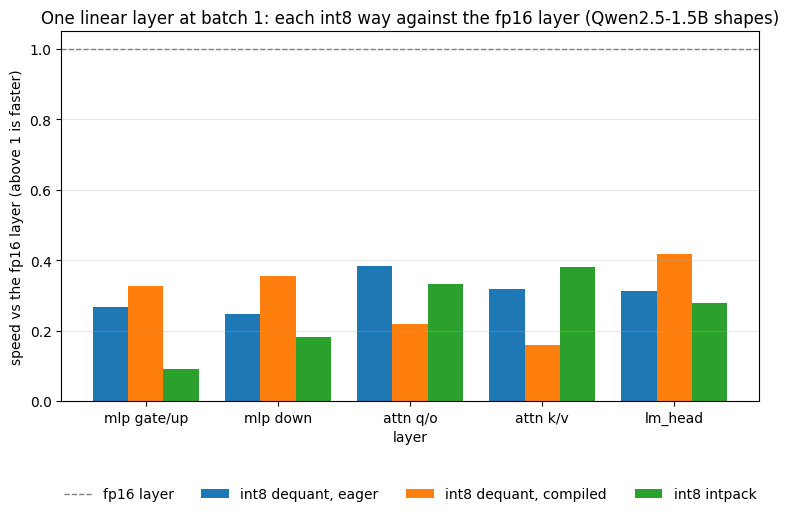

In [22]:
grouped_bar(LAYERS, {w: [pick(gate_df, l, w, "vs_fp") for l in LAYERS] for w in INT8_WAYS},
            f"One linear layer at batch 1: each int8 way against the fp16 layer ({MODEL_IDS[GATE_SIZE].split('/')[-1]} shapes)",
            "speed vs the fp16 layer (above 1 is faster)", hline=1.0, hline_label="fp16 layer", xlabel="layer", figsize=(9, 4.8), save="stage8_gate_speed")

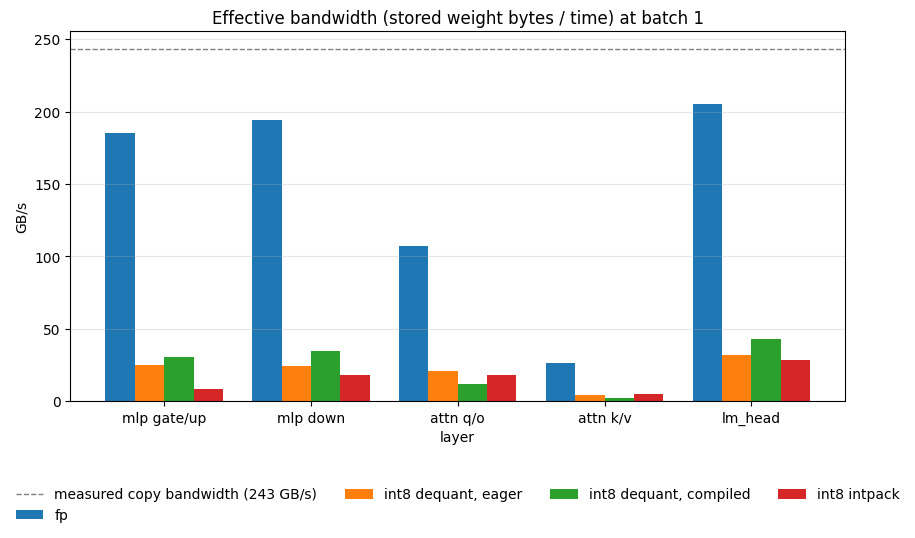

In [23]:
grouped_bar(LAYERS, {w: [pick(gate_df, l, w, "gbps") for l in LAYERS] for w in ["fp"] + INT8_WAYS},
            "Effective bandwidth (stored weight bytes / time) at batch 1", "GB/s", hline=COPY_BW, hline_label=f"measured copy bandwidth ({COPY_BW:.0f} GB/s)",
            xlabel="layer", figsize=(10, 4.8), save="stage8_gate_bandwidth")

**How to read it.**

- **The fp16 layer against the copy bandwidth.** On the large layers the fp16 matmul should sit near the copy bandwidth: it is limited by reading its weights. On the small `k/v` layer it will sit far below: a few thousand weights cannot keep the memory busy, and the time is the launch. That is the same launch-bound picture as Stages 2 and 7, seen on one layer.
- **The eager dequantize.** The effective bandwidth is computed from the *stored* int8 bytes, but the layer really moves five bytes per weight, so its bar should sit well below half of the fp16 bar, and its speed ratio well below one. If it does not, the conversion kernel is faster than the byte count says.
- **The compiled and the fused ways.** A ratio above one on the large layers means that way reads the weights as bytes. Compare it with the ideal: the bytes ratio is two (one byte against two), so a ratio near two means the layer is bandwidth-bound and fully fused, and a ratio between one and two means some of the time is not bandwidth.
- **A way marked unavailable** is a finding about this build and GPU, not a failure of the notebook. The table gives the reason.
- **Batch 16.** Feeding sixteen vectors at once still reads each weight once, so the bytes argument is unchanged, but the arithmetic grows. The ratios at batch 16 show how soon int8 stops paying.
- **The verdict is about one layer.** A whole decode step also has norms, attention, the KV cache and launches that no weight format touches, so a layer-level win is an upper bound on a step-level one. Section 5 measures the step.

---
## 2. The quantizer

**Goal:** understand exactly what int8 weight-only quantization stores, what it costs in error, and the difference between bytes *stored* and bytes *read per token*.

**Concept.** For a weight matrix `W` of shape `[out, in]`, **symmetric per-channel int8** keeps, for every output row `r`:

```
scale_r = max |W[r, :]| / 127
q[r, j] = round(W[r, j] / scale_r)      an integer in [-127, 127], stored as int8
W[r, j] ~ q[r, j] * scale_r             what the layer computes with
```

A linear layer then computes `y = (x @ q.T) * scale`: the scale applies to the *output* row, because it is constant along each row of `W`. The activations stay fp16. Only the weights shrink, and zero stays exactly zero.

Why one scale **per row** and not one for the whole matrix? Rows differ in size. One scale for the whole matrix is set by the largest weight anywhere, so a row whose weights are all small gets steps far too coarse for it and most of its weights round to zero. The control in section 3 measures this.

**Bytes stored are not bytes read.** A decode step reads every matrix once but only *one row* of the embedding table (a lookup). Qwen2.5-0.5B, 1.5B and 3B **tie** the embedding table to `lm_head`: the same tensor is the lookup table and the final matrix, and the final matmul reads all of it. If we quantize `lm_head`, the matmul reads int8, but the table must stay fp16 for the lookup. So we hold *both* an fp16 table and an int8 copy of it. Stored bytes fall by less than half, while bytes read per token fall by about half. Both numbers matter: stored bytes decide what fits in memory, read bytes decide the bandwidth floor.

In [24]:
# The whole idea on a 3 x 4 matrix, by hand
w = torch.tensor([[ 0.80, -0.20,  0.05,  0.40],
                  [ 0.02,  0.01, -0.03,  0.02],      # a row of small weights
                  [-1.60,  0.90,  0.30, -0.10]], dtype=torch.float32)
qw = quantize_weight(w)
print("scale per row:", qw.scale.tolist())
print("int8 weights:\n", qw.q)
print("dequantized:\n", dequantize(qw).round(decimals=4))
print("relative error per row:", [round(x, 4) for x in channel_errors(w, qw).tolist()])
one = quantize_weight(w, per_channel=False)
print("\none scale for the whole matrix:", one.scale.tolist())
print("int8 weights:\n", one.q)
print("relative error per row:", [round(x, 4) for x in channel_errors(w, one).tolist()], "<- the small row is rounded away")

scale per row: [0.006299212574958801, 0.000236220468650572, 0.012598425149917603]
int8 weights:
 tensor([[ 127,  -32,    8,   64],
        [  85,   42, -127,   85],
        [-127,   71,   24,   -8]], dtype=torch.int8)
dequantized:
 tensor([[ 0.8000, -0.2016,  0.0504,  0.4031],
        [ 0.0201,  0.0099, -0.0300,  0.0201],
        [-1.6000,  0.8945,  0.3024, -0.1008]])
relative error per row: [0.0039, 0.0032, 0.0032]

one scale for the whole matrix: [0.012598425149917603]
int8 weights:
 tensor([[  64,  -16,    4,   32],
        [   2,    1,   -2,    2],
        [-127,   71,   24,   -8]], dtype=torch.int8)
relative error per row: [0.0079, 0.2158, 0.0032] <- the small row is rounded away


In [25]:
def gib():
    return torch.cuda.memory_allocated() / 2**30


def load_model(size, quantized=False, path="dequant"):
    # load a model; returns (MiniQwen, bytes of GPU memory the loaded weights took)
    gc.collect(); torch.cuda.empty_cache()
    before = torch.cuda.memory_allocated()
    hf_m = AutoModelForCausalLM.from_pretrained(MODEL_IDS[size], dtype=dtype).to(device).eval()
    hf_m.requires_grad_(False)       # Hugging Face weights require grad; nothing here trains, and a graph hanging off one would hold memory
    ENV.setdefault("revisions", {})[MODEL_IDS[size]] = getattr(hf_m.config, "_commit_hash", None)
    m = MiniQwen(hf_m, max_pos=MAX_POS)
    if quantized:
        m = quantize_model(m, inplace=True, path=path)
    del hf_m
    gc.collect(); torch.cuda.empty_cache()
    return m, torch.cuda.memory_allocated() - before

KINDS = ["q_w", "k_w", "v_w", "o_w", "gate", "up", "down"]
model, _ = load_model("0.5B")
print(f"0.5B: {model.n_layers} layers, hidden {model.embed.shape[1]}, vocab {model.embed.shape[0]}; embedding tied to lm_head: {model.lm_head is model.embed}")

quantizer_rows = []
for kind in KINDS + ["lm_head"]:
    ws = [L[kind] for L in model.layers] if kind != "lm_head" else [model.lm_head]
    pc = torch.cat([channel_errors(w, quantize_weight(w, per_channel=True)) for w in ws])
    pt = torch.cat([channel_errors(w, quantize_weight(w, per_channel=False)) for w in ws])
    quantizer_rows.append({"model": "0.5B", "matrix": kind, "per_channel_row_err": pc.median().item(), "per_tensor_row_err": pt.median().item(),
                           "per_channel_worst_row": pc.max().item(), "per_tensor_worst_row": pt.max().item()})
quant_df = pd.DataFrame(quantizer_rows)
quant_df["per_tensor / per_channel"] = quant_df.per_tensor_row_err / quant_df.per_channel_row_err
quant_df.round(4)

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

0.5B: 24 layers, hidden 896, vocab 151936; embedding tied to lm_head: True


,model,matrix,per_channel_row_err,per_tensor_row_err,per_channel_worst_row,per_tensor_worst_row,per_tensor / per_channel
0,0.5B,q_w,0.0088,0.0324,0.0406,0.5400,3.7044
1,0.5B,k_w,0.0087,0.0211,0.0314,0.1903,2.4209
2,0.5B,v_w,0.0093,0.0160,0.0251,0.0442,1.7233
3,0.5B,o_w,0.0092,0.0446,0.0414,0.3864,4.8751
4,0.5B,gate,0.0081,0.0480,0.0537,0.1628,5.8950
5,0.5B,up,0.0081,0.0500,0.0582,0.2143,6.1577
6,0.5B,down,0.0099,0.0547,0.1047,0.2278,5.5001
7,0.5B,lm_head,0.0084,0.0303,0.0230,0.0486,3.6180


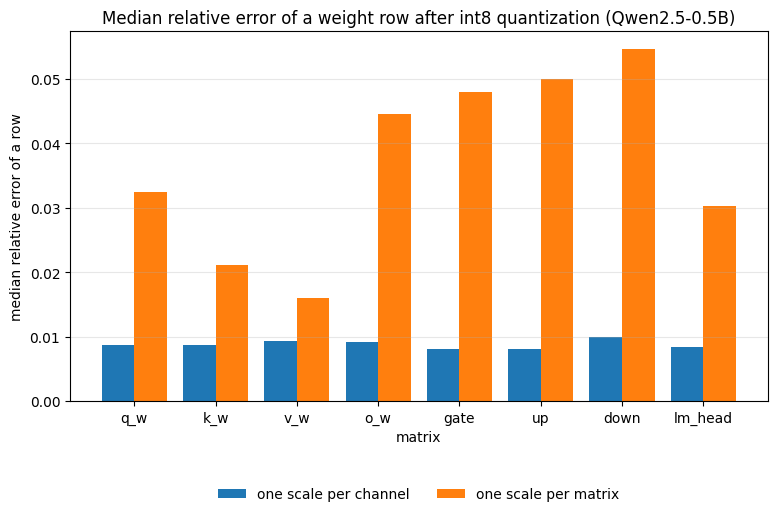

In [26]:
grouped_bar(list(quant_df.matrix), {"one scale per channel": list(quant_df.per_channel_row_err), "one scale per matrix": list(quant_df.per_tensor_row_err)},
            "Median relative error of a weight row after int8 quantization (Qwen2.5-0.5B)", "median relative error of a row", xlabel="matrix",
            figsize=(9, 4.8), save="stage8_scale_error")
assert (quant_df.per_tensor_row_err > quant_df.per_channel_row_err).all(), "a single scale was not worse than one per channel: the control shows nothing"

In [27]:
q8 = quantize_model(model)
stored16, stored8 = weight_bytes_stored(model), weight_bytes_stored(q8)
read16, read8 = weight_bytes_read(model), weight_bytes_read(q8)
print(f"0.5B bytes stored:        fp16 {stored16 / 2**30:.3f} GiB, int8 {stored8 / 2**30:.3f} GiB ({100 * stored8 / stored16:.0f}% of fp16)")
print(f"0.5B bytes read per token: fp16 {read16 / 2**30:.3f} GiB, int8 {read8 / 2**30:.3f} GiB ({100 * read8 / read16:.0f}% of fp16)")
print(f"floor at the measured copy bandwidth: fp16 {1000 * read16 / (COPY_BW * 1e9):.2f} ms, int8 {1000 * read8 / (COPY_BW * 1e9):.2f} ms per decode step")
del q8, model, pc, pt, ws          # later sections load their own models
gc.collect(); torch.cuda.empty_cache()
print(f"GPU memory in use now: {gib():.2f} GiB")

0.5B bytes stored:        fp16 0.920 GiB, int8 0.715 GiB (78% of fp16)
0.5B bytes read per token: fp16 0.920 GiB, int8 0.461 GiB (50% of fp16)
floor at the measured copy bandwidth: fp16 4.06 ms, int8 2.04 ms per decode step
GPU memory in use now: 0.01 GiB


**Takeaway.** A weight is one byte and a row scale. The error per row is bounded by half a step of that row. The fp16 embedding table and the int8 `lm_head` copy coexist, so the stored bytes drop by less than the read bytes. The last cell prints the **floor**: the time a decode step could not beat if it did nothing but read its weights at the measured bandwidth. Section 5 compares the measured steps with it.

---
## 3. Accuracy

**Goal:** measure what int8 weights cost in accuracy, and prove the measurement can detect a broken quantizer.

**What we measure** (Qwen2.5-0.5B and 1.5B, fp16 as the reference):

- **Logits.** On every position of a small fixed text set (`bench.texts.corpus`: four prose passages and four code snippets): the largest and the mean absolute difference, the mean KL divergence from the fp16 distribution, and how often the argmax is the same token.
- **Perplexity** on the same text. Small set, so use it to compare variants of one model, not as an absolute number.
- **Greedy output.** Two prompts of each Stage 6 workload, generated greedily, against the fp16 greedy output: how many are identical, and how much of the reference matches before the first difference.

**Two controls**, run through the same code:

1. **One scale for the whole matrix** instead of one per channel. Section 2 showed it is worse per row; here we see what it does to the model.
2. **A wrong scale**: every row gets its neighbour's scale (`torch.roll`). The matrices are still int8 and the code path is the same, but the model is wrong, so the metrics must say so. If they did not, they could not be trusted for the real quantizer.

> **Predict** (written before running anything below).
>
> - Per-channel int8 keeps the logits close: a small KL, the argmax the same at nearly every position, and a perplexity within a few percent of fp16.
> - Greedy outputs will mostly match fp16, but not every one: when two tokens are nearly tied, a small weight error flips the choice and the rest of the sequence follows. The matching prefix should be long, not necessarily the whole output.
> - One scale per matrix should be clearly worse than one per channel, because small rows lose their resolution.
> - The wrong scale should destroy the model: a perplexity many times fp16's.

In [28]:
TEXTS = workloads()
PROMPT_IDS = {name: [tok(t).input_ids for t in texts[:2]] for name, texts in TEXTS.items()}
CORPUS = [tok(t).input_ids for t in corpus()]
GEN_NEW = 48 if QUICK else 128
print({name: [len(p) for p in plist] for name, plist in PROMPT_IDS.items()}, "prompt tokens;", sum(len(c) for c in CORPUS), "tokens of text for logits and perplexity")


def wrong_scale(m):
    # every row gets its neighbour's scale: still int8, same code path, wrong model
    wm = quantize_model(m)
    for L in wm.layers:
        for k in KINDS:
            L[k] = QWeight(L[k].q, torch.roll(L[k].scale, 1), L[k].dtype)
    return wm


INT8_MAKERS = {"int8 per-channel": quantize_model, "int8 per-tensor (control)": lambda m: quantize_model(m, per_channel=False),
               "int8 wrong scale (control)": wrong_scale}


def all_logits(m):
    return torch.cat([m.forward(torch.tensor([ids], device=device), all_logits=True)[0].float().cpu() for ids in CORPUS])


def greedy(m, ids, n):
    return generate_cached(m, torch.tensor([ids], device=device), n)[0][0, len(ids):].tolist()


ACC_LOGITS, ACC_PPL, ACC_AGREE = [], [], []
for size in ACC_SIZES:
    fp, _ = load_model(size)
    print(f"{size} fp16 loaded: {gib():.2f} GiB of GPU memory in use")
    ref_logits = all_logits(fp)
    ppl_fp, n_tok = perplexity(fp, CORPUS)
    ACC_PPL.append({"model": size, "variant": "fp16", "ppl": ppl_fp, "tokens": n_tok})
    refs = {w: [greedy(fp, ids, GEN_NEW) for ids in plist] for w, plist in PROMPT_IDS.items()}
    for vname, make in INT8_MAKERS.items():                   # one variant at a time: the fp16 model plus one int8 copy
        qm = make(fp)
        print(f"  {vname}: {gib():.2f} GiB in use")
        lg = all_logits(qm)
        ACC_LOGITS.append({"model": size, "variant": vname, **logit_error(ref_logits, lg)})
        ACC_PPL.append({"model": size, "variant": vname, "ppl": perplexity(qm, CORPUS)[0], "tokens": n_tok})
        for w, plist in PROMPT_IDS.items():
            ACC_AGREE.append({"model": size, "variant": vname, "workload": w, **token_agreement(refs[w], [greedy(qm, ids, GEN_NEW) for ids in plist])})
        del qm, lg
        gc.collect(); torch.cuda.empty_cache()
    del fp, ref_logits
    gc.collect(); torch.cuda.empty_cache()
    print(f"{size} done")

logits_df, ppl_df, agree_df = pd.DataFrame(ACC_LOGITS), pd.DataFrame(ACC_PPL), pd.DataFrame(ACC_AGREE)
logits_df.round(4)

{'copy': [122, 104], 'code': [91, 81], 'open': [10, 10]} prompt tokens; 756 tokens of text for logits and perplexity


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

0.5B fp16 loaded: 0.93 GiB of GPU memory in use
  int8 per-channel: 1.40 GiB in use
  int8 per-tensor (control): 1.40 GiB in use
  int8 wrong scale (control): 1.40 GiB in use
0.5B done


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

1.5B fp16 loaded: 2.89 GiB of GPU memory in use
  int8 per-channel: 4.33 GiB in use
  int8 per-tensor (control): 4.32 GiB in use
  int8 wrong scale (control): 4.33 GiB in use
1.5B done


,model,variant,max_abs,mean_abs,kl,top1
0,0.5B,int8 per-channel,6.5469,0.1078,0.0042,0.9762
1,0.5B,int8 per-tensor (control),17.0430,0.4739,0.0989,0.8876
2,0.5B,int8 wrong scale (control),34.7188,3.3254,12.6277,0.0000
3,1.5B,int8 per-channel,4.2617,0.0748,0.0018,0.9802
4,1.5B,int8 per-tensor (control),23.9219,0.3576,0.0809,0.9233
5,1.5B,int8 wrong scale (control),37.7969,4.4191,12.8735,0.0000


In [29]:
ppl_df.round(3)

,model,variant,ppl,tokens
0,0.5B,fp16,5.116,748
1,0.5B,int8 per-channel,5.136,748
2,0.5B,int8 per-tensor (control),5.536,748
3,0.5B,int8 wrong scale (control),1777523.622,748
4,1.5B,fp16,4.465,748
5,1.5B,int8 per-channel,4.463,748
6,1.5B,int8 per-tensor (control),4.836,748
7,1.5B,int8 wrong scale (control),2203935.623,748


In [30]:
agree_df.round(3)

,model,variant,workload,identical,n,mean_prefix_share
0,0.5B,int8 per-channel,copy,0,2,0.883
1,0.5B,int8 per-channel,code,2,2,1.000
2,0.5B,int8 per-channel,open,0,2,0.137
3,0.5B,int8 per-tensor (control),copy,1,2,0.844
4,0.5B,int8 per-tensor (control),code,0,2,0.402
5,0.5B,int8 per-tensor (control),open,0,2,0.016
6,0.5B,int8 wrong scale (control),copy,0,2,0.000
7,0.5B,int8 wrong scale (control),code,0,2,0.000
8,0.5B,int8 wrong scale (control),open,0,2,0.000
9,1.5B,int8 per-channel,copy,1,2,0.602


In [31]:
# The controls must be able to fail, so check them and say what they showed
for size in ACC_SIZES:
    p = ppl_df[ppl_df.model == size].set_index("variant").ppl
    k = logits_df[logits_df.model == size].set_index("variant").kl
    assert np.isfinite(k["int8 per-channel"]) and np.isfinite(p["int8 per-channel"]), f"{size}: the int8 model produced non-finite values (fp16 overflow?)"
    assert p["int8 wrong scale (control)"] > 2 * p["fp16"], f"{size}: a wrong scale did not break the model, so the metrics cannot be trusted"
    shown = k["int8 per-tensor (control)"] > k["int8 per-channel"]
    print(f"{size}: perplexity fp16 {p['fp16']:.2f}, per-channel {p['int8 per-channel']:.2f}, per-tensor {p['int8 per-tensor (control)']:.2f}, wrong scale {p['int8 wrong scale (control)']:.1f}; "
          f"KL per-channel {k['int8 per-channel']:.5f} vs per-tensor {k['int8 per-tensor (control)']:.5f}"
          + ("" if shown else "   <- CONTROL NOT SHOWN: one scale per matrix was not worse than one per channel on this text"))

0.5B: perplexity fp16 5.12, per-channel 5.14, per-tensor 5.54, wrong scale 1777523.6; KL per-channel 0.00417 vs per-tensor 0.09894
1.5B: perplexity fp16 4.46, per-channel 4.46, per-tensor 4.84, wrong scale 2203935.6; KL per-channel 0.00182 vs per-tensor 0.08093


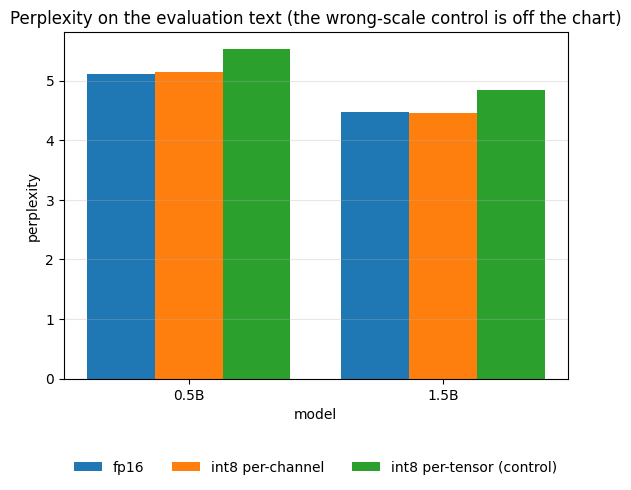

In [32]:
cats = ACC_SIZES
shown_variants = ["fp16", "int8 per-channel", "int8 per-tensor (control)"]
grouped_bar(cats, {v: [float(ppl_df[(ppl_df.model == s) & (ppl_df.variant == v)].ppl.iloc[0]) for s in cats] for v in shown_variants},
            "Perplexity on the evaluation text (the wrong-scale control is off the chart)", "perplexity", xlabel="model", save="stage8_accuracy")

**How to read it.**

- **The logits.** The KL divergence is the cleanest single number: it is zero for identical distributions and grows with the error. The argmax agreement says how often the model's top choice survives. Compare per-channel with per-tensor: if the per-tensor row is clearly larger, the per-channel scales are doing real work; if they are close, the rows of these matrices are close in size and the control showed little.
- **Perplexity.** A few percent above fp16 is normal for weight-only int8 with per-channel scales. The wrong-scale row must be far above fp16: the assertion above stops the notebook if it is not, because then the metric could not detect a broken quantizer.
- **Greedy agreement.** The mean matching prefix is more informative than "identical", because one near-tie flip ends a sequence's agreement even when the model is fine. A short matching prefix with a good perplexity would mean the outputs are fragile, not the model.
- **Non-finite values.** The first assertion checks the int8 model never produced an infinity or a NaN. The int8 product is larger than the real output by `127 / amax`, and fp16 stops at 65504, which is why `qlinear` pre-scales its input by a power of two. If that assertion ever fires, the safeguard was not enough for this model.
- **Small sample.** The text set is a few hundred tokens and two prompts per workload, so the differences between variants are what to read, not the absolute values.

---
## 4. Memory

**Goal:** measure what the weights take on the GPU, fp16 against int8, for three model sizes, and compare it with what section 2's formulas predict.

**Concept.** Per model, three numbers:

- **Stored bytes:** `weight_bytes_stored`, the weights the model holds.
- **Read per token:** `weight_bytes_read`, what one batch-1 decode step has to read (a tied embedding table is stored once but only one row of it is read).
- **Allocated:** `torch.cuda.memory_allocated` after loading, measured by loading each model fresh (and, for int8, quantizing in place and freeing the fp16 weights).

For a model whose embedding table is tied, with `M` parameters in the layer matrices and `E` in the embedding table, fp16 stores `2(M + E)` bytes. The int8 model stores `M` bytes of matrices, `2E` bytes of table for the lookup, and `E` bytes for the int8 `lm_head` copy, so `M + 3E`, plus scales. The saving is `M - E`, which is large only when the matrices dominate the table.

> **Predict** (written before running anything below).
>
> - Bytes read per token fall to about half of fp16's for every size: every matrix and the lm_head are int8.
> - Bytes *stored* fall by much less than half for the smallest model, because its embedding table is a large share of the weights, and by more for the bigger models, where the matrices dominate. The saving should grow with model size.
> - Allocated memory should track stored bytes, plus a small constant for the RoPE tables.

In [33]:
MEM = []
for size in SIZES:
    for variant in ("fp16", "int8"):
        m, alloc = load_model(size, quantized=(variant == "int8"))
        stored = weight_bytes_stored(m)
        assert alloc < 2 * stored, (f"{size} {variant}: {alloc / 2**30:.2f} GiB of GPU memory for {stored / 2**30:.2f} GiB of weights: "
                                    "something other than the weights is holding memory (an autograd graph, or fp16 matrices not freed after quantizing in place)")
        MEM.append({"model": size, "variant": variant, "stored_bytes": stored, "read_bytes": weight_bytes_read(m), "allocated_bytes": alloc})
        del m
        gc.collect(); torch.cuda.empty_cache()
mem_df = pd.DataFrame(MEM)
mem_df["stored_gib"] = mem_df.stored_bytes / 2**30
mem_df["read_gib"] = mem_df.read_bytes / 2**30
mem_df["allocated_gib"] = mem_df.allocated_bytes / 2**30
mem_df["allocated / stored"] = mem_df.allocated_bytes / mem_df.stored_bytes
mem_df[["model", "variant", "stored_gib", "read_gib", "allocated_gib", "allocated / stored"]].round(3)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/683 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

,model,variant,stored_gib,read_gib,allocated_gib,allocated / stored
0,0.5B,fp16,0.920,0.920,0.926,1.007
1,0.5B,int8,0.715,0.461,0.716,1.001
2,1.5B,fp16,2.875,2.875,2.877,1.001
3,1.5B,int8,1.874,1.439,1.876,1.001
4,3B,fp16,5.748,5.748,5.846,1.017
5,3B,int8,3.456,2.876,3.459,1.001


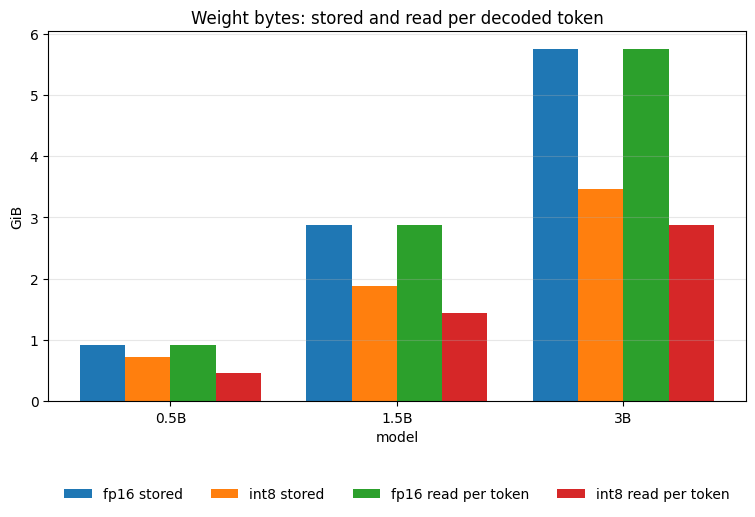

,model,stored int8 / fp16,read int8 / fp16,allocated int8 / fp16
0,0.5B,0.777,0.501,0.773
1,1.5B,0.652,0.501,0.652
2,3B,0.601,0.500,0.592


In [34]:
def mem(size, variant, col):
    return float(mem_df[(mem_df.model == size) & (mem_df.variant == variant)][col].iloc[0])

ratios = pd.DataFrame({"model": SIZES,
                       "stored int8 / fp16": [mem(s, "int8", "stored_bytes") / mem(s, "fp16", "stored_bytes") for s in SIZES],
                       "read int8 / fp16": [mem(s, "int8", "read_bytes") / mem(s, "fp16", "read_bytes") for s in SIZES],
                       "allocated int8 / fp16": [mem(s, "int8", "allocated_bytes") / mem(s, "fp16", "allocated_bytes") for s in SIZES]})
display_ratios = ratios.round(3)
grouped_bar(SIZES, {"fp16 stored": [mem(s, "fp16", "stored_gib") for s in SIZES], "int8 stored": [mem(s, "int8", "stored_gib") for s in SIZES],
                    "fp16 read per token": [mem(s, "fp16", "read_gib") for s in SIZES], "int8 read per token": [mem(s, "int8", "read_gib") for s in SIZES]},
            "Weight bytes: stored and read per decoded token", "GiB", xlabel="model", figsize=(9, 4.8), save="stage8_memory")
display_ratios

**How to read it.**

- **Read per token** should be close to half for every size: that is the number the bandwidth floor divides.
- **Stored** is where the embedding table shows. For the smallest model the ratio should be well above one half, and it should fall toward one half as the model grows. If it does not, something other than the table is being kept in fp16.
- **Allocated against stored.** They should agree up to the RoPE tables and allocator rounding (the last column is close to one). A large gap would mean the fp16 weights were not freed after quantizing in place, or that something else is holding memory; the loop above stops if allocated memory is more than twice the stored bytes.
- **What it buys.** Stored bytes decide what *fits*: a model that does not fit in fp16 may fit in int8 (exercise 5). Read bytes decide the bandwidth floor, which is what sections 1 and 5 are about.

---
## 5. Speed

**Goal:** measure the decode step time for fp16 and int8, eager and compiled, for three model sizes, and compare each with the bandwidth floor.

**Setup.** For each model size, a step is one token for each of `B` sequences on top of `CTX` cached tokens, argmax included (`decode_step_stats`), the median of `ITERS` repeated steps with the spread. Eager runs the ordinary forward pass at batch sizes `EAGER_BATCHES`. Compiled runs `torch.compile(model.forward, mode="reduce-overhead")`, which replays CUDA graphs, at batch 1 (the compile takes about half a minute to a minute per model and variant, timed separately, so only batch 1 is compiled). The **floor** is the bytes read per token over the measured copy bandwidth, and the **share** is the floor over the step time: how close the step gets to doing nothing but reading its weights. A step that is launch-bound has a small share.

For int8 the eager run uses the eager dequantize (`qlinear`'s `dequant` path). If `torch._weight_int8pack_mm` worked in the gate it is timed too, on the same int8 weights. The fp16 model is timed first and freed before the int8 runs, so a 3B model never has more than one large copy next to it on the 16 GB card.

**Concept.** From Stage 2 we know the shape of the answer to the fp16 question: the eager 0.5B step reached only a small share of the bandwidth ceiling, and the compiled step roughly a third. That is the part of the step that weight bytes cannot touch. Quantization can only remove the bandwidth part, so:

```
fp16 step  =  launch and other overhead  +  bytes16 / bandwidth
int8 step  =  launch and other overhead  +  bytes8 / bandwidth + any extra the int8 way adds
```

The saving is at most half of the second term, and only if the extra is zero. So the gain should grow with the model (its bytes term grows, the overhead barely does) and with removing the overhead (the compiled step).

> **Predict** (written before running anything below).
>
> - **Eager int8 is slower than eager fp16 at every size and batch**, because the eager dequantize writes and re-reads a fp16 copy of every matrix (section 1).
> - **Compiled int8 gains only if the compiler fuses the conversion.** If the gate said a compiled way beats fp16, compiled int8 should beat compiled fp16, and by more for 3B than for 0.5B: the 3B floor is a much larger part of its step.
> - **For 0.5B the gain should be small even when everything works,** because the compiled 0.5B step is still dominated by something other than reading weights (Stage 2 and Stage 7 both found that).
> - **At larger batch the gain should shrink,** because the extra arithmetic and the growing activations take over from the weight reads.
> - **The share of the floor will stay below one for every variant.** If an int8 step ever reaches a share above one, the byte count is wrong, so it also checks the arithmetic.

In [35]:
SPEED, WARMUP_S = [], {}


def speed_row(size, variant, mode, batch, st, bytes_read, ok=True, error=None):
    floor_ms = 1000 * bytes_read / (COPY_BW * 1e9)
    row = {"model": size, "variant": variant, "mode": mode, "batch": batch, "ok": ok, "error": error, "bytes_read": bytes_read, "floor_ms": floor_ms}
    if st is not None:
        row.update(st, share=floor_ms / st["median_ms"])
    return row


def time_model(size, vname, m, compile_it):
    # the eager step at every batch size, then (if asked) the compiled step at batch 1; a compile that fails is a result
    nbytes = weight_bytes_read(m)
    for b in EAGER_BATCHES:
        SPEED.append(speed_row(size, vname, "eager", b, decode_step_stats(m, b, CTX, iters=ITERS), nbytes))
    if compile_it:
        fwd = None
        try:
            fwd = compile_forward(m)
            t0 = time.perf_counter()
            decode_step_stats(m, 1, CTX, forward=fwd, iters=1, warmup=1)       # the first call compiles
            WARMUP_S[f"{size} {vname}"] = time.perf_counter() - t0
            SPEED.append(speed_row(size, vname, "compiled", 1, decode_step_stats(m, 1, CTX, forward=fwd, iters=ITERS), nbytes))
        except Exception as e:
            SPEED.append(speed_row(size, vname, "compiled", 1, None, nbytes, ok=False, error=f"{type(e).__name__}: {str(e)[:140]}"))
        del fwd
        from torch import _dynamo
        _dynamo.reset()                                                        # drop the compiled code, which holds on to the model
        gc.collect(); torch.cuda.empty_cache()


for size in SIZES:
    m16, _ = load_model(size)
    q = quantize_model(m16)                      # shares the embedding table and the norms; the int8 matrices are new
    print(f"{size}: fp16 and int8 loaded, {gib():.2f} GiB in use")
    time_model(size, "fp16", m16, size in COMPILE_SIZES)
    del m16                                      # not needed again: free the fp16 matrices before the int8 runs
    gc.collect(); torch.cuda.empty_cache()
    time_model(size, "int8", q, size in COMPILE_SIZES)
    if INTPACK_OK:
        set_path(q, "intpack")                   # the same int8 weights, multiplied the other way (eager only)
        time_model(size, "int8 intpack", q, False)
    print(f"{size} done")
    del q
    gc.collect(); torch.cuda.empty_cache()

speed_df = pd.DataFrame(SPEED)
speed_df[["model", "variant", "mode", "batch", "ok", "median_ms", "spread", "floor_ms", "share", "error"]].round(3)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

0.5B: fp16 and int8 loaded, 1.40 GiB in use
0.5B done


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

1.5B: fp16 and int8 loaded, 4.33 GiB in use
1.5B done


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

3B: fp16 and int8 loaded, 8.73 GiB in use
3B done


,model,variant,mode,batch,ok,median_ms,spread,floor_ms,share,error
0,0.5B,fp16,eager,1,True,21.906,0.028,4.064,0.186,None
1,0.5B,fp16,eager,4,True,22.035,0.035,4.064,0.184,None
2,0.5B,fp16,eager,16,True,22.672,0.028,4.064,0.179,None
3,0.5B,fp16,eager,64,True,30.392,0.009,4.064,0.134,None
4,0.5B,fp16,compiled,1,True,10.828,0.026,4.064,0.375,None
5,0.5B,int8,eager,1,True,36.450,0.042,2.036,0.056,None
6,0.5B,int8,eager,4,True,36.394,0.033,2.036,0.056,None
7,0.5B,int8,eager,16,True,36.304,0.030,2.036,0.056,None
8,0.5B,int8,eager,64,True,43.151,0.011,2.036,0.047,None
9,0.5B,int8,compiled,1,True,14.483,0.043,2.036,0.141,None


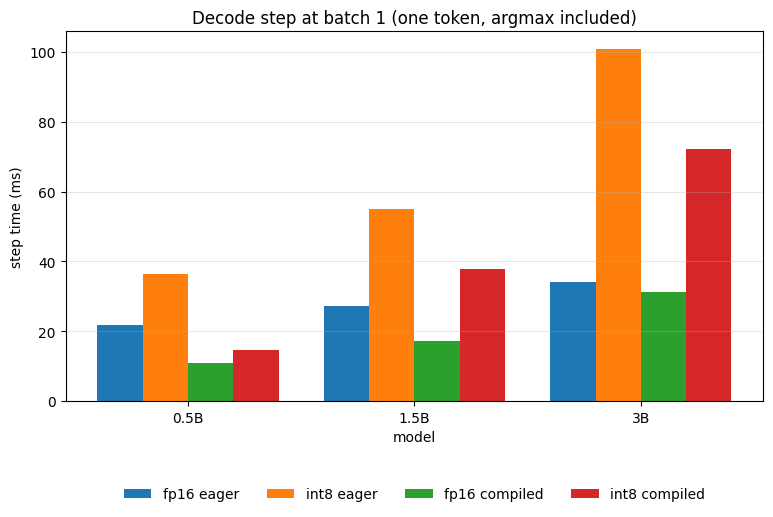

In [36]:
b1s = speed_df[(speed_df.batch == 1) & speed_df.ok]
def step(size, variant, mode, col="median_ms"):
    r = b1s[(b1s.model == size) & (b1s.variant == variant) & (b1s["mode"] == mode)]
    return float(r[col].iloc[0]) if len(r) else float("nan")

SERIES = [("fp16", "eager"), ("int8", "eager"), ("fp16", "compiled"), ("int8", "compiled")]
grouped_bar(SIZES, {f"{v} {m}": [step(s, v, m) for s in SIZES] for v, m in SERIES}, "Decode step at batch 1 (one token, argmax included)",
            "step time (ms)", xlabel="model", figsize=(9, 4.8), save="stage8_step_time")

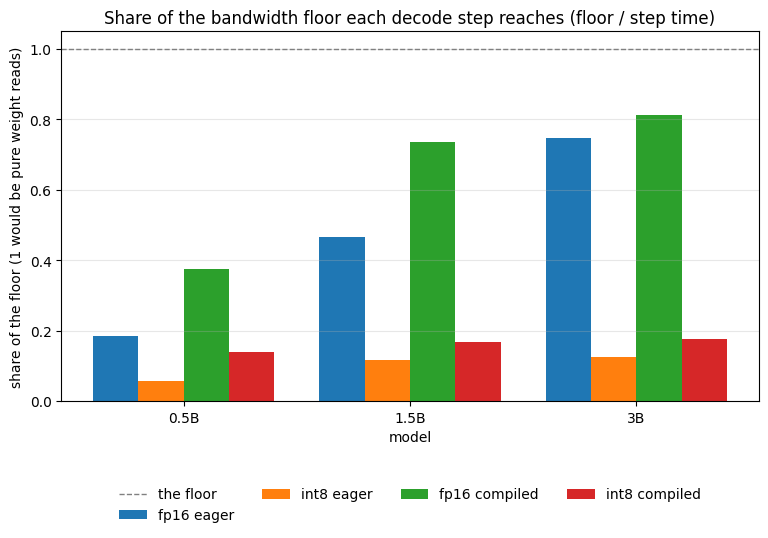

In [37]:
grouped_bar(SIZES, {f"{v} {m}": [step(s, v, m, "share") for s in SIZES] for v, m in SERIES},
            "Share of the bandwidth floor each decode step reaches (floor / step time)", "share of the floor (1 would be pure weight reads)",
            xlabel="model", hline=1.0, hline_label="the floor", figsize=(9, 4.8), save="stage8_bandwidth_share")
assert (speed_df[speed_df.ok].share.dropna() < 1.0).all(), "a decode step beat its own bandwidth floor: the byte count or the bandwidth is wrong"

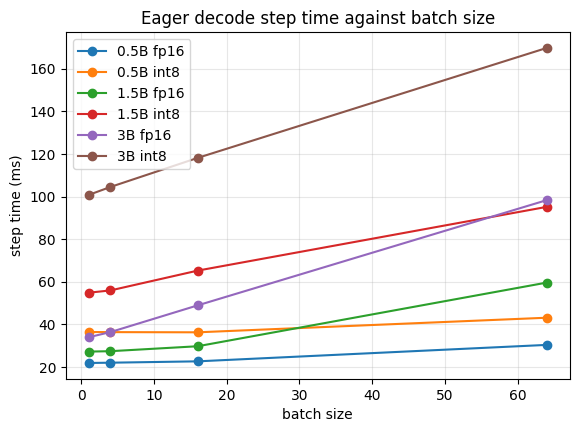

,model,mode,fp16 step (ms),int8 step (ms),fp16 / int8
0,0.5B,eager,21.906,36.450,0.601
1,0.5B,compiled,10.828,14.483,0.748
2,1.5B,eager,27.247,54.903,0.496
3,1.5B,compiled,17.246,37.946,0.454
4,3B,eager,33.989,100.812,0.337
5,3B,compiled,31.193,72.078,0.433


In [38]:
eager = speed_df[(speed_df["mode"] == "eager") & speed_df.ok & speed_df.variant.isin(["fp16", "int8"])].copy()
eager["line"] = eager.model + " " + eager.variant
line_groups(eager, "batch", "median_ms", "line", "Eager decode step time against batch size", "step time (ms)", xlabel="batch size",
            zero=False, dashed=(), save="stage8_step_vs_batch")
ratio_rows = []
for size in SIZES:
    for mode in ("eager", "compiled"):
        a, b = step(size, "fp16", mode), step(size, "int8", mode)
        ratio_rows.append({"model": size, "mode": mode, "fp16 step (ms)": a, "int8 step (ms)": b, "fp16 / int8": a / b if b == b and a == a else float("nan")})
pd.DataFrame(ratio_rows).round(3)

**How to read it.**

- **Eager int8 against eager fp16.** The ratio `fp16 / int8` below one means int8 is slower. The prediction was slower at every size, from the extra traffic of the eager dequantize.
- **Compiled int8 against compiled fp16.** This is the comparison that tests the idea. A ratio above one says the compiler fused the conversion and the step is far enough from launch-bound for the bytes to show. If a compile failed, the table says why, and the step-level answer for this build is "not available".
- **How the gain depends on size.** If bandwidth is part of the step, `fp16 / int8` should grow with the model. If it is flat or below one for every size, the step is dominated by something no weight format changes.
- **The share of the floor.** The step time over the floor says how much of the step is *not* reading weights at full bandwidth. The compiled int8 floor is half of the fp16 floor, so even a perfect fused kernel would leave the same non-bandwidth part in the step: that part is the ceiling on the gain, and the share shows how big it is.
- **Batch size.** In the eager step-time chart the lines for fp16 and int8 show how the gap changes with batch size. Because each weight is read once whatever the batch, the bandwidth term does not grow, and the arithmetic does, so the two lines should converge at a large batch.
- **Spread.** The spread column is the interquartile range over the median of the repeated steps. A step time with a large spread should not be compared at the second digit. Compile warm-up times are in the results file.

---
## 6. Back to Stage 7

**Goal:** close the loop with the previous stage on its own terms.

Stage 7 found that the draft model's step, run eagerly, cost nearly as much as the target's (`c` near the layers ratio), and that a CUDA graph cut it to about half. Its exercise 6 asked: *if the draft is made cheaper, which part of the step moves?* A quantized draft is the first thing to try. The notebook measures the cost ratio `c` = draft step / target step for the 0.5B draft in fp16 and int8, eager and graph, against the fp16 1.5B target step. It also checks the property that makes speculation safe: with a **quantized target**, the output of speculative decoding is still exactly that quantized model's own greedy output, because the target's checking pass uses the same quantized weights as its plain decode.

> **Predict** (written before running anything below).
>
> - In eager mode the int8 draft step is not cheaper than the fp16 one (the dequantize traffic), so `c` does not fall.
> - In graph mode the int8 draft step falls only as much as the bandwidth part of the step, which for a 0.5B model is small, so `c` falls little.
> - Speculative output with a quantized target equals that target's plain greedy output, whatever the draft.

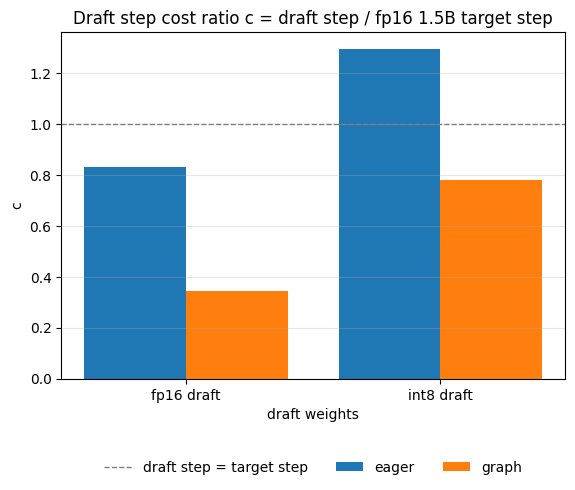

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

target workload  first_mismatch  logit_gap
  fp16     copy             NaN        NaN
  fp16     code             NaN        NaN
  fp16     open             NaN        NaN
  int8     copy             NaN        NaN
  int8     code             2.0      0.008
  int8     open             NaN        NaN


In [41]:
EXACT_ROWS, NEAR_TIE = [], 0.5     # NEAR_TIE: the largest logit gap between two tokens that still counts as an fp16 tie

if len(draft_df):
    grouped_bar(["fp16 draft", "int8 draft"], {mode: [float(draft_df[(draft_df.draft == d) & (draft_df["mode"] == mode)].c.iloc[0]) if len(draft_df[(draft_df.draft == d) & (draft_df["mode"] == mode)]) else float("nan")
                                                        for d in ("fp16", "int8")] for mode in ("eager", "graph")},
                "Draft step cost ratio c = draft step / fp16 1.5B target step", "c", hline=1.0, hline_label="draft step = target step", xlabel="draft weights",
                save="stage8_draft_cost")

    # Exactness. generate_speculative returns the target's own greedy choices, but its checking pass feeds a block of k + 1 tokens where
    # a plain step feeds one, and in fp16 the two matmul shapes round differently. An output can then differ from plain greedy exactly
    # where the target's top two tokens are nearly tied. Measure that: run the fp16 target (the control) and the int8 target on the same
    # prompts with the same draft, and at the first difference read the target's own logit gap between the two tokens.
    draft16, _ = load_model("0.5B")
    target16, _ = load_model("1.5B")
    target8 = quantize_model(target16)
    for tname, tm in (("fp16", target16), ("int8", target8)):
        for name in ("copy", "code", "open"):
            ids = PROMPT_IDS[name][0]
            plain = greedy(tm, ids, 32)
            spec, _ = generate_speculative(tm, ids, 32, k=4, proposer=DraftModel(draft16, 512))
            i = first_mismatch(plain, spec)
            gap = None
            if i is not None:
                logits = tm.forward(torch.tensor([ids + plain[:i]], device=device))[0].float()     # the target's own logits at that position
                gap = (logits[plain[i]] - logits[spec[i]]).abs().item()
            EXACT_ROWS.append({"target": tname, "workload": name, "first_mismatch": i, "logit_gap": gap})
    del draft16, target16, target8
    gc.collect()
    torch.cuda.empty_cache()
    exact_df = pd.DataFrame(EXACT_ROWS)
    print(exact_df.round(3).to_string(index=False))
    SPEC_EXACT = all(r["first_mismatch"] is None or r["logit_gap"] < NEAR_TIE for r in EXACT_ROWS if r["target"] == "int8")
    assert SPEC_EXACT, (f"the int8 target's speculative output differs from its plain greedy output where the two tokens are not nearly tied "
                        f"(logit gap of {NEAR_TIE} or more): that is not fp16 rounding")

**How to read it.**

- **`c` in each mode.** Compare the int8 row with the fp16 row in the same mode. A `c` that rises says the int8 way adds more work to the step than the smaller weights save, which is what section 1’s gate measured per layer; a `c` that merely stays level would say the step is not limited by weight bytes. Either way it answers Stage 7’s exercise 6 for this GPU and these ways.
- **If `graph` fell back to `static`.** The table's `mode` column says what actually ran, and `graph_error` in the results file says why.
- **Exactness.** The checking pass feeds a block of tokens where a plain step feeds one, and in fp16 the two matmul shapes round differently, so an output can differ from plain greedy where the target's top two tokens are nearly tied. The cell above runs the fp16 target as a control, reads the target's own logit gap at the first difference, and stops the notebook if an int8 difference has a gap of `NEAR_TIE` or more. It says nothing about whether the quantized model is as good as the fp16 one, which is section 3.

---
## 7. Save results

`results/stage8.json` holds everything needed to re-plot without re-running:

- `env` and `config`: GPU, library versions, model revisions, and every experiment parameter,
- `gate`: section 1 (every layer, batch and way, with the measured copy bandwidth),
- `quantizer`: section 2 (error per row, one scale per channel against one per matrix),
- `accuracy`: section 3 (logits, perplexity, greedy agreement, controls included),
- `memory`: section 4,
- `speed` and `compile_warmup_s`: section 5,
- `draft`: section 6.

Final published numbers should come from one consistent environment.

In [43]:
def records(df):
    # JSON has no NaN: missing values become null
    return df.round(5).astype(object).where(pd.notnull(df), None).to_dict(orient="records")

ENV["model"] = ", ".join(MODEL_IDS[s] for s in SIZES)
ENV["model_revision"] = "; ".join(f"{m.split('/')[-1]} {str(h)[:8]}" for m, h in ENV.get("revisions", {}).items())
out = {
    "env": {**ENV, "max_pos": MAX_POS},
    "config": {
        "seed": SEED, "quick": QUICK, "sizes": SIZES, "models": {s: MODEL_IDS[s] for s in SIZES}, "context": CTX, "iters": ITERS,
        "gate": {"batches": GATE_BATCHES, "model": MODEL_IDS[GATE_SIZE]},
        "speed": {"context": CTX, "batches": EAGER_BATCHES, "compile_sizes": COMPILE_SIZES},
        "accuracy": {"sizes": ACC_SIZES, "gen_new": GEN_NEW, "corpus_tokens": int(sum(len(c) for c in CORPUS))},
    },
    "gate": {"copy_bw_gbps": COPY_BW, "spec_bw_gbps": SPEC_BW, "go": bool(GATE_GO), "best_way": best_way, "best_ratio": None if best_ratio != best_ratio else best_ratio,
             "rows": records(gate_df)},
    "quantizer": records(quant_df),
    "accuracy": {"logits": records(logits_df), "perplexity": records(ppl_df), "agreement": records(agree_df)},
    "memory": records(mem_df),
    "speed": records(speed_df),
    "compile_warmup_s": WARMUP_S,
    "draft": {"rows": records(draft_df) if len(draft_df) else [], "speculative_exact": SPEC_EXACT, "exactness": EXACT_ROWS},
}
save_results("results/stage8.json", out)

saved results/stage8.json


### Figure inventory

Every figure was written to `results/` by the cell that produced it. This cell lists them and fails if one is missing.

In [44]:
FIGURES = {
    "stage8_gate_speed.png": "Speed of each int8 way of computing one layer against the fp16 layer (section 1)",
    "stage8_gate_bandwidth.png": "Effective bandwidth of each way against the measured copy bandwidth (section 1)",
    "stage8_scale_error.png": "Median relative error of a weight row, one scale per channel against one per matrix (section 2)",
    "stage8_accuracy.png": "Perplexity, fp16 against int8 with one scale per channel and per matrix (section 3)",
    "stage8_memory.png": "Weight bytes stored and read per decoded token, by model (section 4)",
    "stage8_step_time.png": "Decode step time at batch 1, fp16 and int8, eager and compiled (section 5)",
    "stage8_bandwidth_share.png": "Share of the bandwidth floor each decode step reaches (section 5)",
    "stage8_step_vs_batch.png": "Eager decode step time against batch size (section 5)",
}
if len(draft_df):
    FIGURES["stage8_draft_cost.png"] = "Draft cost ratio c with an fp16 and an int8 draft (section 6)"
missing = [f for f in FIGURES if not os.path.exists(f"results/{f}")]
assert not missing, f"missing figures: {missing}"
pd.DataFrame({"file": list(FIGURES), "what it shows": list(FIGURES.values())})

,file,what it shows
0,stage8_gate_speed.png,Speed of each int8 way of computing one layer ...
1,stage8_gate_bandwidth.png,Effective bandwidth of each way against the me...
2,stage8_scale_error.png,"Median relative error of a weight row, one sca..."
3,stage8_accuracy.png,"Perplexity, fp16 against int8 with one scale p..."
4,stage8_memory.png,Weight bytes stored and read per decoded token...
5,stage8_step_time.png,"Decode step time at batch 1, fp16 and int8, ea..."
6,stage8_bandwidth_share.png,Share of the bandwidth floor each decode step ...
7,stage8_step_vs_batch.png,Eager decode step time against batch size (sec...
8,stage8_draft_cost.png,Draft cost ratio c with an fp16 and an int8 dr...


---
## Publish results (and code, if this is the newest notebook) to GitHub (optional)

Set `PUSH = True` to push this run to your repo. The cell below is identical in every notebook of the series except `PUSH` and `COMMIT_MSG`. It calls `publish()` from `bench/publish.py`, which clones the repo, pulls, copies `results/` in, and copies `minivllm/` and `bench/` in only if this notebook's stage is at least the stage recorded in the repo (`minivllm/STAGE`). It then commits and pushes, printing git's output and raising an error if any git step fails. This is the newest notebook, so it publishes code as well as results. An older notebook rerun later pushes results only and cannot overwrite this code.

It needs a Kaggle secret named `minivllm-github-token` holding a GitHub token with write access. The repo name and git identity are constants at the top of `bench/publish.py`. The token is used only for the clone, pull and push commands and is not stored in the repo's git config.

In [46]:
PUSH = True                              # True: publish to GitHub at the end of the run
COMMIT_MSG = "Stage 8: weight-only int8 quantization"   # the only other line that differs between notebooks
FORCE_CODE = False                       # leave False: code is published automatically from the newest stage

if PUSH:
    from kaggle_secrets import UserSecretsClient
    from bench.publish import publish, SECRET_NAME
    publish(token=UserSecretsClient().get_secret(SECRET_NAME), message=COMMIT_MSG, force_code=FORCE_CODE)

Cloning into 'mini-vllm'...
remote: Enumerating objects: 1122, done.        
remote: Counting objects: 100% (254/254), done.        
remote: Compressing objects: 100% (193/193), done.        
remote: Total 1122 (delta 132), reused 156 (delta 57), pack-reused 868 (from 2)        
Receiving objects: 100% (1122/1122), 23.68 MiB | 21.05 MiB/s, done.
Resolving deltas: 100% (568/568), done.
Already up to date.
From https://github.com/chizkidd/minivllm
 * branch            HEAD       -> FETCH_HEAD
notebook stage 8, repo code stage 8: publishing code and results
[main 231b614] Stage 8: weight-only int8 quantization
 10 files changed, 1941 insertions(+)
 create mode 100644 results/stage8.json
 create mode 100644 results/stage8_accuracy.png
 create mode 100644 results/stage8_bandwidth_share.png
 create mode 100644 results/stage8_draft_cost.png
 create mode 100644 results/stage8_gate_bandwidth.png
 create mode 100644 results/stage8_gate_speed.png
 create mode 100644 results/stage8_memory.png
 cre

---
## 8. Summary and lessons

In [47]:
from IPython.display import Markdown, display

def show_table(rows, headers=("Metric", "Result", "Note")):
    esc = lambda c: str(c).replace("|", "\\|")   # a literal | would break the table
    out_ = ["| " + " | ".join(headers) + " |", "|" + "|".join(["---"] * len(headers)) + "|"]
    for r in rows:
        out_.append("| " + " | ".join([f"**{esc(r[0])}**"] + [esc(c) for c in r[1:]]) + " |")
    display(Markdown("\n".join(out_)))

rows = [("Gate", f"{'GO' if GATE_GO else 'NO-GO'}: best int8 way {best_way}, {best_ratio:.2f}x the fp16 layer on the large layers" if best_way else "no int8 way ran",
         f"copy bandwidth {COPY_BW:.0f} GB/s; unavailable: {', '.join(unavailable.index) if len(unavailable) else 'none'}")]
for size in ACC_SIZES:
    p = ppl_df[ppl_df.model == size].set_index("variant").ppl
    a = agree_df[(agree_df.model == size) & (agree_df.variant == "int8 per-channel")]
    rows.append((f"Accuracy, {size}", f"perplexity {p['fp16']:.2f} fp16, {p['int8 per-channel']:.2f} int8; {int(a.identical.sum())} of {int(a.n.sum())} greedy outputs identical",
                 f"one scale per matrix: {p['int8 per-tensor (control)']:.2f}; wrong scale: {p['int8 wrong scale (control)']:.0f}"))
for size in SIZES:
    rows.append((f"Memory, {size}", f"stored {mem(size, 'int8', 'stored_gib'):.2f} GiB int8 vs {mem(size, 'fp16', 'stored_gib'):.2f} fp16",
                 f"read per token {100 * mem(size, 'int8', 'read_bytes') / mem(size, 'fp16', 'read_bytes'):.0f}% of fp16"))
for r in ratio_rows:
    rows.append((f"Decode step, {r['model']}, {r['mode']}", f"fp16 {r['fp16 step (ms)']:.1f} ms, int8 {r['int8 step (ms)']:.1f} ms", f"fp16 / int8 = {r['fp16 / int8']:.2f}"))
if len(draft_df):
    c = {(r.draft, r.mode): r.c for r in draft_df.itertuples()}
    rows.append(("Draft cost ratio c", ", ".join(f"{k[0]} {k[1]} {v:.2f}" for k, v in c.items()), f"speculation with an int8 target exact: {SPEC_EXACT}"))
show_table(rows)

| Metric | Result | Note |
|---|---|---|
| **Gate** | NO-GO: best int8 way int8 dequant, compiled, 0.37x the fp16 layer on the large layers | copy bandwidth 243 GB/s; unavailable: none |
| **Accuracy, 0.5B** | perplexity 5.12 fp16, 5.14 int8; 2 of 6 greedy outputs identical | one scale per matrix: 5.54; wrong scale: 1777524 |
| **Accuracy, 1.5B** | perplexity 4.46 fp16, 4.46 int8; 3 of 6 greedy outputs identical | one scale per matrix: 4.84; wrong scale: 2203936 |
| **Memory, 0.5B** | stored 0.71 GiB int8 vs 0.92 fp16 | read per token 50% of fp16 |
| **Memory, 1.5B** | stored 1.87 GiB int8 vs 2.88 fp16 | read per token 50% of fp16 |
| **Memory, 3B** | stored 3.46 GiB int8 vs 5.75 fp16 | read per token 50% of fp16 |
| **Decode step, 0.5B, eager** | fp16 21.9 ms, int8 36.4 ms | fp16 / int8 = 0.60 |
| **Decode step, 0.5B, compiled** | fp16 10.8 ms, int8 14.5 ms | fp16 / int8 = 0.75 |
| **Decode step, 1.5B, eager** | fp16 27.2 ms, int8 54.9 ms | fp16 / int8 = 0.50 |
| **Decode step, 1.5B, compiled** | fp16 17.2 ms, int8 37.9 ms | fp16 / int8 = 0.45 |
| **Decode step, 3B, eager** | fp16 34.0 ms, int8 100.8 ms | fp16 / int8 = 0.34 |
| **Decode step, 3B, compiled** | fp16 31.2 ms, int8 72.1 ms | fp16 / int8 = 0.43 |
| **Draft cost ratio c** | fp16 eager 0.83, fp16 graph 0.34, int8 eager 1.30, int8 graph 0.78 | speculation with an int8 target exact: True |

### What we learned

#### Questions

- **Does any int8 way read fewer bytes per second than fp16?** (Section 1: the layer-level gate.)
- **What does int8 cost in accuracy, and can the metrics tell a broken quantizer from a good one?** (Section 3.)
- **What does it save?** (Section 4: stored against read bytes, by model size.)
- **Does it make a decode step faster, and where?** (Section 5: eager and compiled, against the bandwidth floor.)
- **Does it change the Stage 7 picture?** (Section 6: a quantized draft.)

#### Answers

- **Does any int8 way read fewer bytes per second than fp16?** No. On the large layers every int8 way was slower than the fp16 layer: the eager dequantize three to four times slower, the compiled one two to three times, the built-in int8 matmul slower still and far worse at batch 16. The gate was a no-go.
- **What does int8 cost in accuracy?** Little in perplexity (within half a percent of fp16, top-1 agreement 98%), more in greedy output (2 of 6 outputs identical at 0.5B, 3 of 6 at 1.5B; code matches, open text diverges early). One scale per matrix costs about 8% perplexity and 24 to 44 times the KL, and a wrong scale gives millions, so the controls can fail.
- **What does it save?** Bytes read per token halve at every size. Bytes stored fall to 78%, 65% and 60% of fp16 for 0.5B, 1.5B and 3B, because the embedding table stays in fp16.
- **Does it make a decode step faster?** No. Eager int8 is slower at every size and batch (1.7x at 0.5B to 3.0x at 3B at batch 1), and compiled int8 is slower too (1.3x, 2.2x, 2.3x). The fp16 3B step is already at about 75% to 81% of its bandwidth floor, which is where a fused kernel would matter.
- **Does it change the Stage 7 picture?** An int8 draft raises `c` (eager 0.83 to 1.30, graph 0.34 to 0.78). Speculation with the int8 target matches its own greedy output except at one fp16 near-tie.

### Next: the engine outside the notebook

Eight stages built the engine one idea at a time: a KV cache, batching, continuous scheduling, a paged cache, two kinds of speculative guesser over one generic verifier, and now a weight format that changes how many bytes a step reads. Every `%%writefile` module is now the final source. The next step is to leave the notebook: package the engine, add what a server needs (a real request loop on a real clock, end-of-sequence stopping, sampling), run it on a bigger GPU where decode is limited by reading the weights, where a draft model should be cheaper relative to its target and where a fused int8 kernel, which the three ways tried here were not, would have the most to gain, and compare it with an established serving system on the same traces and metrics.

### Exercises

1. **Group-wise scales.** Use one scale per group of 128 input weights instead of one per row. How much does the error per row fall, and what does it cost in stored bytes and in the matmul?
2. **Int4.** Pack two 4-bit weights per byte with group scales. The bytes halve again; what happens to perplexity, and to the speed of a way that must unpack them?
3. **A fused kernel.** Write the int8-to-fp16 conversion inside the matmul yourself (a Triton kernel), and compare it with the compiled and the `intpack` ways of section 1. How close to the copy bandwidth does it get?
4. **Quantize the activations too (W8A8).** Int8 matmuls use the tensor cores' integer path. When does the extra rounding of the activations show up in perplexity, and what does the speed gain depend on?
5. **A model that does not fit.** Qwen2.5-7B in fp16 does not fit on a T4, and in int8 it does. Load it layer by layer, quantizing on the GPU as you go, and measure its decode step against its floor.
6. **Quantize the KV cache.** At long contexts the cache, not the weights, is what a step reads. Quantize keys and values to int8 with a scale per head and token, and measure the error and the step time at a long context.
7. **Outliers.** Find the weight channels or activations with the largest values and test whether keeping them in fp16 improves the accuracy of the per-matrix control more than of the per-channel one.
8. **A quantized target with speculation.** Combine Stage 7 and this stage under a real load: does a quantized target move the best draft length or the winner between the n-gram lookup and the draft model?

### References

- Dettmers et al., *LLM.int8(): 8-bit Matrix Multiplication for Transformers at Scale*: https://arxiv.org/abs/2208.07339
- Frantar et al., *GPTQ: Accurate Post-Training Quantization for Generative Pre-trained Transformers*: https://arxiv.org/abs/2210.17323
- Lin et al., *AWQ: Activation-aware Weight Quantization for LLM Compression and Acceleration*: https://arxiv.org/abs/2306.00978
- Xiao et al., *SmoothQuant: Accurate and Efficient Post-Training Quantization for Large Language Models*: https://arxiv.org/abs/2211.10438
- PyTorch, *gpt-fast* (weight-only int8 with `torch.compile`): https://github.com/pytorch-labs/gpt-fast
- Williams, Waterman, Patterson, *Roofline: An Insightful Visual Performance Model*: https://dl.acm.org/doi/10.1145/1498765.1498785

---

# Appendix

Refer to the simple examples below to see where the bytes go. Nothing here is measured: it is the arithmetic of section 1 and section 2 evaluated.

## A.1. Bytes moved per weight, by way

The fp16 layer reads two bytes per weight. The int8 ways differ in what else they move. The scale per row is spread over `in` weights and is negligible for a large matrix.

In [48]:
rows = [("fp16 layer", 2, 0, 0), ("int8, eager dequantize then matmul", 1, 2, 2), ("int8, conversion fused into the matmul", 1, 0, 0)]
ways = pd.DataFrame(rows, columns=["way", "read int8", "write fp16 copy", "read fp16 copy"])
ways["fp16 weight read"] = [2, 0, 0]
ways["bytes per weight"] = ways["read int8"] + ways["write fp16 copy"] + ways["read fp16 copy"] + ways["fp16 weight read"]
ways["against fp16"] = ways["bytes per weight"] / 2
ways[["way", "bytes per weight", "against fp16"]]

,way,bytes per weight,against fp16
0,fp16 layer,4,2.0
1,"int8, eager dequantize then matmul",5,2.5
2,"int8, conversion fused into the matmul",1,0.5


## A.2. Stored and read bytes for a tied embedding, by the formulas of section 4

With `M` parameters in the layer matrices and `E` in a tied embedding table, per model size. The parameter counts are the published ones for the Qwen2.5 family, rounded, used only to show the shape of the formula; section 4 measures the real bytes.

In [49]:
params = pd.DataFrame({"model": ["0.5B", "1.5B", "3B"], "M (matrices, billions)": [0.36, 1.31, 2.77], "E (embedding, billions)": [0.136, 0.233, 0.311]})
M, E = params["M (matrices, billions)"], params["E (embedding, billions)"]
params["stored fp16 (GB)"] = 2 * (M + E)
params["stored int8 (GB)"] = M + 3 * E
params["stored int8 / fp16"] = params["stored int8 (GB)"] / params["stored fp16 (GB)"]
params["read int8 / fp16"] = (M + E) / (2 * (M + E))
params.round(3)

,model,"M (matrices, billions)","E (embedding, billions)",stored fp16 (GB),stored int8 (GB),stored int8 / fp16,read int8 / fp16
0,0.5B,0.36,0.136,0.992,0.768,0.774,0.5
1,1.5B,1.31,0.233,3.086,2.009,0.651,0.5
2,3B,2.77,0.311,6.162,3.703,0.601,0.5
